In [1]:
%%javascript

IPython.tab_as_tab_everywhere = function(use_tabs) {
    if (use_tabs === undefined) {
        use_tabs = true; 
    }

    // apply setting to all current CodeMirror instances
    IPython.notebook.get_cells().map(
        function(c) {  return c.code_mirror.options.indentWithTabs=use_tabs;  }
    );
    // make sure new CodeMirror instances created in the future also use this setting
    CodeMirror.defaults.indentWithTabs=use_tabs;

    };

IPython.tab_as_tab_everywhere()

<IPython.core.display.Javascript object>

In [2]:
import numpy as np
from scipy.sparse import coo_matrix
import os
import pandas as pd

from tqdm import tqdm

#from glove.kmerge import kmerge
from utils.chrono import Chrono

import pickle
import glob
import seaborn as sns

from matplotlib import rcParams
rcParams.update({'figure.autolayout': True})

from sklearn.ensemble import IsolationForest #1
from sklearn.cluster import DBSCAN #2

import geopandas as gpd
from geovoronoi import  coords_to_points, voronoi_regions_from_coords

from scipy.spatial import Delaunay

import matplotlib.pyplot as plt
from scipy import spatial
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle

from collections import defaultdict
import time
import random

from mpl_finance import candlestick_ohlc
import matplotlib.dates as mpl_dates 

def defaultPlotting():
	sns.set_context("paper")
	#sns.set(rc={"font.size":20,"axes.titlesize":20,"axes.labelsize":20})#'figure.figsize':(11.7,8.27),
	
defaultPlotting()

do_pickle=False
do_undirected=True

/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.4' currently installed).
  from pandas.core import (
/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/mpl_finance.py:16: DeprecationWarning: 



    Please use `mplfinance` instead (no hyphen, no underscore).

    To install: `pip install --upgrade mplfinance` 

   For more information, see: https://pypi.org/project/mplfinance/


  __warnings.warn('\n\n  ================================================================='+


In [3]:
## Time offset, Re-identification rate, and, add new stuuff to the profile.

## Pre-processing Trajectories

In [4]:
from datetime import datetime, timedelta

already_processed=True
treat_ts=True
shenzen_dataset=False #True
taka_dataset=False #True
mil_trajs=True #True

sample_senegal=True
rand_sample_senegal=False#False
sub_sampled_datasets=[1,2,5,10,25,50,100,200]

class trajAnonymizer:
	def __init__(self, trajs):
		self.trajs = trajs
		self.epoch = datetime(1970,1,1)
		self.week_ts = 1209600
		
	def getNTrajs(self, N, week_pair=0):
		idxs=[8, 20, 21, 9, 23, 22, 25, 19, 18, 24, 15, 1, 14, 2, 16, 17, 3, 7, 13, 12, 6, 10, 4, 5, 11]
		data = self.trajs[week_pair]
		if N != -1:
			data = data[data["user_id"]<=N]
		else:
			print("There are: ", len(set(data["user_id"])), "Trajs. in the datatset.")
		dts = data["timestamp"].values
		for i, dt in tqdm(enumerate(dts)):
			#print(dt)
			dts[i] = self.totimestamp(dt) # - (idxs[week_pair]-1)*self.week_ts
		data["timestamp"] = dts#data["timestamp"].apply(self.totimestamp)
		print("Got the trajectories!")
		#print(data)
		return data
	
	def getNTrajsRand(self, samp_trajs, week_pair=0):
		data = self.trajs[week_pair]
		data = data[data["user_id"].isin(samp_trajs)]
		dts = data["timestamp"].values
		for i, dt in tqdm(enumerate(dts)):
			#print(dt)
			dts[i] = self.totimestamp(dt)
		data["timestamp"] = dts#data["timestamp"].apply(self.totimestamp)
		print("Got the trajectories!")
		#print(data)
		return data
	
	def getMilTrajs(self):
		data = self.trajs[0]
		last_uid= max(list(data["user_id"]))
# 		print(data)
		for j in range(1, 3):
# 			print(last_uid)
			dt = self.trajs[j]
# 			print(dt)
			dt["user_id"]=dt["user_id"]+last_uid
			
			data = pd.concat([data, dt], ignore_index=True)
			last_uid= max(list(data["user_id"]))
		dt = self.trajs[3]
		dt = dt[dt["user_id"]<=50000]
		dt["user_id"]=dt["user_id"]+last_uid
# 		print(last_uid)
		
		data = pd.concat([data, dt], ignore_index=True)
		
		print(data)
		print("There are: ", len(set(data["user_id"])), "Trajs. in the datatset.")
		dts = data["timestamp"].values
		uds = data["user_id"].values
		
		with open('week_start_million.pickle', 'rb') as handle:
			week_data = pickle.load(handle)
		
		l=320000
		
		for i, dt in tqdm(enumerate(dts)):
			#print(dt)
			if uds[i]<=l:
				dts[i] = self.totimestamp(dt)
			elif uds[i]>l and uds[i]<=2*l:
				dts[i] = self.totimestamp(dt)-week_data[1][0]+week_data[0][0]
			elif uds[i]>2*l and uds[i]<=3*l:
				dts[i] = self.totimestamp(dt)-week_data[2][0]+week_data[0][0]
			elif uds[i]>3*l:
				dts[i] = self.totimestamp(dt)-week_data[3][0]+week_data[0][0]
		data["timestamp"] = dts#data["timestamp"].apply(self.totimestamp)
		print("Got the trajectories!")
		#print(data)
		return data
	
	def getMilTrajsCorrect(self):
		week=0
		with open('senegal_data_'+str(week)+'.pickle', 'rb') as handle:
			data=pickle.load(handle)
		last_uid= max(list(data["user_id"]))
# 		print(data)
		for j in range(1, 3):
# 			print(last_uid)
			with open('senegal_data_'+str(j)+'.pickle', 'rb') as handle:
				dt=pickle.load(handle)
# 			print(dt)
			dt["user_id"]=dt["user_id"]+last_uid
			
			data = pd.concat([data, dt], ignore_index=True)
			last_uid= max(list(data["user_id"]))
		with open('senegal_data_'+str(3)+'.pickle', 'rb') as handle:
			dt=pickle.load(handle)
		dt = dt[dt["user_id"]<=50000]
		dt["user_id"]=dt["user_id"]+last_uid
# 		print(last_uid)
		
		data = pd.concat([data, dt], ignore_index=True)
		
		print(data)
		print("There are: ", len(set(data["user_id"])), "Trajs. in the datatset.")
		print("Got the trajectories!")
		#print(data)
		return data
	
	def filter_anomalies(self, data, max_traj_length):
		count_id = data.user_id.value_counts().sort_index().values
		
		uids=[i for i in range(len(count_id)) if count_id[i] > max_traj_length]
		print(uids)
		data = data[data["user_id"] not in uids]
		
		return data
	
	def transformToKmergeData(self, data, max_traj_length):
		data = data.sort_values("user_id")
		count_id = data.user_id.value_counts().sort_index().values
		
# 		fig, ax = plt.subplots()
	
# 		df = pd.Series(count_id)
# 		print(count_id, df)
# 		sns.ecdfplot(df)
# 		plt.xlabel("Length of user trajs.")

# 		plt.savefig("trajectory_lengths.pdf")
		
		mask = count_id[:,None] > np.arange(count_id.max()) #count_id.max()
		vals = data[["x", "y", "timestamp", "site_id"]].values
		out_shp = mask.shape + (vals.shape[1],)
		out = np.full(out_shp, -1000)
		out[mask] = vals
		
		#ltrajs = out.shape[1]
		#out = np.delete(out, [i for i in range(max_traj_length, ltrajs)], axis=1)
		#print(out.shape, count_id[0], data.iloc[count_id[0]+1])
		
		#data=data[["x", "y", "timestamp"]].to_numpy()
		print("Converted the data to the K-merge shape.")
		return out
	
	def transformToKmergeData2(self, data):
		data = data.sort_values("user_id")
		count_id = data.user_id.value_counts().sort_index().values
		
		data = data[["x", "y", "timestamp", "site_id"]].values
		
		count=0
		fdata=[]
		for nsamp in count_id:
			fdata.append(data[count:count+nsamp])
			count=count+nsamp
		print("Converted the data to the K-merge shape.")
		return fdata
	
	def transformToKmergeData3(self, data): #Shenzen dataset
		data = data.sort_values("uid")
		count_id = data.uid.value_counts().sort_index().values
		
		data = data[["x", "y", "ts", "uid"]].values
		
		count=0
		fdata=[]
		for nsamp in count_id:
			fdata.append(data[count:count+nsamp])
			count=count+nsamp
		print("Converted the data to the K-merge shape.")
		return fdata
	
	def transformToKmergeData4(self, data): #Shenzen dataset
		data = data.sort_values("uid")
		count_id = data.uid.value_counts().sort_index().values
		
		data = data[["x", "y", "ts", "site_id"]].values
		
		count=0
		fdata=[]
		for nsamp in count_id:
			fdata.append(data[count:count+nsamp])
			count=count+nsamp
		print("Converted the data to the K-merge shape.")
		return fdata
	
	def totimestamp(self, idt):
		dt = datetime.strptime(idt, "%Y-%m-%d %H:%M:%S")
		td = dt - self.epoch
		return td.total_seconds()
		#return (td.microseconds + (td.seconds + td.days * 24 * 3600) * 10**6) / 1e6

def add_cloumns_data():
	global user_data
	for j in tqdm(range(len(files))):
		#user_data[j] = pd.concat([user_data[j].columns.to_frame().T, user_data[j]], ignore_index=True)
		user_data[j].columns = ["user_id", "timestamp", "site_id"]
		user_data[j] = user_data[j].merge(antennas, on='site_id', how="left")

def repeat_samples(idata):
	global tdata_full
	for traj in idata:
		udata=[]
		for samp in traj:
			#print([*samp, *samp])
			udata.append([*samp, *samp])
		#print(np.vstack(udata).shape)
		tdata_full.append(np.vstack(udata))#np.vstack(udata)

def repeat_samples2(idata):
	global tdata_full_shenzen
	for traj in idata:
		udata=[]
		for samp in traj:
			#print([*samp, *samp])
			udata.append([*samp, *samp])
		#print(np.vstack(udata).shape)
		tdata_full_shenzen.append(np.vstack(udata))#np.vstack(udata)

def repeat_samples3(idata):
	global tdata_full_civ
	tid=0
	for traj in idata:
		udata=[]
		for samp in traj:
			samp[-1]=tid
			#print([*samp, *samp])
			udata.append([*samp, *samp])
		#print(np.vstack(udata).shape)
		tdata_full_civ.append(np.vstack(udata))#np.vstack(udata)
		tid=tid+1

def repeat_samples4(idata):
	dt=[]
	j=0
	for traj in tqdm(idata):
		udata=[]
		for samp in traj:
			#print([*samp, *samp])
			if samp[0]>0:
				udata.append([*samp, *samp])
		#print(np.vstack(udata).shape)
		dt.append(np.vstack(udata))#np.vstack(udata)
		
		if j%60000==0:
			with open('senegal_trajs_million'+str(int(j/60000))+'.pickle', 'wb') as handle:
				pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
			
			del dt
			dt = []
		
		j=j+1
	with open('senegal_trajs_million'+str(int(j/60000)+1)+'.pickle', 'wb') as handle:
		pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)

if not already_processed:
	files = glob.glob('/Users/abhimishra/Downloads/d4d/senegal/SET2/SET*.CSV')

	user_data=[]
	for j in tqdm(range(len(files))):
		with open('senegal_data_' + str(j) + '.pickle', 'rb') as handle:
			user_data.append( pickle.load(handle) )

	loc_file = glob.glob('/Users/abhimishra/Downloads/d4d/senegal/ContextData/SITE_ARR_LONLAT.CSV')

	loc_data = pd.read_csv(loc_file[0])
	print(loc_data)

	with open('../SenegalData/senegal_antennas.pickle', 'rb') as handle:
		antennas = pickle.load(handle)

	print(antennas)
	
	add_cloumns_data()
	
	print(user_data[0])

	for j in tqdm(range(len(files))):
		user_data[j].drop(["lon", "lat", "arr_id", "wkt", "geometry"], axis=1, inplace=True)

	print(user_data[0])
	
	with open('senegal_data_processed.pickle', 'wb') as handle:
		pickle.dump(user_data, handle, protocol=pickle.HIGHEST_PROTOCOL)

if not mil_trajs and not taka_dataset:
	if treat_ts and not shenzen_dataset:
		with open('../SenegalData/senegal_data_processed.pickle', 'rb') as handle:
			p_user_data = pickle.load(handle)

if treat_ts and not shenzen_dataset and not taka_dataset:
	if not mil_trajs and not rand_sample_senegal:
		ta=trajAnonymizer(p_user_data)
		
		week=0
		
# 		data = ta.getNTrajs(-1, week)#-1, 0
		
# 		with open('senegal_data_'+str(week)+'.pickle', 'wb') as handle:
# 			pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)
		#data = ta.filter_anomalies(data, 1000)
		
		# 	#tdata= ta.transformToKmergeData(data, 1000)
		
		with open('senegal_data_'+str(week)+'.pickle', 'rb') as handle:
			data = pickle.load(handle)
		
		tdata= ta.transformToKmergeData2(data)
		
# 		del p_user_data
		
		chosen_k = 500#2

		tdata_full = []
		#print(tdata_full.shape)

		repeat_samples(tdata)
		del tdata
	
	elif rand_sample_senegal:
		ta=trajAnonymizer(p_user_data)
		
# 		j=1
# 		num=sub_sampled_datasets[j]*1000
		
# 		with open('senegal_data_rand_'+str(num)+'.pickle', 'rb') as handle:
# 			rand_samples = pickle.load(handle)

		num=1000 #50k
		
		with open('senegal_data_rand_'+str(num)+'.pickle', 'rb') as handle:
			rand_samples = pickle.load(handle)
		
		print(len(rand_samples))
		
# 		print(rand_samples)
		data = ta.getNTrajsRand(rand_samples, 0)#-1, 0, 2
		#data = ta.filter_anomalies(data, 1000)
		
		# 	#tdata= ta.transformToKmergeData(data, 1000)
		tdata= ta.transformToKmergeData2(data)
		
		del p_user_data
		
		chosen_k = 500#2

		tdata_full = []
		#print(tdata_full.shape)

		repeat_samples(tdata)
		del tdata
		
		print(len(tdata_full), tdata_full[-1][0])
	
	else:
# 		ta=trajAnonymizer(p_user_data)
		
# # 		data = ta.getMilTrajs()
# 		data = ta.getMilTrajsCorrect()
	
# 		with open('senegal_data_million.pickle', 'wb') as handle:
# 			pickle.dump(data, handle, protocol=pickle.HIGHEST_PROTOCOL)
		
# 		print(data)
		
# 		with open('senegal_data_million.pickle', 'rb') as handle:
# 			data = pickle.load(handle)
		
# 		ta=trajAnonymizer(data)
# 		tdata= ta.transformToKmergeData2(data)
		
# 		del data

# 		chosen_k = 500#2

# 		tdata_full = []
# 		#print(tdata_full.shape)

# 		repeat_samples4(tdata)
# 		del tdata

# 		print(tdata_full[-1][0], len(tdata_full))


		
		files=glob.glob("./senegal_trajs_million*")
		tdata_full=[]

		j=0
		for i in tqdm(range(len(files))):
			file=glob.glob("./senegal_trajs_million"+str(i)+"*")[0]
			with open(file, 'rb') as handle:
				dt=pickle.load(handle)

				for traj in dt:
					tdata_full.append(traj)
				del dt



		# 	with h5py.File("senegal_trajs_million_comp"+str(i)+".h5", 'w') as hf:
		# 		dname="stmc" + str(i)
		# 		hf.create_dataset(dname,  data=tdata_full)
		# 	del tdata_full

		# tdata_full=np.vstack(tdata_full)


		num_trajs = len(tdata_full)
		print(num_trajs, len(tdata_full), tdata_full[-1][0])

if shenzen_dataset:
	with open('shenzen_trajs.pickle', 'rb') as handle:
		shenzen_data = pickle.load(handle)

	ta1=trajAnonymizer(shenzen_data)
	tdata1= ta1.transformToKmergeData3(shenzen_data)

	tdata_full_shenzen = []

	repeat_samples2(tdata1)

	print(tdata_full_shenzen[-1][0])

	del shenzen_data, tdata1
	print(tdata_full_shenzen[0][0])

100%|█████████████████████████████████████████████████████████████████████| 18/18 [00:07<00:00,  2.54it/s]

1008169 1008169 [3.90547469e+05 1.55274350e+06 1.35827040e+09 9.63000000e+02
 3.90547469e+05 1.55274350e+06 1.35827040e+09 9.63000000e+02]


In [5]:
def repeat_samples3(idata):
	global tdata_full_civ
	tid=0
	for traj in idata:
		udata=[]
		for samp in traj:
# 			samp[-1]=tid
			#print([*samp, *samp])
			udata.append([*samp, *samp])
		#print(np.vstack(udata).shape)
		tdata_full_civ.append(np.vstack(udata))#np.vstack(udata)
		tid=tid+1

In [6]:
civ_processed = True #True
tdata_full_civ=[]

if not civ_processed:
	user_data = pd.read_csv('/home/tribe/mabhishe/myspace/civ/POS_SAMPLE_0.TSV', names=["uid", "ts", "site_id"], sep='\t')
	
	user_data=user_data[user_data["site_id"]!=-1]
# 	print(user_data["site_id"])
	
	antennas = pd.read_csv('/home/tribe/mabhishe/myspace/civ/ANT_POS.TSV', names=['site_id', 'lon', 'lat'], sep='\t')
	antennas = antennas.groupby(['lon','lat']).first().reset_index()

	antennas['wkt'] = antennas.apply(lambda r: 'POINT({} {})'.format(r['lon'], r['lat']), axis=1)
	antennas['geometry'] = gpd.GeoSeries.from_wkt(antennas['wkt'])
	antennas = gpd.GeoDataFrame(antennas).set_crs('epsg:4326').to_crs('epsg:2165')

	antennas['x'] = antennas.geometry.apply(lambda p: p.x)
	antennas['y'] = antennas.geometry.apply(lambda p: p.y)
	
# 	user_data.columns = ["user_id", "timestamp", "site_id"]
	user_data = user_data.merge(antennas, on='site_id', how="left")
# 	print(user_data)
	
	user_data.drop(["lon", "lat", "wkt", "geometry"], axis=1, inplace=True) #, "site_id"
	user_data=user_data.dropna().reset_index(drop=True)
	
	print(user_data)
	
	ta1=trajAnonymizer(user_data)
	dts = user_data["ts"].values
	for i, dt in tqdm(enumerate(dts)):
		#print(dt)
		dts[i] = ta1.totimestamp(dt)
	user_data["ts"] = dts
	tdata1= ta1.transformToKmergeData4(user_data)

	tdata_full_civ = []

	repeat_samples3(tdata1)

	print(tdata_full_civ[-1][0])

	del user_data, tdata1

In [7]:
if taka_dataset:
	# Load the list of DataFrames from the pickle file
	with open("tdata_full_taka.pkl", "rb") as file:
		tdata_full_taka = pickle.load(file)
	
	print(tdata_full_taka[0][0])
	print(tdata_full_taka[-1][0])

In [8]:
# # vals = [samp[1] for user in tdata_full_shenzen for samp in user]
# tm=[]
# count=0

# for user in tqdm(tdata_full):
# 	vals=[]
# 	for samp in user:
# 		vals.append(samp[1])
# 	vals = sorted(vals)
# 	tm.append(np.mean(np.diff(vals)))
# 	count=count+len(user)

# print(np.mean([vl for vl in tm if vl>0]), count)

In [9]:
# # vals = [samp[1] for user in tdata_full_shenzen for samp in user]
# tm=[]
# count=0

# for user in tqdm(tdata_full_taka):
# 	vals=[]
# 	for samp in user:
# 		vals.append(samp[2])
# 	vals = sorted(vals)
# 	tm.append(np.mean(np.diff(vals)))
# 	count=count+len(user)

# print(np.mean([vl for vl in tm if vl>0]), count)

In [10]:
# if shenzen_dataset:
# 	tdata_full_shenzen = tdata_full_shenzen[tdata_full_shenzen[:, 2].argsort()]  # sorting by 2nd col, tmin
# 	tdata_full_shenzen = tdata_full_shenzen[tdata_full_shenzennzen[:, 2]>0]  # get rid of points that were actually just padding

In [11]:
def getTrajAreaSenegal():
	area_dict_trajs = defaultdict(int)
	
	with open('voronoi_area_senegal.pickle', 'rb') as handle:
		voronoi_areas = pickle.load(handle)
	
	idd=0
	for traj in tqdm(tdata_full):
		this_area=0
		for sample in traj:
			this_area=this_area+voronoi_areas[int(sample[3])]
# 			print(voronoi_areas[int(sample[3])], len(traj))
		area_dict_trajs[idd]= (this_area/len(traj))/10**6
# 		print(area_dict_trajs[idd])
		idd=idd+1
		
# 		print(this_area, len(traj), area_dict_trajs)
	
# 	print(area_dict_trajs)
	
	with open('senegal_trajs_area.pickle', 'wb') as handle:
		pickle.dump(area_dict_trajs, handle, protocol=pickle.HIGHEST_PROTOCOL)
	
	areas = np.array(list(voronoi_areas.values()))/10**6
	
# 	print(areas)

	fig, axi = plt.subplots(1, 1)

# 		print(dt)
	df = pd.DataFrame(areas)
# 		print(df)
	df.columns=["size"]

	sns.histplot(data=df)

	plt.xlabel("Area($Km^2$)")
	plt.ylabel("Count")
	
	axi.get_legend().remove()
	
# 	plt.xlim([0, 1500])
	plt.savefig('voronoi_areas_senegal_km2.pdf')

In [12]:
def getTrajAreaCiv():
	area_dict_trajs = defaultdict(int)
	
	with open('voronoi_area_civ.pickle', 'rb') as handle:
		voronoi_areas = pickle.load(handle)
	
	idd=0
	for traj in tqdm(tdata_full_civ):
		this_area=0
		for sample in traj:
# 			print(sample)
			this_area=this_area+voronoi_areas[int(sample[3])]
# 			print(voronoi_areas[int(sample[3])], len(traj))
		area_dict_trajs[idd]= (this_area/len(traj))/10**6
# 		print(area_dict_trajs[idd])
		idd=idd+1
		
# 		print(this_area, len(traj), area_dict_trajs)
	
# 	print(area_dict_trajs)
	
	with open('civ_trajs_area.pickle', 'wb') as handle:
		pickle.dump(area_dict_trajs, handle, protocol=pickle.HIGHEST_PROTOCOL)
	
	areas = np.array(list(voronoi_areas.values()))/10**6
	
# 	print(areas)

	fig, axi = plt.subplots(1, 1)

# 		print(dt)
	df = pd.DataFrame(areas)
# 		print(df)
	df.columns=["size"]

	sns.histplot(data=df)

	plt.xlabel("Area($Km^2$)")
	plt.ylabel("Count")
	
	axi.get_legend().remove()
	
# 	plt.xlim([0, 1500])
	plt.savefig('voronoi_areas_civ_km2.pdf')

In [13]:
# getTrajAreaSenegal()
# getTrajAreaCiv()

## Analyse Anonymised data

In [14]:
from multiprocessing import Process
from multiprocessing import Pool, freeze_support

class CharacterizeAnonimisation:
	def __init__(self, scenario, fname, trajs, k, s_size=0):
		self.scenario = scenario
		self.fname=fname
		self.trajs=trajs
		self.k=k
		self.subsample_size=s_size
		
		if self.scenario=="Partial" or self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			with open('senegal_data_rand_'+str(self.subsample_size)+'.pickle', 'rb') as handle:
				self.rand_samples = list(pickle.load(handle))
		
		if self.scenario=="Partial" or self.scenario=="Senegal" or self.scenario=="Million" or self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			with open('senegal_trajs_area.pickle', 'rb') as handle:
				self.area_dict_trajs=pickle.load(handle)
	
	def obtainGTrajs(self):
		return self.gtrajs
	
	def getGTrajs(self):
		files = glob.glob(self.fname)

		self.gtrajs=defaultdict(list)
		
		self.indexes=[]
		if self.scenario=="Million":
			self.num_cores=1000#32
		else:
			self.num_cores=32
		
		if self.scenario=="Partial":
			self.num_trajs=len(self.trajs) #len(self.rand_samples)#self.subsample_size 5000
		else:
			self.num_trajs=len(self.trajs)
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			self.num_cores=1
			self.num_trajs=1000
		
# 		print(files, self.num_trajs)

		for i in range(self.num_cores):
			il = int(self.num_trajs/self.num_cores)
			self.indexes.append([j for j in range(i*il, i*il+il)])

		if self.indexes[-1][-1]!=self.num_trajs-1:
			self.indexes.append([j for j in range(self.indexes[-1][-1]+1, self.num_trajs)])
		
		print(self.num_trajs)
		
		count=0
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			k=0
			for j in tqdm(range(len(files))):
				with open(files[j]) as f:
					for line in f:
						if line != '\n':
							self.gtrajs[j].append( [int(val) for val in line.split()] )
							count=count+1
			print(count)
		else:
			for j in tqdm(range(len(files))):
				with open(files[j]) as f:
# 					print(files[j])
					if self.scenario=="Partial":
						this_index = int(files[j].split("/")[2].split(".")[0].split("_")[3][1:])
					else:
						this_index = int(files[j].split("/")[1].split(".")[0].split("_")[3][1:])

					for idx in self.indexes:
						if idx[0]==this_index:
							this_index=idx
							break

	# 				print([val[0] for val in self.indexes])
# 					print(this_index)
					k=0
					for line in f:
						if line == '\n':
							k=k+1
						else:
# 							print(this_index[k])
							self.gtrajs[this_index[k]].append( [int(val) for val in line.split()] )
						count=count+1

	# 		with open('dz_fault.pickle', 'rb') as handle:
	# 			ft = pickle.load(handle)

	# 		if self.scenario=="Million":
	# 			ston=set()
	# 			for val in tqdm(ft):
	# 				if val[0]!=val[1]:
	# 					ston.add(val[0])

	# 			ston=list(ston)

	# 			for val in ston:
	# 				self.gtrajs[val]=-1

	# 			ntraj=defaultdict(list)

	# 			j=0
	# 			for gt in self.gtrajs.keys():
	# 				if self.gtrajs[gt]!=-1:
	# 					ntraj[j]=self.gtrajs[gt]
	# 					j=j+1

	# 			del self.gtrajs

	# 			self.gtrajs=ntraj
# 			pt = list(set([i for i in range(self.num_trajs)]).difference(set(list(self.gtrajs.keys()))))
# 			with open("miss_trajs10.pickle", 'wb') as handle:
# 				pickle.dump(pt, handle, protocol=pickle.HIGHEST_PROTOCOL)

	def filterGTrajs(self):
		with open('community_partitions_million.pickle', 'rb') as handle:
			self.partition_million = pickle.load(handle)
		
		self.count4=defaultdict(int)
		for com in set(self.partition_million.values()):
			list_nodes = [nodes for nodes in self.partition_million.keys() if self.partition_million[nodes] == com]
# 			print(len(list_nodes))
			if len(list_nodes)>1:
				self.count4[com]=len(list_nodes)

		print(self.count4)
		self.plot_dist(list(self.count4.values()), "community sizes", "community_sizes_million")
	
	def checkSampleEnclosed(self, gtr, traj):
		for sp in traj:
			present=False
			for gs in gtr:
				if  sp[0]>=gs[2] and sp[0]<=gs[5]:
# 					print(gs)
					xmin=min(gs[0], gs[3])
					xmax=max(gs[0], gs[3])
		
					ymin=min(gs[1], gs[4])
					ymax=max(gs[1], gs[4])
					
					if sp[1]>=xmin and sp[1]<=xmax and sp[2]>=ymin and sp[2]<=ymax:
						present=True
			if present==False:
				return present
		return present
	
	def checkSampleEnclosed2(self, gtr, sp):
		present=False
		for gs in gtr:
			if  sp[0]>=gs[2] and sp[0]<=gs[5]:
# 				print(gs)
				if sp[1]>=gs[0] and sp[1]<=gs[3] and sp[2]>=gs[1] and sp[2]<=gs[4]:
					present=True
		return present
	
	def findDeletedSamples(self):
		present=0
		tot=0
		
		for tr1 in tqdm(self.trajs):
			for sp in tr1:
				for key in self.gtrajs.keys():
					for gtr in self.gtrajs[key]:
# 						print(key, len(self.gtrajs[key]))
						for gs in gtr:
							if  sp[0]>=gs[2] and sp[0]<=gs[5]:
				# 				print(gs)
								if sp[1]>=gs[0] and sp[1]<=gs[3] and sp[2]>=gs[1] and sp[2]<=gs[4]:
									present=present+1
				tot=tot+1
		return ((tot-present)/tot)*100 
	
	def checkDataCorrectness(self):
# 		print(len(list(self.gtrajs.keys())), self.gtrajs[list(self.gtrajs.keys())[1]])
		traj_rand = random.sample(range(0, self.num_trajs), 10)
		print(traj_rand)
		
		overlap=[]
		for t in traj_rand:
			if self.scenario=="Partial":
				traj=self.trajs[self.rand_samples[t]]
			else:
				traj=self.trajs[t]
			traj=[(int(sp[2]), int(sp[0]), int(sp[1])) for sp in traj]
# 			traj=[(sp[2], sp[0], sp[1]) for sp in traj]
			traj=sorted(traj, key=lambda y:y[0])
			
# 			print(traj)

			count=0
			flag=False
			for key in self.gtrajs.keys():
				gtr=self.gtrajs[key]
				count=count+int( self.checkSampleEnclosed(gtr, traj) )
# 				print(sp, count)
# 				print(gtr)
# 				break
			overlap.append(count)
			
		print(sorted(overlap))
		
# 		overlap=[]
# 		for t in traj_rand:
# 			traj=self.trajs[t]
# 			traj=[(sp[2], sp[0], sp[1]) for sp in traj]
# 			traj=sorted(traj, key=lambda y:y[0])
			
# 			for sp in traj:
# 				count=0
# 				flag=False
# 				for key in self.gtrajs.keys():
# 					gtr=self.gtrajs[key]
# 					count=count+int( self.checkSampleEnclosed2(gtr, sp) )
# 	# 				print(sp, count)
# 				overlap.append(count)
			
# 		print(sorted(overlap))
	
	def plot_dist(self, dt, xlab, name, ylab=""):
		fig, axi = plt.subplots(1, 1)

# 		print(dt)
		df = pd.DataFrame(dt)
# 		print(df)
		df.columns=["size"]

		sns.ecdfplot(data=df)

		plt.xlabel(xlab)
		if len(ylab):
			plt.ylabel(ylab)
		#plt.legend()
		if xlab=="Spatial accuracy(Km)":
			plt.xlim([0, 40])
		elif xlab=="Spatial normalised accuracy":
			plt.xlim([0, 25])
		elif xlab=="Temporal accuracy(Min.)":
			plt.xlim([0, 1200])
		axi.get_legend().remove()
		plt.savefig(str(name) + str(self.k) + '.pdf')
	
	def plot_dist_mult(self, dt, xlab, name, ylab=""):
		fig, axi = plt.subplots(1, 1)
		
		markers=[',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		
		if xlab=="Spatial accuracy($Km^2$)":
			bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
		elif xlab=="Spatial normalised accuracy":
			bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
		elif xlab=="Temporal accuracy(Hr.)":
			bins_t=[30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

		if self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
			sub_labels=["Our solution 1000", "Our solution 2000", "Glove Strict 1000", "Glove Strict 2000"]#, "Glove Loose 1000", "Glove Loose 2000"]
		else:
			sub_labels=["Merge cost", "Proxy-metric only"] #["sen-1k", "sen-2k", "sen-5k", "sen-10k", "sen-25k", "sen-50k", "sen-100k", "sen-200k", "sen-300k", "sen-1M"]#precise?
		
		clrs = sns.color_palette("coolwarm", len(sub_labels))
		
# 		vals=[]
		
		for i, lev in enumerate(sub_labels):
# 			sns.ecdfplot(dt[i], color=clrs[i], label=lev, linestyle="--", marker=markers[i])
			# getting data of the histogram
			count, bins_count = np.histogram(dt[i], bins=bins_t)

			# finding the PDF of the histogram using count values
			pdf = count / sum(count)
			
# 			print(len(dt[i]))

			cdf = np.cumsum(pdf)
	
			plt.plot(np.array(bins_count[1:-1]).astype(str), cdf[:-1], color=clrs[i], label=lev, linestyle="--", marker=markers[i]) #color="red", 
		
# 		with open('avals_sachit'+xlab+'.pickle', 'wb') as handle:
# 			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)

		plt.xlabel(xlab)
		plt.ylabel("CDF")
		
		plt.ylim([0, 1])
		
		if xlab=="Spatial accuracy($Km^2$)":
			axi.xaxis.set_ticklabels(bins_t[1:-1])
		elif xlab=="Spatial normalised accuracy":
			axi.xaxis.set_ticklabels(bins_t[1:-1])
		elif xlab=="Temporal accuracy(Hr.)":
			axi.xaxis.set_ticklabels(np.array(bins_t[1:-1])/60)
		
		plt.legend()
		plt.xticks(rotation=45)
		plt.rcParams["font.size"] = "27"
		plt.savefig(str(name) + str(self.k) + '.pdf',  bbox_inches='tight')
		
		fig, axi = plt.subplots(1, 1)
		
		clrs = sns.color_palette("coolwarm", len(sub_labels))
		
		for i, lev in enumerate(sub_labels):
			# getting data of the histogram
			count, bins_count = np.histogram(dt[i], bins=bins_t)

			# finding the PDF of the histogram using count values
			pdf = count / sum(count)
			
			plt.plot(np.array(bins_count[1:-1]).astype(str), pdf[:-1], color=clrs[i], label=lev, linestyle="--", marker=markers[i]) #color="red", 

		
		plt.xlabel(xlab)
		plt.ylabel("PDF")
		
# 		plt.ylim([0, 1])
		
# 		axi.xaxis.set_ticks(bins_t)
		if xlab=="Spatial accuracy($Km^2$)":
			axi.xaxis.set_ticklabels(bins_t[1:-1])
		elif xlab=="Spatial normalised accuracy":
			axi.xaxis.set_ticklabels(bins_t[1:-1])
		elif xlab=="Temporal accuracy(Hr.)":
			axi.xaxis.set_ticklabels(np.array(bins_t[1:-1])/60)
		plt.legend()
		plt.xticks(rotation=45)
		plt.rcParams["font.size"] = "27" 
		plt.savefig(str(name) + str(self.k) + "PDF" + '.pdf',  bbox_inches='tight')
	
	def plot_dist_mult_all(self, dt, xlab, name, ylab=""):
# 		fig, axi = plt.subplots(1, 1)
		
# 		markers=[',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		
# 		if xlab=="Spatial accuracy($Km^2$)":
# 			bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# 		elif xlab=="Spatial normalised accuracy":
# 			bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# 		elif xlab=="Temporal accuracy(Hr.)":
# 			bins_t=[30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

# 		sub_labels=["sen-1M, k=2", "sen-1M, k=5", "sen-1M, k=10", "civ, k=2", "civ, k=5", "civ, k=10"]#precise?
		
# 		clrs = sns.color_palette("coolwarm", len(sub_labels))
		
# 		for i, lev in enumerate(sub_labels):
# # 			sns.ecdfplot(dt[i], color=clrs[i], label=lev, linestyle="--", marker=markers[i])
# 			# getting data of the histogram
# 			count, bins_count = np.histogram(dt[i], bins=bins_t)

# 			# finding the PDF of the histogram using count values
# 			pdf = count / sum(count)
			
# # 			print(len(dt[i]))

# 			cdf = np.cumsum(pdf)
			
# 			plt.plot(np.array(bins_count[1:-1]).astype(str), cdf[:-1], color=clrs[i], label=lev, linestyle="--", marker=markers[i]) #color="red", 

# 		plt.xlabel(xlab)
# 		plt.ylabel("CDF")
		
# 		plt.ylim([0, 1])
		
# 		if xlab=="Spatial accuracy($Km^2$)":
# 			axi.xaxis.set_ticklabels(bins_t[1:-1])
# 		elif xlab=="Spatial normalised accuracy":
# 			axi.xaxis.set_ticklabels(bins_t[1:-1])
# 		elif xlab=="Temporal accuracy(Hr.)":
# 			axi.xaxis.set_ticklabels(np.array(bins_t[1:-1])/60)
		
# 		plt.legend()
# 		plt.xticks(rotation=45)
# 		plt.rcParams["font.size"] = "35"
		
# 		fig, axi = plt.subplots(1, 1, figsize=(8, 8))  # Set figure size to 8x8 inches

# 		markers = [',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']

# 		if xlab == "Spatial accuracy($Km^2$)" or xlab == "Spatial normalised accuracy":
# # 			bins_t = [0.1, 0.2, 0.3, 0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# 			bins_t = [0.1, 0.2, 0.3, 0.5, 1, 2, 4, 7, 10, 25, 50, 100, 500, max([max(d) for d in dt])] 
# 		elif xlab == "Temporal accuracy(Hr.)":
# 			bins_t = [30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

		sub_labels = ["sen-1M, k=2", "sen-1M, k=5", "sen-1M, k=10", "civ, k=2", "civ, k=5", "civ, k=10", "mob, k=2", "mob, k=5", "mob, k=10"]

# 		clrs = sns.color_palette("coolwarm", len(sub_labels))

# 		for i, lev in enumerate(sub_labels):
# 			count, bins_count = np.histogram(dt[i], bins=bins_t)
# 			pdf = count / sum(count)
# 			cdf = np.cumsum(pdf)
# 			axi.plot(np.array(bins_count[1:-1]).astype(str), cdf[:-1], color=clrs[i], label=lev, linestyle="--", marker=markers[i])

# 		axi.set_xlabel(xlab)
# 		axi.set_ylabel("CDF")
# 		axi.set_ylim([0, 1])

# 		if xlab in ["Spatial accuracy($Km^2$)", "Spatial normalised accuracy"]:
# 			axi.xaxis.set_ticklabels(bins_t[1:-1])
# 		elif xlab == "Temporal accuracy(Hr.)":
# 			axi.xaxis.set_ticklabels(np.array(bins_t[1:-1])/60)

# 		# Place legend outside the plot
# # 		plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
# 		plt.legend(loc='lower right')

# # 		# Place legend outside the plot at the top with three columns
# # 		plt.legend(bbox_to_anchor=(0.5, 1.15), loc='upper center', ncol=3)

# 		# Rotate x-ticks for readability
# 		plt.xticks(rotation=45)
# 		plt.rcParams["font.size"] = "20"  # Adjust font size for better readability
# 		plt.rc('axes', titlesize=20)     # Font size of the title
# 		plt.rc('axes', labelsize=20)     # Font size of the x and y labels
# 		plt.rc('xtick', labelsize=20)    # Font size of the x tick labels
# 		plt.rc('ytick', labelsize=20)    # Font size of the y tick labels
# 		plt.rc('legend', fontsize=20)    # Font size of the legend
# 		plt.rc('figure', titlesize=20)   # Font size of the figure title

# 		plt.savefig(str(name) + str(self.k) + '.pdf',  bbox_inches='tight')

		fig, axes = plt.subplots(1, 3, figsize=(8, 3))  # Set figure size to fit half-column width

		# Define markers and datasets to plot
		markers = [',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		datasets = ["sen-1M", "civ", "mob"]  # Each dataset gets its own subplot
		color_palettes = ["tab10", "tab10", "tab10"] #, "Set1", "Dark2"]  # Darker, high-contrast palettes

		# Set up bins based on `xlab`
		if xlab == "Spatial accuracy($Km^2$)" or xlab == "Spatial normalised accuracy":
			bins_t = [0.1, 0.2, 0.3, 0.5, 1, 2, 4, 7, 10, 25, 50, 100, 500, max([max(d) for d in dt])] 
		elif xlab == "Temporal accuracy(Hr.)":
			bins_t = [30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

		# Loop through each axis and dataset
		for idx, (axi, dataset, palette) in enumerate(zip(axes, datasets, color_palettes)):
			# Filter labels and data for each dataset and remove dataset names
			dataset_labels = [label.split(", ")[-1] for label in sub_labels if label.startswith(dataset)]
			dataset_data = [dt[i] for i, label in enumerate(sub_labels) if label.startswith(dataset)]
			colors = sns.color_palette(palette, len(dataset_labels))  # Choose a distinct color palette for each dataset

			# Plot each k-level curve within the subplot
			for i, (lev, data) in enumerate(zip(dataset_labels, dataset_data)):
				count, bins_count = np.histogram(data, bins=bins_t)
				pdf = count / sum(count)
				cdf = np.cumsum(pdf)
				axi.plot(np.array(bins_count[1:-1]).astype(str), cdf[:-1], color=colors[i], label=lev, linestyle="--", marker=markers[i])

			# Set x and y labels
			axi.set_xlabel(xlab, fontsize=10)
			axi.set_ylabel("CDF", fontsize=10)
			axi.set_ylim([0, 1])
			
			# Add monospace title above the subplot
			axi.text(0.5, 1.05, dataset, ha='center', va='center', transform=axi.transAxes, fontfamily="monospace", fontsize=14)

			# Set uniform y-ticks and reduce their font size
			axi.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1])
			axi.tick_params(axis='y', labelsize=12)  # Smaller font size for y-ticks

			# Adjust x-ticks, rotate for readability
			if xlab in ["Spatial accuracy($Km^2$)", "Spatial normalised accuracy"]:
				axi.xaxis.set_ticklabels(bins_t[1:-1], fontsize=12)
			elif xlab == "Temporal accuracy(Hr.)":
				axi.xaxis.set_ticklabels(np.array(bins_t[1:-1]) / 60, fontsize=12)

			axi.tick_params(axis='x', rotation=90)  # Rotate x-ticks for all subplots

			# Display legend with k values only, inside the plot at the bottom right
			axi.legend(fontsize=11)  # Legend inside, bottom right, loc='lower right', 

		# Adjust font size and save
		plt.rcParams["font.size"] = "10"  # Adjust font size for IEEE compsoc template
		plt.savefig(str(name) + str(self.k) + '.pdf', bbox_inches='tight')


		
# 		fig, axi = plt.subplots(1, 1)
		
# 		clrs = sns.color_palette("coolwarm", len(sub_labels))
		
# 		for i, lev in enumerate(sub_labels):
# 			# getting data of the histogram
# 			count, bins_count = np.histogram(dt[i], bins=bins_t)

# 			# finding the PDF of the histogram using count values
# 			pdf = count / sum(count)
			
# 			plt.plot(np.array(bins_count[1:-1]).astype(str), pdf[:-1], color=clrs[i], label=lev, linestyle="--", marker=markers[i]) #color="red", 

		
# 		plt.xlabel(xlab)
# 		plt.ylabel("PDF")
		
# # 		plt.ylim([0, 1])
		
# # 		axi.xaxis.set_ticks(bins_t)
# 		if xlab=="Spatial accuracy($Km^2$)":
# 			axi.xaxis.set_ticklabels(bins_t[1:-1])
# 		elif xlab=="Spatial normalised accuracy":
# 			axi.xaxis.set_ticklabels(bins_t[1:-1])
# 		elif xlab=="Temporal accuracy(Hr.)":
# 			axi.xaxis.set_ticklabels(np.array(bins_t[1:-1])/60)
# 		plt.legend()
# 		plt.xticks(rotation=45)
# 		plt.rcParams["font.size"] = "35" 
# 		plt.savefig(str(name) + str(self.k) + "PDF" + '.pdf',  bbox_inches='tight')
	
	def spatialAccuracy(self):
		sa=[]
		
		for key in self.gtrajs.keys():
			gtr=self.gtrajs[key]
			
			for gs in gtr:
				sa.append( ((gs[3]-gs[0]) * (gs[4]-gs[1]))/(10**6) )
		
		if self.scenario=="Partial":
			with open('size_test_sa'+str(self.subsample_size)+'.pickle', 'wb') as handle:
				pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)
		elif self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
			with open('size_test_sa'+self.scenario+str(self.subsample_size)+'.pickle', 'wb') as handle:
				pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)
		else:
			with open('size_test_sa'+self.scenario + "metric" + str(self.k) +'.pickle', 'wb') as handle:
				pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)
		
# 		if self.scenario=="Shenzen":
# 			self.plot_dist(sa, "Spatial accuracy(Km)", "spatial_accuracy_shenzen.pdf")
# 		elif self.scenario=="Million":
# 			self.plot_dist(sa, "Spatial accuracy(Km)", "spatial_accuracy_million.pdf")
# 		elif self.scenario=="Civ":
# 			self.plot_dist(sa, "Spatial accuracy(Km)", "spatial_accuracy_civ.pdf")
# 		elif self.scenario=="Partial":
# 			self.plot_dist(sa, "Spatial accuracy(Km)", "spatial_accuracy_partial"+str(self.subsample_size)+".pdf")
# 		else:
# 			self.plot_dist(sa, "Spatial accuracy(Km)", "spatial_accuracy_senegal.pdf")
# 			print("hello")
	
	def temporalAccuracy(self):
		ta=[]
		
		count=0
		for key in self.gtrajs.keys():
			gtr=self.gtrajs[key]
			
			for gs in gtr:
				ta.append((gs[5]-gs[2])/60)
				count=count+1
		
		print("There are: ", count, " number of generalised samples.")
		
		if self.scenario=="Partial":
			with open('size_test_ta'+str(self.subsample_size)+'.pickle', 'wb') as handle:
				pickle.dump(ta, handle, protocol=pickle.HIGHEST_PROTOCOL)
		elif self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
			with open('size_test_ta'+self.scenario+str(self.subsample_size)+'.pickle', 'wb') as handle:
				pickle.dump(ta, handle, protocol=pickle.HIGHEST_PROTOCOL)
		else:
			with open('size_test_ta'+self.scenario + "metric" + str(self.k) +'.pickle', 'wb') as handle:
				pickle.dump(ta, handle, protocol=pickle.HIGHEST_PROTOCOL)
		
# 		if self.scenario=="Shenzen":
# 			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_shenzen.pdf")
# 		elif self.scenario=="Million":
# 			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_million.pdf")
# 		elif self.scenario=="Civ":
# 			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_civ.pdf")
# 		elif self.scenario=="Partial":
# 			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_partial"+str(self.subsample_size)+".pdf")
# 		else:
# 			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_senegal.pdf")

	def getPosError(self):
		sa_tot=[]
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			sub_labels=[1000, 2000]
			
# 			for sz in sub_labels:
# 				with open('size_test_sa'+str(sz)+'.pickle', 'rb') as handle:
# 					sa_tot.append( pickle.load(handle) )
			
			for sz in sub_labels:
				with open('size_test_sa'+"Glove Strict"+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )
				
				print(len(sa_tot[-1]))
			
# 			for sz in sub_labels:
# 				with open('size_test_sa'+"Glove Loose"+str(sz)+'.pickle', 'rb') as handle:
# 					sa_tot.append( pickle.load(handle) )
		else:
			sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000,300000]

			for sz in sub_labels:
				with open('size_test_sa'+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )

	# 		with open('size_test_sa'+ "Senegal" + str(self.k) +'.pickle', 'rb') as handle:
	# 			sa_tot.append( pickle.load(handle) )

			with open('size_test_sa'+ "Million" + str(self.k) +'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )
		
# 		sub_labels.append("Million") # was there before.

		print(len(sa_tot))
		
		for j, sa in enumerate(sa_tot):
			print("Mean spatial accuracy in ", sub_labels[j], "is: ", np.sqrt(np.mean(sorted(sa)[:int(0.95*len(sa))])), " km.")
	
	def getTimeError(self):
		ta_tot=[]
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			sub_labels=[1000, 2000]
			
# 			for sz in sub_labels:
# 				with open('size_test_ta'+str(sz)+'.pickle', 'rb') as handle:
# 					ta_tot.append( pickle.load(handle) )
			
			for sz in sub_labels:
				with open('size_test_sa'+"Glove Strict"+str(sz)+'.pickle', 'rb') as handle:
					ta_tot.append( pickle.load(handle) )
			
# 			for sz in sub_labels:
# 				with open('size_test_sa'+"Glove Loose"+str(sz)+'.pickle', 'rb') as handle:
# 					ta_tot.append( pickle.load(handle) )
		else:
			sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000,300000]

			for sz in sub_labels:
				with open('size_test_ta'+str(sz)+'.pickle', 'rb') as handle:
					ta_tot.append( pickle.load(handle) )

	# 		with open('size_test_ta' + "Senegal" + str(self.k) + '.pickle', 'rb') as handle:
	# 			ta_tot.append( pickle.load(handle) )

			with open('size_test_ta' + "Million" + str(self.k) + '.pickle', 'rb') as handle:
				ta_tot.append( pickle.load(handle) )
		
# 		sub_labels.append("Million") # was there before. 
		
		for j, ta in enumerate(ta_tot):
			print("Mean temporal accuracy in ", sub_labels[j], "is: ", np.mean(sorted(ta)[:int(0.95*len(ta))]), " min.")

	def get_accuracy(self, key):
		gtr=self.gtrajs[key]

		this_gtraj_accuracy=0

		for gs in gtr:
			this_gtraj_accuracy = this_gtraj_accuracy +  ((gs[3]-gs[0]) * (gs[4]-gs[1]))/(10**6)

		this_gtraj_accuracy=this_gtraj_accuracy/len(gtr)

		if self.scenario=="Partial":
			res = this_gtraj_accuracy/np.mean([self.area_dict_trajs[ind] for val in self.merge_list for ind in val]) #self.rand_samples[ind]
		else:
			res = this_gtraj_accuracy/np.mean([self.area_dict_trajs[ind] for val in self.merge_list for ind in val])

		return res

	def spatialAccuracyPerTraj(self, normalised=False):
		sa=[]
		
		if not normalised:
			for key in self.gtrajs.keys():
				gtr=self.gtrajs[key]

				this_gtraj_accuracy=[]

				for gs in gtr:
					acc =  ((gs[3]-gs[0]) * (gs[4]-gs[1]))/(10**6)
					this_gtraj_accuracy.append(acc)

				sa.append(np.mean(this_gtraj_accuracy))

			if self.scenario=="Partial":
				with open('size_test_sa_per_traj'+str(self.subsample_size)+'.pickle', 'wb') as handle:
					pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)
			else:
				with open('size_test_sa_per_traj'+self.scenario + str(self.k) +'.pickle', 'wb') as handle:
					pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)

			if self.scenario=="Shenzen":
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_shenzen_per_traj.pdf")
			elif self.scenario=="Million":
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_million_per_traj.pdf")
			elif self.scenario=="Civ":
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_civ_per_traj.pdf")
			elif self.scenario=="Week":
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_week_per_traj.pdf")
			elif self.scenario=="Partial":
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_partial_per_traj"+str(self.subsample_size)+".pdf")
			else:
				self.plot_dist(sa, "Spatial accuracy($Km^2$)", "spatial_accuracy_senegal_per_traj.pdf")
		
		else:
			if self.scenario=="Partial":
				with open('partial_merge_list'+str(self.subsample_size)+'.pickle', 'rb') as handle:
					self.merge_list = pickle.load(handle)
			elif self.scenario=="Senegal":
				with open('senegal_merge_list.pickle', 'rb') as handle:
					self.merge_list = pickle.load(handle)
			elif self.scenario=="Million":
				with open('million_merge_list.pickle', 'rb') as handle:
					self.merge_list = pickle.load(handle)
			elif self.scenario=="Civ":
				with open('civ_merge_list.pickle', 'rb') as handle:
					self.merge_list = pickle.load(handle)
			
			if self.scenario=="Partial":
				with open('size_test_sa_per_traj'+str(self.subsample_size)+'.pickle', 'rb') as handle:
					this_gtraj_accuracy = pickle.load(handle)
			else:
				with open('size_test_sa_per_traj'+self.scenario + str(self.k) +'.pickle', 'rb') as handle:
					this_gtraj_accuracy = pickle.load(handle)
			for key in tqdm(self.gtrajs.keys()):
# 				gtr=self.gtrajs[key]

# 				this_gtraj_accuracy=0

# 				for gs in gtr:
# 					this_gtraj_accuracy = this_gtraj_accuracy +  ((gs[3]-gs[0]) * (gs[4]-gs[1]))/(10**6)

# 				this_gtraj_accuracy=this_gtraj_accuracy/len(gtr)

				areas=0
				for val in self.merge_list[key]:
					areas=areas+self.area_dict_trajs[val]

				if self.scenario=="Partial":
					sa.append( this_gtraj_accuracy[key]/ ( areas/ len(self.merge_list[key])) )#self.rand_samples[ind]
				else:
					sa.append( this_gtraj_accuracy[key]/ ( areas/ len(self.merge_list[key]) ) )

# 			with Pool() as pool_per_key:
# 				results = pool_per_key.starmap( self.get_accuracy, zip(list(self.gtrajs.keys())) )
			
# 			sa=results
				
			if self.scenario=="Partial":
				with open('size_test_sa_per_traj_normalised'+str(self.subsample_size)+'.pickle', 'wb') as handle:
					pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)
			else:
				with open('size_test_sa_per_traj_normalised'+self.scenario + str(self.k) +'.pickle', 'wb') as handle:
					pickle.dump(sa, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 			if self.scenario=="Shenzen":
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_shenzen_per_traj_normalised.pdf")
# 			elif self.scenario=="Million":
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_million_per_traj_normalised.pdf")
# 			elif self.scenario=="Civ":
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_civ_per_traj_normalised.pdf")
# 			elif self.scenario=="Week":
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_week_per_traj_normalised.pdf")
# 			elif self.scenario=="Partial":
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_partial_per_traj_normalised"+str(self.subsample_size)+".pdf")
# 			else:
# 				self.plot_dist(sa, "Spatial normalised accuracy", "spatial_accuracy_senegal_per_traj_normalised.pdf")
	
	def temporalAccuracyPerTraj(self):
		ta=[]
		for key in self.gtrajs.keys():
			gtr=self.gtrajs[key]
			
			this_gtraj_accuracy=[]
			
			for gs in gtr:
				acc = (gs[5]-gs[2])/60
				this_gtraj_accuracy.append(acc)
			
			ta.append(np.mean(this_gtraj_accuracy))
		
		if self.scenario=="Partial":
			with open('size_test_ta_per_traj'+str(self.subsample_size)+'.pickle', 'wb') as handle:
				pickle.dump(ta, handle, protocol=pickle.HIGHEST_PROTOCOL)
		else:
			with open('size_test_ta_per_traj'+self.scenario + str(self.k) +'.pickle', 'wb') as handle:
				pickle.dump(ta, handle, protocol=pickle.HIGHEST_PROTOCOL)
		
		if self.scenario=="Shenzen":
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_shenzen_per_traj.pdf")
		elif self.scenario=="Million":
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_million_per_traj.pdf")
		elif self.scenario=="Civ":
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_civ_per_traj.pdf")
		elif self.scenario=="Week":
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_week_per_traj.pdf")
		elif self.scenario=="Partial":
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_partial_per_traj"+str(self.subsample_size)+".pdf")
		else:
			self.plot_dist(ta, "Temporal accuracy(Hr.)", "temporal_accuracy_senegal_per_traj.pdf")
	
	def spatialAccuracyCombined(self):
		sa_tot=[]
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			sub_labels=[1000, 2000]
			
			for sz in sub_labels:
				with open('size_test_sa'+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )
			
			for sz in sub_labels:
				with open('size_test_sa'+"Glove Strict"+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )
			
# 			for sz in sub_labels:
# 				with open('size_test_sa'+"Glove Loose"+str(sz)+'.pickle', 'rb') as handle:
# 					sa_tot.append( pickle.load(handle) )
		else:
			sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000,300000]

# 			for sz in sub_labels:
# 				with open('size_test_sa'+str(sz)+'.pickle', 'rb') as handle:
# 					sa_tot.append( pickle.load(handle) )

	# 		with open('size_test_sa'+ "Senegal" + str(self.k) +'.pickle', 'rb') as handle:
	# 			sa_tot.append( pickle.load(handle) )

			with open('size_test_sa'+ "Million" + str(self.k) +'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )
			
			with open('size_test_sa'+ "Million" + "metric" + str(self.k) +'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )
		
		if self.scenario=="Shenzen":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_shenzen.pdf")
		elif self.scenario=="Million":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_million.pdf")
		elif self.scenario=="Civ":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_civ.pdf")
		elif self.scenario=="Week":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_week.pdf")
		elif self.scenario=="Partial":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_partial.pdf")
		elif self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_"+"Glove"+str(self.num_trajs)+".pdf")
		else:
			self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_senegal.pdf")
# 			print("hello")
	
	def temporalAccuracyCombined(self):
		ta_tot=[]
		
		if self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			sub_labels=[1000, 2000]
			
			for sz in sub_labels:
				with open('size_test_ta'+str(sz)+'.pickle', 'rb') as handle:
					ta_tot.append( pickle.load(handle) )
			
			for sz in sub_labels:
				with open('size_test_sa'+"Glove Strict"+str(sz)+'.pickle', 'rb') as handle:
					ta_tot.append( pickle.load(handle) )
			
# 			for sz in sub_labels:
# 				with open('size_test_sa'+"Glove Loose"+str(sz)+'.pickle', 'rb') as handle:
# 					ta_tot.append( pickle.load(handle) )
		else:
			sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000,300000]

# 			for sz in sub_labels:
# 				with open('size_test_ta'+str(sz)+'.pickle', 'rb') as handle:
# 					ta_tot.append( pickle.load(handle) )

	# 		with open('size_test_ta' + "Senegal" + str(self.k) + '.pickle', 'rb') as handle:
	# 			ta_tot.append( pickle.load(handle) )

			with open('size_test_ta' + "Million" + str(self.k) + '.pickle', 'rb') as handle:
				ta_tot.append( pickle.load(handle) )
			
			with open('size_test_ta' + "Million" + "metric" + str(self.k) + '.pickle', 'rb') as handle:
				ta_tot.append( pickle.load(handle) )
		
		if self.scenario=="Shenzen":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_shenzen.pdf")
		elif self.scenario=="Million":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_million.pdf")
		elif self.scenario=="Civ":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_civ.pdf")
		elif self.scenario=="Week":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_week.pdf")
		elif self.scenario=="Partial":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_partial.pdf")
		elif self.scenario=="Glove Loose" or self.scenario=="Glove Strict":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_"+"Glove"+str(self.num_trajs)+".pdf")
		else:
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_senegal.pdf")
	
	def spatialAccuracyCombinedAll(self):
		sa_tot=[]

		with open('size_test_sa'+ "Million" + str(2) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Million" + str(5) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Million" + str(10) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		
# 		with open('size_test_sa'+ "Shenzen" + str(self.k) +'.pickle', 'rb') as handle:
# 			sa_tot.append( pickle.load(handle) )
		
		with open('size_test_sa'+ "Civ" + str(2) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Civ" + str(5) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Civ" + str(10) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		
		with open('size_test_sa'+ "Taka" + str(2) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Taka" + str(5) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		with open('size_test_sa'+ "Taka" + str(10) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) ) #YJMob100K
		
		self.plot_dist_mult_all(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_all.pdf")
# 			print("hello")
	
	def temporalAccuracyCombinedAll(self):
		ta_tot=[]

		with open('size_test_ta'+ "Million" + str(2) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Million" + str(5) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Million" + str(10) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
# 		with open('size_test_sa'+ "Shenzen" + str(self.k) +'.pickle', 'rb') as handle:
# 			sa_tot.append( pickle.load(handle) )
		
		with open('size_test_ta'+ "Civ" + str(2) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Civ" + str(5) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Civ" + str(10) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		with open('size_test_ta'+ "Taka" + str(2) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Taka" + str(5) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		with open('size_test_ta'+ "Taka" + str(10) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		self.plot_dist_mult_all(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_all.pdf") 
	
	def spatialAccuracyWeek(self):
		sa_tot=[]
		
		sub_labels=[50000]
		
		for sz in sub_labels:
			with open('size_test_sa'+str(sz)+'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )
		
		with open('size_test_sa'+self.scenario + str(self.k) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		
		with open('size_test_sa'+ "Senegal" + str(self.k) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		
		with open('size_test_sa'+ "Million" + str(self.k) +'.pickle', 'rb') as handle:
			sa_tot.append( pickle.load(handle) )
		
		self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_week.pdf")
	
	def temporalAccuracyWeek(self):
		ta_tot=[]
		
		sub_labels=[50000]
		
		for sz in sub_labels:
			with open('size_test_ta'+str(sz)+'.pickle', 'rb') as handle:
				ta_tot.append( pickle.load(handle) )
		
		with open('size_test_ta'+self.scenario + str(self.k) +'.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		with open('size_test_ta' + "Senegal" + str(self.k) + '.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		with open('size_test_ta' + "Million" + str(self.k) + '.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_week.pdf")
	
	def spatialAccuracyCombinedPerTraj(self, normalised=False):
		sa_tot=[]
		
		sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000, 300000]
		
		if not normalised:
			for sz in sub_labels:
				with open('size_test_sa_per_traj'+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )

# 			with open('size_test_sa_per_traj'+ "Senegal" + str(self.k) +'.pickle', 'rb') as handle:
# 				sa_tot.append( pickle.load(handle) )

			with open('size_test_sa_per_traj'+ "Million" + str(self.k) +'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )

			if self.scenario=="Shenzen":
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_shenzen_combined_per_traj.pdf")
			elif self.scenario=="Million":
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_million_combined_per_traj.pdf")
			elif self.scenario=="Civ":
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_civ_combined_per_traj.pdf")
			elif self.scenario=="Week":
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_week_combined_per_traj.pdf")
			elif self.scenario=="Partial":
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_partial_combined_per_traj.pdf")
			else:
				self.plot_dist_mult(sa_tot, "Spatial accuracy($Km^2$)", "spatial_accuracy_senegal_combined_per_traj.pdf")
		
		else:
			for sz in sub_labels:
				with open('size_test_sa_per_traj_normalised'+str(sz)+'.pickle', 'rb') as handle:
					sa_tot.append( pickle.load(handle) )

# 			with open('size_test_sa_per_traj_normalised'+ "Senegal" + str(self.k) +'.pickle', 'rb') as handle:
# 				sa_tot.append( pickle.load(handle) )

			with open('size_test_sa_per_traj_normalised'+ "Million" + str(self.k) +'.pickle', 'rb') as handle:
				sa_tot.append( pickle.load(handle) )

			if self.scenario=="Shenzen":
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_shenzen_combined_per_traj_normalised.pdf")
			elif self.scenario=="Million":
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_million_combined_per_traj_normalised.pdf")
			elif self.scenario=="Civ":
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_civ_combined_per_traj_normalised.pdf")
			elif self.scenario=="Week":
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_week_combined_per_traj_normalised.pdf")
			elif self.scenario=="Partial":
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_partial_combined_per_traj_normalised.pdf")
			else:
				self.plot_dist_mult(sa_tot, "Spatial normalised accuracy", "spatial_accuracy_senegal_combined_per_traj_normalised.pdf")
	
	def temporalAccuracyCombinedPerTraj(self):
		ta_tot=[]
		
		sub_labels=[1000,2000,5000,10000,25000,50000,100000,200000, 300000]
		
		for sz in sub_labels:
			with open('size_test_ta_per_traj'+str(sz)+'.pickle', 'rb') as handle:
				ta_tot.append( pickle.load(handle) )
		
# 		with open('size_test_ta_per_traj' + "Senegal" + str(self.k) + '.pickle', 'rb') as handle:
# 			ta_tot.append( pickle.load(handle) )
		
		with open('size_test_ta_per_traj' + "Million" + str(self.k) + '.pickle', 'rb') as handle:
			ta_tot.append( pickle.load(handle) )
		
		if self.scenario=="Shenzen":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_shenzen_combined_per_traj.pdf")
		elif self.scenario=="Million":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_million_combined_per_traj.pdf")
		elif self.scenario=="Civ":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_civ_combined_per_traj.pdf")
		elif self.scenario=="Week":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_week_combined_per_traj.pdf")
		elif self.scenario=="Partial":
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_partial_combined_per_traj.pdf")
		else:
			self.plot_dist_mult(ta_tot, "Temporal accuracy(Hr.)", "temporal_accuracy_senegal_combined_per_traj.pdf")
	
	def perTraj(self):
		tempth=[1, 30, 60, 120, 480, 1440, 7200] #4800, 9600
		pcent=[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
		
		ptraj=[]
		for val in tempth:
			ptraj.append( [] )
		for key in self.gtrajs.keys():
			ta=[]
			gtr=self.gtrajs[key]
			
			en=defaultdict(int)
			for gs in gtr:
				tgn=(gs[5]-gs[2])/60
				for val in tempth:
					if tgn<=val:
						en[val]=en[val]+1
			
			for j in range(len(tempth)):
				en[tempth[j]]=(en[tempth[j]]/len(gtr))*100
				
				ptraj[j].append(en[tempth[j]])
				j=j+1
# 			print(en)

		count=[]
		for i, p in enumerate(ptraj):
			ptraj[i]=sorted(ptraj[i])
			
			count.append([])
			
			j=0
			for val in ptraj[i]:
				count[i].append(100-(j/self.num_trajs)*100.0)
				j=j+1

# 		fig, axi = plt.subplots(1, 1)

		for i, val in enumerate(tempth):
			dt=pd.DataFrame([ptraj[i], count[i]]).T
			dt.columns=["Samples below threshold %", "Anonymised trajs. %"]
			with open("per_traj_" + self.scenario + "_temporal" + str(self.k) + str(i)+'.pickle', 'wb') as handle:
				pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 			print(dt)
# 			sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Min.")
		
# 		plt.xlabel("Samples below threshold %")
# 		plt.ylabel("Anonymised trajs. %")
		
# 		if self.scenario=="Shenzen":
# 			plt.savefig("per_traj_shenzen_temporal" + str(self.k) + '.pdf')
# 		elif self.scenario=="Million":
# 			plt.savefig("per_traj_million_temporal" + str(self.k) + '.pdf')
# 		elif self.scenario=="Civ":
# 			plt.savefig("per_traj_civ_temporal" + str(self.k) + '.pdf')
# 		elif self.scenario=="Week":
# 			plt.savefig("per_traj_week_temporal" + str(self.k) + '.pdf')
# 		elif self.scenario=="Partial":
# 			plt.savefig("per_traj_partial"+str(self.subsample_size)+"_temporal" + str(self.k) + '.pdf')
# 		else:
# 			plt.savefig("per_traj_senegal_temporal" + str(self.k) + '.pdf')
		
		tempth=[0.5, 1, 5, 20, 50, 100] #100, 250 
		
		ptraj=[]
		for val in tempth:
			ptraj.append( [] )
		for key in self.gtrajs.keys():
			ta=[]
			gtr=self.gtrajs[key]
			
			en=defaultdict(int)
			for gs in gtr:
				tgn=min(gs[3]-gs[0], gs[4]-gs[1])/1000
				for val in tempth:
					if tgn<=val:
						en[val]=en[val]+1
			
			for j in range(len(tempth)):
				en[tempth[j]]=(en[tempth[j]]/len(gtr))*100
				
				ptraj[j].append(en[tempth[j]])
				j=j+1
# 			print(en)

		count=[]
		for i, p in enumerate(ptraj):
			ptraj[i]=sorted(ptraj[i])
			
			count.append([])
			
			j=0
			for val in ptraj[i]:
				count[i].append(100-(j/self.num_trajs)*100.0)
				j=j+1

# 		fig, axi = plt.subplots(1, 1)

		for i, val in enumerate(tempth):
			dt=pd.DataFrame([ptraj[i], count[i]]).T
			dt.columns=["Samples below threshold %", "Anonymised trajs. %"]
# 			print(dt)
			with open("per_traj_" + self.scenario + "_spatial" + str(self.k) + str(i)+'.pickle', 'wb') as handle:
				pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 			sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km")
		
# 		plt.xlabel("Samples below threshold %")
# 		plt.ylabel("Anonymised trajs. %")
		
# 		if self.scenario=="Shenzen":
# 			plt.savefig("per_traj_shenzen_spatial" + str(self.k) + '.pdf')
# 		elif self.scenario=="Million":
# 			plt.savefig("per_traj_million_spatial" + str(self.k) + '.pdf')
# 		elif self.scenario=="Civ":
# 			plt.savefig("per_traj_civ_spatial" + str(self.k) + '.pdf')
# 		elif self.scenario=="Week":
# 			plt.savefig("per_traj_week_spatial" + str(self.k) + '.pdf')
# 		elif self.scenario=="Partial":
# 			plt.savefig("per_traj_partial"+str(self.subsample_size)+"_spatial" + str(self.k) + '.pdf')
# 		else:
# 			plt.savefig("per_traj_senegal_spatial" + str(self.k) + '.pdf')

In [15]:
# ca = CharacterizeAnonimisation("Shenzen", "generalised_shenzen5new/*", tdata_full_shenzen, 5)
# ca.getGTrajs()
# # ca.checkDataCorrectness()

# ca.spatialAccuracy()
# ca.temporalAccuracy()

# ca.perTraj()

In [16]:
def buildFacetGrid(scenario):
	dataset = "Million"
	
	if scenario==1:
# 		fig, axi = plt.subplots(1, 6, figsize=(7.2, 1.2), sharey=True)
		
		tempth=[1, 5, 10, 20, 30, 35, 50]
		
		kvals = [2, 5, 10]
		
		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_spatial" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=1000)
					dt["Distance Threshold"]=[str(val)+" Km"]*1000
					dt["k"]=[k]*1000
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		print(df)
		
		g = sns.FacetGrid(df, col="k", hue="Distance Threshold", height=2.5, col_wrap=3) #2.5
		g.map(sns.lineplot, "Samples below threshold %", "Anonymised trajs. %").add_legend() #, "Distance Threshold"
	
	elif scenario==2:
# 		fig, axi = plt.subplots(1, 6, figsize=(7.2, 1.2), sharey=True)
		
		tempth=[1, 5, 10, 20, 40, 80, 160, 320, 1200, 2400]
		
		kvals = [2, 5, 10]
		
		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_temporal" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=1000)
					dt["Time Threshold"]=[str(val)+" Min."]*1000
					dt["k"]=[k]*1000
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		print(df)
		
		g = sns.FacetGrid(df, col="k", hue="Time Threshold", height=2.5, col_wrap=3) #2.5
		g.map(sns.lineplot, "Samples below threshold %", "Anonymised trajs. %").add_legend() #, "Distance Threshold"
	
	elif scenario==3:
# 		fig, axi = plt.subplots(1, 6, figsize=(7.2, 1.2), sharey=True)
		dataset1="Senegal-1M"
		n_samp=1500 
		
		tempth=[0.5, 1, 5, 20, 50] #, 100]
		
		kvals = [2, 5, 10]
		
		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_spatial" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp)
					dt["Threshold"]=[str(val)+" Km"]*n_samp
					dt["Type"]=["Dist., k=" + str(k) + ", " + dataset1]*n_samp
					dt["Dataset"]=[dataset1]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		tempth=[1, 30, 60, 120, 480, 1440, 7200]
		
		kvals = [2, 5, 10]
		
# 		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_temporal" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp)
					if val < 60:
						dt["Threshold"]=[str(val)+" Mins."]*n_samp
					elif val < 1400:
						dt["Threshold"]=[str(int(val/60))+" Hrs."]*n_samp
					elif val < 2000:
						dt["Threshold"]=[str(int(val/(60*24)))+" Day"]*n_samp
					else:
						dt["Threshold"]=[str(int(val/(60*24)))+" Days"]*n_samp
					dt["Type"]=["Time, k=" + str(k) + ", " + dataset1]*n_samp
					dt["Dataset"]=[dataset1]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
# 		print(df)
		
		dataset = "shenzen"
		
		tempth=[0.5, 1, 5, 20, 50] #, 100]
		
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_spatial" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp)
					dt["Threshold"]=[str(val)+" Km"]*n_samp
					dt["Type"]=["Dist., k=" + str(k) + ", " + dataset]*n_samp
					dt["Dataset"]=[dataset]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		tempth=[1, 30, 60, 120, 480]#, 480, 1440, 7200]
		
# 		kvals = [2, 5, 10]
		
# 		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_temporal" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp) #1000
					if val < 60:
						dt["Threshold"]=[str(val)+" Mins."]*n_samp
					elif val < 1400:
						dt["Threshold"]=[str(int(val/60))+" Hrs."]*n_samp
					elif val < 2000:
						dt["Threshold"]=[str(int(val/(60*24)))+" Day"]*n_samp
					else:
						dt["Threshold"]=[str(int(val/(60*24)))+" Days"]*n_samp
					dt["Type"]=["Time, k=" + str(k)+ ", " + dataset]*n_samp
					dt["Dataset"]=[dataset]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		dataset = "Civ"
		
		tempth=[0.5, 1, 5, 20, 50] #, 100]
		
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_spatial" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp)
					dt["Threshold"]=[str(val)+" Km"]*n_samp
					dt["Type"]=["Dist., k=" + str(k) + ", " + dataset]*n_samp
					dt["Dataset"]=[dataset]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		tempth=[1, 30, 60, 120, 480, 1440, 7200]
		
# 		kvals = [2, 5, 10]
		
# 		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open("per_traj_" + dataset + "_temporal" + str(k) + str(i)+'.pickle', 'rb') as handle:
					dt = pickle.load(handle)

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=n_samp)
					if val < 60:
						dt["Threshold"]=[str(val)+" Mins."]*n_samp
					elif val < 1400:
						dt["Threshold"]=[str(int(val/60))+" Hrs."]*n_samp
					elif val < 2000:
						dt["Threshold"]=[str(int(val/(60*24)))+" Day"]*n_samp
					else:
						dt["Threshold"]=[str(int(val/(60*24)))+" Days"]*n_samp
					dt["Type"]=["Time, k=" + str(k)+ ", " + dataset]*n_samp
					dt["Dataset"]=[dataset]*n_samp
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		print(df)
		
		hue_order = ['0.5 Km', '1 Km', '5 Km', '20 Km', '50 Km', '100 Km', '1 Mins.', '30 Mins.', '1 Hrs.', '2 Hrs.', '8 Hrs.', '1 Day', '5 Days']
		kw = {'linestyle' : ['-', '--', '-.', ':', 'solid', 'dashed', 'dashdot', 'dotted', '-', '--', '-.', 'solid', 'dashed', 'dashdot']}
		g = sns.FacetGrid(df, col="Type", hue="Threshold", height=2.5, col_wrap=6, sharex=False, hue_kws=kw) #2.5 , hue_kws=kw
		g.map(sns.lineplot, "Samples below threshold %", "Anonymised trajs. %", hue_order=hue_order).add_legend() #, "Distance Threshold"
		
# 		g.axes[0].set_xlabel('$Error[Km]$')
# 		g.axes[0].set_xlim([0, 10])
		
# 		g.axes[1].set_xlabel('$Error[Km]$')
# 		g.axes[1].set_xlim([0, 10])
		
# 		g.axes[2].set_xlabel('$Error[Km^2]$')
# 		g.axes[2].set_xlim([0, 0.5])
		
# 		g.axes[3].set_xlabel('$Error[Km]$')
# 		g.axes[3].set_xlim([0, 100])
		
# 		g.axes[4].set_xlabel('$Error[Km]$')
# 		g.axes[4].set_xlim([0, 10])
		
		plt.rcParams["font.size"] = "28"
		g.savefig("comparative_final.pdf")

In [17]:
# buildFacetGrid(1)

# buildFacetGrid(2)

# buildFacetGrid(3)

In [18]:
# print(tdata_full_shenzen[0])
# print(len(tdata_full))

In [19]:
# ca2 = CharacterizeAnonimisation("Senegal", "generalised_senegal2/*", tdata_full, 2)
# ca2.getGTrajs()                                    
# # ca2.checkDataCorrectness()

# # ca2.spatialAccuracy()
# # ca2.temporalAccuracy()

# # ca2.spatialAccuracyPerTraj()
# # ca2.temporalAccuracyPerTraj()

# ca2.spatialAccuracyPerTraj(True)

# # ca2.perTraj()

In [20]:
# ca3 = CharacterizeAnonimisation("Civ", "generalised_civnew/*", tdata_full_civ, 10)
# ca3.getGTrajs()
# # ca3.checkDataCorrectness()

# ca3.spatialAccuracy()
# ca3.temporalAccuracy()

# # ca3.spatialAccuracyPerTraj()
# # ca3.temporalAccuracyPerTraj()

# # ca3.spatialAccuracyPerTraj(True)
# # ca3.temporalAccuracyPerTraj(True)

# ca3.spatialAccuracyCombinedAll()
# ca3.temporalAccuracyCombinedAll()

# # ca3.perTraj()

In [21]:
# ca6 = CharacterizeAnonimisation("Civ", "generalised_civ2new/*", tdata_full_civ, 2)
# ca6.getGTrajs()
# # # ca3.checkDataCorrectness()

# # ca3.spatialAccuracy()
# # ca3.temporalAccuracy()

# # # ca3.spatialAccuracyPerTraj()
# # # ca3.temporalAccuracyPerTraj()

# # # ca3.spatialAccuracyPerTraj(True)
# # # ca3.temporalAccuracyPerTraj(True)

# # ca3.spatialAccuracyCombinedAll()
# # ca3.temporalAccuracyCombinedAll()

# # # ca3.perTraj()

In [22]:
# ca3 = CharacterizeAnonimisation("Taka", "generalised_taka2new/*", tdata_full_taka, 2) #Original one! 
# ca3.getGTrajs()
# # ca3.checkDataCorrectness()

# # ca3.spatialAccuracy()
# # ca3.temporalAccuracy()

# # ca3.spatialAccuracyPerTraj()
# # ca3.temporalAccuracyPerTraj()

# # ca3.spatialAccuracyPerTraj(True)
# # ca3.temporalAccuracyPerTraj(True)

# ca3.spatialAccuracyCombinedAll()
# ca3.temporalAccuracyCombinedAll()

# # ca3.perTraj()

In [23]:
# ca6 = CharacterizeAnonimisation("Taka", "generalised_takanew/*", tdata_full_taka, 10)
# ca6.getGTrajs()
# # ca6.checkDataCorrectness()

# # ca6.spatialAccuracy()
# # ca6.temporalAccuracy()

# # ca6.spatialAccuracyPerTraj()
# # ca6.temporalAccuracyPerTraj()

# # ca6.spatialAccuracyPerTraj(True)
# # ca6.temporalAccuracyPerTraj(True)

# # ca6.spatialAccuracyCombinedAll()
# # ca6.temporalAccuracyCombinedAll()

# # ca6.perTraj()

In [24]:
# ca4 = CharacterizeAnonimisation("Million", "generalised_million2/*", tdata_full, 2)
# ca4.getGTrajs()                                    
# # ca4.checkDataCorrectness()

# ca4.spatialAccuracy()
# ca4.temporalAccuracy()

# # ca4.spatialAccuracyPerTraj(True)
# # ca4.temporalAccuracyPerTraj()

# ca4.spatialAccuracyCombined()
# ca4.temporalAccuracyCombined()

# # ca4.perTraj()

# # ca4.spatialAccuracyCombinedPerTraj(True)
# # ca4.temporalAccuracyPerTraj()

In [25]:
# ca4 = CharacterizeAnonimisation("Million", "generalised_million2new/*", tdata_full, 2)
# ca4.getGTrajs()

# # ca4.getPosError()
# # ca4.getTimeError()

# # ca4.checkDataCorrectness()

# ca4.spatialAccuracy()
# ca4.temporalAccuracy()

# # # ca4.spatialAccuracyPerTraj(True)
# # # ca4.temporalAccuracyPerTraj()

# ca4.spatialAccuracyCombined()
# ca4.temporalAccuracyCombined()

# # ca4.perTraj()

# # # ca4.spatialAccuracyCombinedPerTraj(True)
# # # ca4.temporalAccuracyPerTraj()

In [26]:
# ca4 = CharacterizeAnonimisation("Million", "generalised_million10newmetric/*", tdata_full, 10)
# ca4.getGTrajs()

# # ca4.getPosError()
# # ca4.getTimeError()

# # ca4.checkDataCorrectness()

# ca4.spatialAccuracy()
# ca4.temporalAccuracy()

# # # ca4.spatialAccuracyPerTraj(True)
# # # ca4.temporalAccuracyPerTraj()

# ca4.spatialAccuracyCombined()
# ca4.temporalAccuracyCombined()

# # ca4.perTraj()

# # # ca4.spatialAccuracyCombinedPerTraj(True)
# # # ca4.temporalAccuracyPerTraj()

In [27]:
# ca5 = CharacterizeAnonimisation("Partial", "size_test_knn/generlised1/*", tdata_full, 2, 1000) #50000
# ca5.getGTrajs()                                    
# # ca5.checkDataCorrectness()

# ca5.spatialAccuracy()
# ca5.temporalAccuracy()

# ca5.spatialAccuracyCombined()
# # ca5.temporalAccuracyCombined()

# # ca5.spatialAccuracyPerTraj(True)

# # ca5.perTraj()

In [28]:
ca6 = CharacterizeAnonimisation("Million", "generalised_million5new/*", tdata_full, 5)
ca6.getGTrajs()
# ca6.filterGTrajs()

1008169


100%|█████████████████████████████████████████████████████████████████| 1001/1001 [01:51<00:00,  8.97it/s]


In [29]:
# ca5 = CharacterizeAnonimisation("Week", "generalised_week/*", tdata_full, 2, 32)
# ca5.getGTrajs()                                    
# # ca5.checkDataCorrectness()

# # ca5.spatialAccuracy()
# # ca5.temporalAccuracy()

# # ca5.spatialAccuracyCombined()
# # ca5.temporalAccuracyCombined()

# ca5.spatialAccuracyWeek()
# ca5.temporalAccuracyWeek()

# # ca5.perTraj()

In [30]:
def vizCOMs(week, zoomed=False):
	idxs=[8, 20, 21, 9, 23, 22, 25, 19, 18, 24, 15, 1, 14, 2, 16, 17, 3, 7, 13, 12, 6, 10, 4, 5, 11]
	with open('week_tests/com_values' + str(week) +  '.pickle', 'rb') as handle:
		rcm_array = pickle.load(handle)
	
	df = pd.DataFrame(rcm_array)
	
	if not zoomed:
		df["x"]=[val[0] for val in rcm_array]
		df["y"]=[val[1] for val in rcm_array]
	else:
		df["x"]=[val[0] for val in rcm_array]
		df["y"]=[val[1] for val in rcm_array]
		
		df = df[df["x"] < 250000]
# 	self.df["origin_x"]=[self.od_dict[key][0][0] for key in self.od_dict.keys()]
# 	self.df["origin_y"]=[self.od_dict[key][0][1] for key in self.od_dict.keys()]
# 	self.df["destination_x"]=[self.od_dict[key][1][0] for key in self.od_dict.keys()]
# 	self.df["destination_y"]=[self.od_dict[key][1][1] for key in self.od_dict.keys()]

# 		print(df2)

	plt.figure(figsize=(10, 6)) #, c=self.df["Community ID"]
	axi = plt.gca()
	#fig, axi = plt.subplots(1, 1)

	g = sns.histplot(x="x", y="y", data=df, cmap= "Spectral", binwidth=1000, cbar=True, cbar_kws=dict(shrink=.75)) #, hue="Community ID" , s=5
	#g.fig.set_figwidth(8.27)
	#g.fig.set_figheight(11.7)

	#axi.legend(loc='upper center', bbox_to_anchor=(1.1, 1.4), ncol=1, fancybox=True, shadow=True)

	# #hide x-axis
	# axi.get_xaxis().set_visible(False)

	# #hide y-axis 
	# axi.get_yaxis().set_visible(False)
	
	week1 = idxs[week]
	plt.title("Week " + str(week1 + 1))
	if not zoomed:
		plt.savefig("week_tests/plot_coms"+str(week1)+".pdf")
	else:
		plt.savefig("week_tests/plot_coms_zoomed"+str(week1)+".pdf")

In [31]:
# for i in range(25):
# 	vizCOMs(i)

In [32]:
# for i in range(25):
# 	vizCOMs(i, True)

In [33]:
def getDist(p1, p2):
	return np.sqrt( (p1[0]-p2[0])**2 + (p1[1]-p2[1])**2 )

In [34]:
# costs_old_million=[]

# with open('com_values_senegal_million.pickle', 'rb') as handle:
# 		rcm_array = pickle.load(handle)

# with open('knn_matrix_senegal_million' + str(500) +  '.pickle', 'rb') as handle:
# 	knn_m_million = pickle.load(handle)

# print("Making full K-merge matrix")

# rows, cols = knn_m_million.nonzero()

# K=500
# num_million_trajs=int(len(cols)/K)
# print("The number of trajs. is: ", num_million_trajs)

# for j in tqdm(range(num_million_trajs)):
# 	ct = 0
# 	index0=j*K
# 	for i in range(K):
# 		ct = ct + getDist(rcm_array[j], rcm_array[cols[index0+i]])
# 	costs_old_million.append(ct/K)

In [35]:
# with open('costs_old_million_knn.pickle', 'wb') as handle:
# 	pickle.dump(costs_old_million, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [36]:
# costs_new_million=[]

# with open('com_values_senegal_million2.pickle', 'rb') as handle:
# 		rcm_array = pickle.load(handle)

# with open('knn_matrix_senegal_million2' + str(500) +  '.pickle', 'rb') as handle:
# 	knn_m_million = pickle.load(handle)

# print("Making full K-merge matrix")

# rows, cols = knn_m_million.nonzero()

# K=500
# num_million_trajs=int(len(cols)/K)
# print("The number of trajs. is: ", num_million_trajs)

# for j in tqdm(range(num_million_trajs)):
# 	ct = 0
# 	index0=j*K
# 	for i in range(K):
# 		ct = ct + getDist(rcm_array[j], rcm_array[cols[index0+i]])
# 	costs_new_million.append(ct/K)

In [37]:
# with open('costs_new_million_knn.pickle', 'wb') as handle:
# 	pickle.dump(costs_new_million, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [38]:
# import matplotlib

# def millionKNNAnalysis():
# 	idxs=[8, 20, 21, 9, 23, 22, 25, 19, 18, 24, 15, 1, 14, 2, 16, 17, 3, 7, 13, 12, 6, 10, 4, 5, 11]
	
# 	mpxs = []
	
# 	for i in tqdm(range(25)):
# 		mpxs.append( (idxs[i], i) )
	
# 	mpxs=sorted(mpxs, key=lambda x:x[0])
	
# # 	print(mpxs)
	
# 	fig, axi = plt.subplots(1, 1, figsize=(12, 12))
# 	cp=["r", "b", "g"]
	
# 	clrs = sns.color_palette("coolwarm", 25)
	
# 	for i in tqdm(range(25)):
# 		week=i
# # 		with open('week_tests/com_values' + str(week) +  '.pickle', 'rb') as handle:
# # 			rcm_array = pickle.load(handle)
	
# # 		with open('week_tests/knn_matrix' + str(week) +  '.pickle', 'rb') as handle:
# # 			knn_m_million = pickle.load(handle)

# # 		print("Making full K-merge matrix")

# # 		rows, cols = knn_m_million.nonzero()

# # 		K=500
# # 		num_million_trajs=int(len(cols)/K)
# # 		print("The number of trajs. is: ", num_million_trajs)

# # 		costs=[]
# # 		for j in tqdm(range(num_million_trajs)):
# # 			ct = 0
# # 			index0=j*K
# # 			for i in range(K):
# # 				ct = ct + getDist(rcm_array[j], rcm_array[cols[index0+i]])
# # 			costs.append(ct/K)
		
# 		with open('week_tests/cost_knn_computed'+str(mpxs[week][1])+'.pickle', 'rb') as handle:
# 			costs = pickle.load(handle)
		
# # 		with open('week_tests/cost_knn_computed'+str(week)+'.pickle', 'wb') as handle:
# # 			pickle.dump(costs, handle, protocol=pickle.HIGHEST_PROTOCOL)

# # # 		for i in range(25):
# # 		df = pd.DataFrame(costs)
# # 		# 		print(df)
# # 		df.columns=["size"]

# 		sns.ecdfplot(data=costs, label="Week "+ str(mpxs[week][0]), color=clrs[i])
		
# # 		del knn_m_million
# # 	axi.get_legend().remove()

# 	with open('costs_old_million_knn.pickle', 'rb') as handle:
# 		costs = pickle.load(handle)
	
# 	sns.ecdfplot(data=costs, label="Old million", color=clrs[i])
	
# 	with open('costs_new_million_knn.pickle', 'rb') as handle:
# 		costs = pickle.load(handle)
	
# 	sns.ecdfplot(data=costs, label="New Million", color=clrs[i])

# 	plt.xlabel("Average distance of nearest neighbours(m)")

# 	plt.xlim([0, 4000])
# 	plt.legend()
# 	plt.savefig('week_tests/week_knn_variation.pdf')

# # costs = millionKNNAnalysis()

In [39]:
# import matplotlib

# def getDist(p1, p2):
# 	return np.sqrt( (p1[0]-p2[0])**2 + (p1[1]-p2[1])**2 )

# def millionKNNAnalysisBox():
# 	idxs=[8, 20, 21, 9, 23, 22, 25, 19, 18, 24, 15, 1, 14, 2, 16, 17, 3, 7, 13, 12, 6, 10, 4, 5, 11]
	
# 	mpxs = []
	
# 	for i in tqdm(range(25)):
# 		mpxs.append( (idxs[i], i) )
	
# 	mpxs=sorted(mpxs, key=lambda x:x[0])
	
# # 	print(mpxs)
	
# 	fig, axi = plt.subplots(1, 1, figsize=(12, 12))
# 	cp=["r", "b", "g"]
	
# 	clrs = sns.color_palette("coolwarm", 25)
	
# 	costs=[]
# 	labels=[]
	
# 	for i in tqdm(range(25)):
# 		week=i
# # 		with open('week_tests/com_values' + str(week) +  '.pickle', 'rb') as handle:
# # 			rcm_array = pickle.load(handle)
	
# # 		with open('week_tests/knn_matrix' + str(week) +  '.pickle', 'rb') as handle:
# # 			knn_m_million = pickle.load(handle)

# # 		print("Making full K-merge matrix")

# # 		rows, cols = knn_m_million.nonzero()

# # 		K=500
# # 		num_million_trajs=int(len(cols)/K)
# # 		print("The number of trajs. is: ", num_million_trajs)

# # 		costs=[]
# # 		for j in tqdm(range(num_million_trajs)):
# # 			ct = 0
# # 			index0=j*K
# # 			for i in range(K):
# # 				ct = ct + getDist(rcm_array[j], rcm_array[cols[index0+i]])
# # 			costs.append(ct/K)
		
# 		with open('week_tests/cost_knn_computed'+str(mpxs[week][1])+'.pickle', 'rb') as handle:
# 			costs.append(pickle.load(handle))
		
# # 		with open('week_tests/cost_knn_computed'+str(week)+'.pickle', 'wb') as handle:
# # 			pickle.dump(costs, handle, protocol=pickle.HIGHEST_PROTOCOL)

# # # 		for i in range(25):
# # 		df = pd.DataFrame(costs)
# # 		# 		print(df)
# # 		df.columns=["size"]
		
# 		labels.append("W "+ str(mpxs[week][0]))
	
# 	with open('costs_old_million_knn.pickle', 'rb') as handle:
# 		costs.append(pickle.load(handle))
	
# 	labels.append("OldM")
	
# 	with open('costs_new_million_knn.pickle', 'rb') as handle:
# 		costs.append(pickle.load(handle))
	
# 	labels.append("NewM")

# 	df = pd.DataFrame(costs)
# 		# 		print(df)
# 	df = df.T
# 	df.columns=labels
# 	sns.boxplot(data=df, showfliers=False) #color=clrs[i]
		
# # 		del knn_m_million
# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 4000])
# # 	plt.legend()
	
# 	plt.ylabel("Average distance of nearest neighbours(m)")
# 	plt.xlabel("Timeperiod")
	
# 	plt.savefig('week_tests/week_knn_variation_box.pdf')

# # costs = millionKNNAnalysisBox()

In [40]:
# ca6 = CharacterizeAnonimisation("Partial", "size_test_knn/generlised5/*", tdata_full, 2, 5000) # 1000
# ca6.getGTrajs()

# # # ca.spatialAccuracyPerTraj()
# # # ca.temporalAccuracyPerTraj()

# # # ca.spatialAccuracyCombinedPerTraj()
# # # ca.temporalAccuracyCombinedPerTraj()

# # # ca.spatialAccuracyPerTraj(True)
# # # ca.temporalAccuracyPerTraj()

# # # ca.spatialAccuracyCombinedPerTraj(True)
# # # ca.temporalAccuracyCombinedPerTraj()

## Comparison with frameworks

In [41]:
# scenario = "Glove Strict"
# sz=1000
# k=2
# if scenario=="Glove Loose":
# 	ca6 = CharacterizeAnonimisation(scenario, "generalised_glove/loose_size"+str(sz)+".txt", tdata_full, k, sz)
# elif scenario=="Glove Strict":
# 	ca6 = CharacterizeAnonimisation(scenario, "generalised_glove/size"+str(sz)+".txt", tdata_full, k, sz)
# ca6.getGTrajs()

# # ca.spatialAccuracy()
# # ca.temporalAccuracy()

# # ca.getPosError()
# # ca.getTimeError()

# # ca.findDeletedSamples()

# # # ca.spatialAccuracyCombined()
# # # ca.temporalAccuracyCombined()

# # # ca.spatialAccuracyPerTraj()
# # # ca.temporalAccuracyPerTraj()

# # # ca.spatialAccuracyCombinedPerTraj()
# # # ca.temporalAccuracyCombinedPerTraj()

# # # ca.spatialAccuracyPerTraj(True)
# # # ca.temporalAccuracyPerTraj()

# # # ca.spatialAccuracyCombinedPerTraj(True)
# # # ca.temporalAccuracyCombinedPerTraj()

In [42]:
# from scipy.stats import entropy
# from scipy import stats

# files = glob.glob("SafePath*/*")

# print(files)

# with open('spatial_accuracy_metro.pickle', 'rb') as handle:
# 	alsp = pickle.load(handle)

# with open('temporal_accuracy_metro.pickle', 'rb') as handle:
# 	alt = pickle.load(handle)

# with open('spatial_accuracy_metro_unique.pickle', 'rb') as handle:
# 	sp_accuracy = pickle.load(handle)

# with open('temporal_accuracy_metro_unique.pickle', 'rb') as handle:
# 	t_accuracy = pickle.load(handle)

# def analyzeEntropy(ifile, ifilep, case):
# 	#Let's add the cross-entropy too maybe!
	
# 	otraj=defaultdict(list)
# 	gtraj=defaultdict(list)
	
# 	traj_len=[]
# 	gtraj_len=[]
	
# 	utrajs=set()
	
# 	j=0
# 	with open(ifile) as f:
# 		for line in tqdm(f):
# # 			print(j)
# 			line=line.split(" ")
# 			for l in line:
# 				if len(l)>=3:
# 					otraj[j].append( (int(l.split(".")[0]), int(l.split(".")[1])) )
# 			j=j+1
			
# 			traj_len.append(len(line))
# 	f.close()
	
# 	j=0
# 	with open(ifilep) as f:
# 		for line in tqdm(f):
# 			line=line.split(" ")
# 			for l in line:
# 				if len(l)>=3:
# 					gtraj[j].append( (int(l.split(".")[0]), int(l.split(".")[1])) )
# 			j=j+1
			
# 			utrajs.add(str(line))
			
# 			gtraj_len.append(len(line))
# 	f.close()
	
# 	per_traj=False #False
	
# 	ent_trajs=[]
# 	ent_gtrajs=[]
	
# 	sampsx_all=[]
# 	sampst_all=[]
	
# 	for key in otraj.keys():
# 		xsamp=[]
# 		tsamp=[]
		
# 		for samps in otraj[key]:
# 			xsamp.append(samps[0])
# 			tsamp.append(samps[1])
		
# 		if per_traj:
# 			ent_trajs.append( (entropy(xsamp, 2), entropy(tsamp, 2)) )
# 		else:
# 			sampsx_all.extend([samps[0] for samp in otraj[key]])
# 			sampst_all.extend([samps[1] for samp in otraj[key]])
	
# 	sp_dist=[]
# 	t_dist=[]
	
# 	for key in otraj.keys():
# 		p=0
# 		dt=0
# 		for samp in gtraj[key]:
# 			if p<len(otraj[key]):
# 				dt=dt+abs(samp[1] - otraj[key][p][1])
# 				p=p+1
# 			else:
# 				break
# 		if p>0:
# 			t_dist.append(dt/p)
		
# 		sp_dist.append( (len(set([val[0] for val in otraj[key]]) - set([val[0] for val in gtraj[key]]))/len(set([val[0] for val in otraj[key]])))*100 )
	
# 	fig, axi = plt.subplots(1, 1)

# 	sns.ecdfplot(data=t_dist, label="SafePath")
# 	sns.ecdfplot(data=t_accuracy, label="MilAnon")

# 	plt.xlabel("Time (units)")
# 	plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# # 	plt.legend()

# 	plt.title(case)
# 	plt.savefig('time_distance_safepath_' + case + '.pdf')
	
# 	fig, axi = plt.subplots(1, 1)

# 	sns.ecdfplot(data=sp_dist)

# 	plt.xlabel("Average spatial distance (%)")
# 	plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# # 	plt.legend()

# 	plt.title(case)
# 	plt.savefig('spatial_distance_safepath_' + case + '.pdf')
	
# 	if not per_traj:
# 		ent_trajs.extend( [entropy(sampsx_all, 2), entropy(sampst_all, 2)] )
	
# 	sampsx_all=[]
# 	sampst_all=[]
	
# 	for key in gtraj.keys():
# 		xsamp=[]
# 		tsamp=[]
		
# 		for samps in gtraj[key]:
# 			xsamp.append(samps[0])
# 			tsamp.append(samps[1])
		
# 		if per_traj:
# 			ent_gtrajs.append( (entropy(xsamp, 2), entropy(tsamp, 2)) )
# 		else:
# 			sampsx_all.extend([samps[0] for samp in gtraj[key]])
# 			sampst_all.extend([samps[1] for samp in gtraj[key]])
	
# 	if not per_traj:
# 		ent_gtrajs.extend( [entropy(sampsx_all, 2), entropy(sampst_all, 2)] )
	
# 	if per_traj:
# 		fig, axi = plt.subplots(1, 1)

# 		vls=[]
# 		vls.append([val[0] for val in ent_trajs])
# 		vls.append([val[0] for val in ent_gtrajs])

# 		#We are looking at the location entropy for now.
# 		df = pd.DataFrame(vls) #[val[1] for val in ent_trajs]
# 		df=df.T

# 		df.columns=["Original", "Anonymized"]

# 		sns.ecdfplot(data=df)

# 		plt.xlabel("Entropy of visited locations")
# 		plt.ylabel("CDF")

# 	# 	axi.get_legend().remove()

# 	# 	plt.xlim([0, 1])
# 	# 	plt.legend()

# 		plt.title(case)
# 		plt.savefig('location_entropy_safepath_' + case + '.pdf')
	
# 	else:
# 		print(case, ent_trajs, ent_gtrajs)
	
# 	fig, axi = plt.subplots(1, 1)

# 	vls=[]
# 	vls.append(traj_len)
# 	vls.append(gtraj_len)

# 	#We are looking at the location entropy for now.
# 	df = pd.DataFrame(vls) #[val[1] for val in ent_trajs]
# 	df=df.T

# 	df.columns=["Original", "Anonymized"]

# 	sns.ecdfplot(data=df)

# 	plt.xlabel("Lengths of trajectories")
# 	plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# # 	plt.legend()

# 	plt.title(case)
# 	plt.savefig('trajectory_lengths_safepath_' + case + '.pdf')
	
# 	print("In case: ", case, " , there are: ", (len(utrajs)/len(traj_len))*100, " percent unique anonymized trajectories.")
	
# 	ctvals=[]
# 	kys=list(otraj.keys())[:100]
# 	for i in tqdm(range(len(kys))):
# 		for j in range(len(kys)):
# 			if len(otraj[kys[i]])>=2 and len(otraj[kys[j]])>=2:
# 				l=min(len(otraj[kys[i]]), len(otraj[kys[j]]))
# 				ctvals.append( stats.pearsonr([val[0] for val in otraj[kys[i]]][:l], [val[0] for val in otraj[kys[j]]][:l]).statistic )
	
# 	cgvals=[]
# 	kys=list(gtraj.keys())[:1000]
# 	for i in tqdm(range(len(kys))):
# 		for j in range(len(kys)):
# 			if len(gtraj[kys[i]])>=2 and len(gtraj[kys[j]])>=2:
# 				l=min(len(gtraj[kys[i]]), len(gtraj[kys[j]]))
# 				cgvals.append( stats.pearsonr([val[0] for val in gtraj[kys[i]]][:l], [val[0] for val in gtraj[kys[j]]][:l]).statistic )
# 			elif gtraj[kys[i]]==gtraj[kys[j]]:
# 				cgvals.append(1.0)
	
# 	fig, axi = plt.subplots(1, 1)

# 	vls=[]
# 	vls.append(ctvals)
# 	vls.append(cgvals)

# 	#We are looking at the location entropy for now.
# 	df = pd.DataFrame(vls) #[val[1] for val in ent_trajs]
# 	df=df.T

# 	df.columns=["Original", "Anonymized"]

# 	sns.boxplot(data=df)

# 	plt.xlabel("Correlation among trajectories")
# 	plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# # 	plt.legend()

# 	plt.title(case)
# 	plt.savefig('trajectory_correlation_safepath_' + case + '.pdf')
	
# 	return t_dist, sp_dist

# t1, s1 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessed.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedSan.txt', "Metro")

# t2, s2 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessedUnique.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedUniqueSan.txt', "Metro2")

# t3, s3 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessed.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedSan0.5.txt', "Metro")

# t4, s4 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessedUnique.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedUniqueSan0.5.txt', "Metro2")

# t5, s5 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessed.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedSan5.txt', "Metro")

# t6, s6 = analyzeEntropy('SafePathGenralizedTrajs/MetroDataSetProcessedUnique.txt', 'SafePathGenralizedTrajs/MetroDataSetProcessedUniqueSan5.txt', "Metro2")

# # analyzeEntropy('SafePathGenralizedTrajs/spd_1000.txt', 'SafePathGenralizedTrajs/spd_1000San.txt', "Sen-1k")

# # analyzeEntropy('SafePathGenralizedTrajs/spd_2000.txt', 'SafePathGenralizedTrajs/spd_2000San.txt', "Sen-2k")

# # analyzeEntropy('SafePathGenralizedTrajs/spd_5000.txt', 'SafePathGenralizedTrajs/spd_5000San.txt', "Sen-5k")

# linest = ['-', '--', '-.', ':', 'solid', 'dashed', 'dashdot', 'dotted', '-', '--', '-.', 'solid', 'dashed', 'dashdot']

# fig, axi = plt.subplots(1, 1, constrained_layout=True, figsize=(8,8))

# sns.ecdfplot(data=t3, label="SafePath (All), "+"$\epsilon=0.5$", linestyle=linest[0])
# sns.ecdfplot(data=t1, label="SafePath (All), "+"$\epsilon=1$", linestyle=linest[1])
# sns.ecdfplot(data=t5, label="SafePath (All), "+"$\epsilon=5$", linestyle=linest[2])
# sns.ecdfplot(data=alt, label="k-scale (All)", linestyle=linest[4])
# sns.ecdfplot(data=t4, label="SafePath (Unique), "+"$\epsilon=0.5$", linestyle=linest[3])
# sns.ecdfplot(data=t2, label="SafePath (Unique), "+"$\epsilon=1$", linestyle=linest[5])
# sns.ecdfplot(data=t6, label="SafePath (Unique), "+"$\epsilon=5$", linestyle=linest[6])
# sns.ecdfplot(data=t_accuracy, label="k-scale (Unique)", linestyle=linest[4]) 

# plt.xlabel("Temporal accuracy (units)")
# plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# plt.legend()

# # plt.title(case)
# plt.rcParams["font.size"] = "25"
# plt.savefig('time_distance_safepath_all.pdf',  bbox_inches='tight')

# fig, axi = plt.subplots(1, 1, constrained_layout=True, figsize=(8,8))

# sns.ecdfplot(data=s3, label="SafePath (All), "+"$\epsilon=0.5$", linestyle=linest[0])
# sns.ecdfplot(data=s1, label="SafePath (All), "+"$\epsilon=1$", linestyle=linest[1])
# sns.ecdfplot(data=s5, label="SafePath (All), "+"$\epsilon=5$", linestyle=linest[2])
# sns.ecdfplot(data=[0 for j in range(1811)], label="k-scale (All)", linestyle=linest[4])
# sns.ecdfplot(data=s4, label="SafePath (Unique), "+"$\epsilon=0.5$", linestyle=linest[3])
# sns.ecdfplot(data=s2, label="SafePath (Unique), "+"$\epsilon=1$", linestyle=linest[5])
# sns.ecdfplot(data=s6, label="SafePath (Unique), "+"$\epsilon=5$", linestyle=linest[6])
# sns.ecdfplot(data=[0 for j in range(100000)], label="k-scale (Unique)", linestyle=linest[4])

# plt.xlabel("Spatial miss (percent)")
# plt.ylabel("CDF")

# # 	axi.get_legend().remove()

# # 	plt.xlim([0, 1])
# plt.legend()

# # plt.title(case)
# # plt.tight_layout()
# plt.rcParams["font.size"] = "25"
# # fig.set_size_inches(4,2.5,dpi=100)
# plt.savefig('Spatial_miss.pdf',  bbox_inches='tight')

In [43]:
# from pylab import *

# columns = ["SafePath, "+"$\epsilon=0.5$", "SafePath, "+"$\epsilon=1$", "SafePath, "+"$\epsilon=5$", "k-scale"]

# fig=plt.figure(figsize=(8, 8))
# # rect = fig.patch
# ax=fig.add_axes([0,0,1,1])
# ax=fig.gca()
# ax.yaxis.tick_left()
# ax.xaxis.tick_bottom()
# ax.tick_params(axis="both", direction="out", length=6, width=2.1, color="black")


# props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showmeans=True)


# box1 = ax.boxplot(np.array(s3),positions=[0],**props)
# box2 = ax.boxplot(np.array(s1),positions=[2],**props)
# box3 = ax.boxplot(np.array(s5),positions=[4],**props)
# box4 = ax.boxplot(np.array([0 for j in range(1811)]),positions=[6],**props)

# box1_1 = ax.boxplot(np.array(s4),positions=[.5],**props)
# box2_2 = ax.boxplot(np.array(s2),positions=[2.5],**props)
# box3_3 = ax.boxplot(np.array(s6),positions=[4.5],**props)
# box4_4 = ax.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# for axis in ['top','bottom','left','right']:
# 	ax.spines[axis].set_linewidth(4)
# 	ax.spines[axis].set_color("lightgray")
# ax.set_ylabel("Spatial miss (percent)",fontsize=40)

# ax.xaxis.labelpad = 25
# ax.yaxis.labelpad = 25    
# ax.yaxis.labelpad = 25  


# for tick in ax.yaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)
# for tick in ax.xaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)


# # rotate the tick labels for the x axis ny 45 degree
# plt.xticks(rotation=45)
# # create twin axis for the temporal accuracy
# # ax2 = ax.twinx()
# # ax2.yaxis.tick_right()
# # ax2.yaxis.set_label_position("right")
# # ax2.yaxis.labelpad = 20
# # ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# # ax2.grid(False)
# # box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# # box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# # box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# # box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# # make spatial colo of box plot with lightgray and temporal color with ornage
# for box in [box1,box2,box3,box4]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('white')
# 		b.set_linewidth(3)
# for  box in [box1_1,box2_2,box3_3,box4_4]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('orange')
# 		b.set_linewidth(3) 

# # for axis in ['top','bottom','left','right']:
# # 	ax2.spines[axis].set_linewidth(4)
# # 	ax2.spines[axis].set_color("lightgrey")
# # ax2.xaxis.labelpad = 25
# # ax2.yaxis.labelpad = 25    
# # ax2.yaxis.labelpad = 25  
# # # ax2.grid(True, lw = 1,c = '.7')
# # # ax2.grid(axis='x')

# # hatches = ['//']

# # # select the correct patches
# # patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # # the number of patches should be evenly divisible by the number of hatches
# # h = hatches * (len(patches) // len(hatches))
# # # iterate through the patches for each subplot
# # for patch, hatch in zip(patches, h):
# #     patch.set_hatch(hatch)
# #     patch.set_edgecolor('k')

# # l = ax.legend()

# # for lp, hatch in zip(l.get_patches(), hatches):
# #     lp.set_hatch(hatch)
# #     lp.set_edgecolor('k')


# # # ax2 yxis ticks at font size 30
# # for tick in ax2.yaxis.get_major_ticks():
# # 	tick.label2.set_fontsize(30)

# ax.set_xticks([0,2,4,6])
# ax.set_xticklabels(columns,fontsize=30) 

# # make gray bar as lefend spatial and orange as legend for temporal
# ax.legend([box1["boxes"][0],box1_1["boxes"][0]], ['All','Unique'], loc=0, prop={'size': 35},ncol=2,frameon=False,\
# 		 bbox_to_anchor=(1.0, 1.15)
# 		 )

# # hide the grid
# ax.grid(False)
# # ax2.grid(False)
# plt.savefig('miss_spatial.pdf', dpi=300, bbox_inches='tight')
# plt.show()

In [44]:
# columns = ["SafePath, "+"$\epsilon=0.5$", "SafePath, "+"$\epsilon=1$", "SafePath, "+"$\epsilon=5$", "k-scale"]

# fig=plt.figure(figsize=(8, 8))
# # rect = fig.patch
# ax=fig.add_axes([0,0,1,1])
# ax=fig.gca()
# ax.yaxis.tick_left()
# ax.xaxis.tick_bottom()
# ax.tick_params(axis="both", direction="out", length=6, width=2.1, color="black")


# props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showfliers=False, showmeans=True)


# box1 = ax.boxplot(np.array(t3),positions=[0],**props)
# box2 = ax.boxplot(np.array(t1),positions=[2],**props)
# box3 = ax.boxplot(np.array(t5),positions=[4],**props)
# box4 = ax.boxplot(np.array(alt),positions=[6],**props)

# box1_1 = ax.boxplot(np.array(t4),positions=[.5],**props)
# box2_2 = ax.boxplot(np.array(t2),positions=[2.5],**props)
# box3_3 = ax.boxplot(np.array(t6),positions=[4.5],**props)
# box4_4 = ax.boxplot(np.array(t_accuracy),positions=[6.5],**props)

# for axis in ['top','bottom','left','right']:
# 	ax.spines[axis].set_linewidth(4)
# 	ax.spines[axis].set_color("lightgray")
# ax.set_ylabel("Temporal accuracy (units)",fontsize=40)

# ax.xaxis.labelpad = 25
# ax.yaxis.labelpad = 25    
# ax.yaxis.labelpad = 25  


# for tick in ax.yaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)
# for tick in ax.xaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)


# # rotate the tick labels for the x axis ny 45 degree
# plt.xticks(rotation=45)
# # create twin axis for the temporal accuracy
# # ax2 = ax.twinx()
# # ax2.yaxis.tick_right()
# # ax2.yaxis.set_label_position("right")
# # ax2.yaxis.labelpad = 20
# # ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# # ax2.grid(False)
# # box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# # box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# # box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# # box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# # make spatial colo of box plot with lightgray and temporal color with ornage
# for box in [box1,box2,box3,box4]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('white')
# 		b.set_linewidth(3)
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='top') # draw above, centered

# for  box in [box1_1,box2_2,box3_3,box4_4]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('orange')
# 		b.set_linewidth(3) 
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='center') # draw above, centered 

# # for axis in ['top','bottom','left','right']:
# # 	ax2.spines[axis].set_linewidth(4)
# # 	ax2.spines[axis].set_color("lightgrey")
# # ax2.xaxis.labelpad = 25
# # ax2.yaxis.labelpad = 25    
# # ax2.yaxis.labelpad = 25  
# # # ax2.grid(True, lw = 1,c = '.7')
# # # ax2.grid(axis='x')

# # hatches = ['//']

# # # select the correct patches
# # patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # # the number of patches should be evenly divisible by the number of hatches
# # h = hatches * (len(patches) // len(hatches))
# # # iterate through the patches for each subplot
# # for patch, hatch in zip(patches, h):
# #     patch.set_hatch(hatch)
# #     patch.set_edgecolor('k')

# # l = ax.legend()

# # for lp, hatch in zip(l.get_patches(), hatches):
# #     lp.set_hatch(hatch)
# #     lp.set_edgecolor('k')


# # # ax2 yxis ticks at font size 30
# # for tick in ax2.yaxis.get_major_ticks():
# # 	tick.label2.set_fontsize(30)

# ax.set_xticks([0,2,4,6])
# ax.set_xticklabels(columns,fontsize=30) 

# # make gray bar as lefend spatial and orange as legend for temporal
# ax.legend([box1["boxes"][0],box1_1["boxes"][0]], ['All','Unique'], loc=0, prop={'size': 35},ncol=2,frameon=False,\
# 		 bbox_to_anchor=(1.0, 1.15)
# 		 )

# # hide the grid
# ax.grid(False)
# # ax2.grid(False)
# plt.savefig('tdistance_new.pdf', dpi=300, bbox_inches='tight')
# plt.show()

In [45]:
# with open('entropies.pickle', 'rb') as handle:
# 	entropies=pickle.load(handle)

# with open('entropies_generalized.pickle', 'rb') as handle:
# 	entropies_generalized=pickle.load(handle)

# with open('predicability.pickle', 'rb') as handle:
# 	predicability=pickle.load(handle)

# with open('predicability_generalized.pickle', 'rb') as handle:
# 	predicability_generalized=pickle.load(handle)

# with open('entropies_CIV.pickle', 'rb') as handle:
# 	entropies_civ=pickle.load(handle)

# with open('entropies_generalized_CIV.pickle', 'rb') as handle:
# 	entropies_generalized_civ=pickle.load(handle)

# with open('predicability_CIV.pickle', 'rb') as handle:
# 	predicability_civ=pickle.load(handle)

# with open('predicability_generalized_CIV.pickle', 'rb') as handle:
# 	predicability_generalized_civ=pickle.load(handle)

# with open('entropies_Taka.pickle', 'rb') as handle:
# 	entropies_taka=pickle.load(handle)

# with open('entropies_generalized_Taka.pickle', 'rb') as handle:
# 	entropies_generalized_taka=pickle.load(handle)

# with open('predicability_Taka.pickle', 'rb') as handle:
# 	predicability_taka=pickle.load(handle)

# with open('predicability_generalized_Taka.pickle', 'rb') as handle:
# 	predicability_generalized_taka=pickle.load(handle)

In [46]:
# # print(entropies[:10])

# # plt.xlabel('Entropy $H$')
# # plt.xlabel('Predicability $\prod$')

# columns = ["sen-1M", "civ"]

# columns1 = ["$H$, sen-1M", "$H$, sen-1M anonymized", \
# 		   "$H$, civ", "$H$, civ anonymized"] 

# columns2 = ["$\prod$, sen-1M", "$\prod$, sen-1M anonymized", \
# 		   "$\prod$, civ", "$\prod$, civ anonymized"] 

# fig=plt.figure(figsize=(8, 8))
# # rect = fig.patch
# ax=fig.add_axes([0,0,1,1])
# ax=fig.gca()
# ax.yaxis.tick_left()
# ax.xaxis.tick_bottom()
# ax.tick_params(axis="both", direction="out", length=8, width=2.1, color="black")


# props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showfliers=False, showmeans=True)


# # box1 = ax.boxplot(np.array(entropies),positions=[0],**props)
# # box2 = ax.boxplot(np.array(entropies_generalized),positions=[0.5],**props)
# # box1_1 = ax.boxplot(np.array(entropies_civ),positions=[1.5],**props)
# # box2_2 = ax.boxplot(np.array(entropies_generalized_civ),positions=[2.0],**props)

# box1 = ax.boxplot(np.array(predicability),positions=[0],**props)
# box2 = ax.boxplot(np.array(predicability_generalized),positions=[0.5],**props)
# box1_1 = ax.boxplot(np.array(predicability_civ),positions=[1.5],**props)
# box2_2 = ax.boxplot(np.array(predicability_generalized_civ),positions=[2.0],**props)

# # box3 = ax.boxplot(np.array(predicability),positions=[2],**props)
# # box4 = ax.boxplot(np.array(predicability_generalized),positions=[2.5],**props)
# # box3_3 = ax.boxplot(np.array(predicability_civ),positions=[6],**props)
# # box4_4 = ax.boxplot(np.array(predicability_generalized_civ),positions=[6.5],**props)

# for axis in ['top','bottom','left','right']:
# 	ax.spines[axis].set_linewidth(4)
# 	ax.spines[axis].set_color("lightgray")
# # ax.set_ylabel("Entropy $H$",fontsize=40)
# ax.set_ylabel("Predictability $\prod$",fontsize=30)

# ax.xaxis.labelpad = 25
# ax.yaxis.labelpad = 25    
# ax.yaxis.labelpad = 25  


# for tick in ax.yaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)
# for tick in ax.xaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)


# # rotate the tick labels for the x axis ny 45 degree
# plt.xticks(rotation=45)
# # create twin axis for the temporal accuracy
# # ax2 = ax.twinx()
# # ax2.yaxis.tick_right()
# # ax2.yaxis.set_label_position("right")
# # ax2.yaxis.labelpad = 20
# # ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# # ax2.grid(False)
# # box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# # box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# # box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# # box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# # make spatial colo of box plot with lightgray and temporal color with ornage
# for box in [box1,box1_1]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('white')
# 		b.set_linewidth(3)
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='top') # draw above, centered

# for  box in [box2,box2_2]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('orange')
# 		b.set_linewidth(3) 
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='center') # draw above, centered 

# # for axis in ['top','bottom','left','right']:
# # 	ax2.spines[axis].set_linewidth(4)
# # 	ax2.spines[axis].set_color("lightgrey")
# # ax2.xaxis.labelpad = 25
# # ax2.yaxis.labelpad = 25    
# # ax2.yaxis.labelpad = 25  
# # # ax2.grid(True, lw = 1,c = '.7')
# # # ax2.grid(axis='x')

# # hatches = ['//']

# # # select the correct patches
# # patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # # the number of patches should be evenly divisible by the number of hatches
# # h = hatches * (len(patches) // len(hatches))
# # # iterate through the patches for each subplot
# # for patch, hatch in zip(patches, h):
# #     patch.set_hatch(hatch)
# #     patch.set_edgecolor('k')

# # l = ax.legend()

# # for lp, hatch in zip(l.get_patches(), hatches):
# #     lp.set_hatch(hatch)
# #     lp.set_edgecolor('k')


# # # ax2 yxis ticks at font size 30
# # for tick in ax2.yaxis.get_major_ticks():
# # 	tick.label2.set_fontsize(30)

# ax.set_xticks([0.25,1.75])
# ax.set_xticklabels(columns,fontsize=40) 

# ax.set_ylim([0.8, 1])

# # make gray bar as lefend spatial and orange as legend for temporal
# ax.legend([box1["boxes"][0], box2["boxes"][0]], ['Original','Anonymized, $k=10$'], loc=0, prop={'size': 30},ncol=2,frameon=False,\
# 		 bbox_to_anchor=(1.0, 1.15)
# 		 )

# # hide the grid
# ax.grid(False)
# # ax2.grid(False)

# # plt.savefig('entropy_final.pdf', dpi=300, bbox_inches='tight')
# plt.savefig('predictability_final.pdf', dpi=300, bbox_inches='tight')

# plt.show()

In [47]:
with open('size_test_sa'+ "Million" + str(2) +'.pickle', 'rb') as handle:
	mils2=pickle.load(handle)

with open('size_test_sa'+ "Million" + "metric" + str(2) +'.pickle', 'rb') as handle:
	metrics2 =pickle.load(handle)

with open('size_test_sa'+ "Million" + str(5) +'.pickle', 'rb') as handle:
	mils5=pickle.load(handle)

with open('size_test_sa'+ "Million" + "metric" + str(5) +'.pickle', 'rb') as handle:
	metrics5 =pickle.load(handle)

with open('size_test_sa'+ "Million" + str(10) +'.pickle', 'rb') as handle:
	mils10=pickle.load(handle)

with open('size_test_sa'+ "Million" + "metric" + str(10) +'.pickle', 'rb') as handle:
	metrics10 =pickle.load(handle)

with open('size_test_ta' + "Million" + str(2) + '.pickle', 'rb') as handle:
	milt2=pickle.load(handle)

with open('size_test_ta' + "Million" + "metric" + str(2) + '.pickle', 'rb') as handle:
	metrict2 =pickle.load(handle)

with open('size_test_ta' + "Million" + str(5) + '.pickle', 'rb') as handle:
	milt5=pickle.load(handle)

with open('size_test_ta' + "Million" + "metric" + str(5) + '.pickle', 'rb') as handle:
	metrict5 =pickle.load(handle)

with open('size_test_ta' + "Million" + str(10) + '.pickle', 'rb') as handle:
	milt10=pickle.load(handle)

with open('size_test_ta' + "Million" + "metric" + str(10) + '.pickle', 'rb') as handle:
	metrict10 =pickle.load(handle)

/tmp/ipykernel_1186055/1558035355.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('metric_comps_space.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1186055/1558035355.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('metric_comps_space.pdf', dpi=300, bbox_inches='tight')
/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


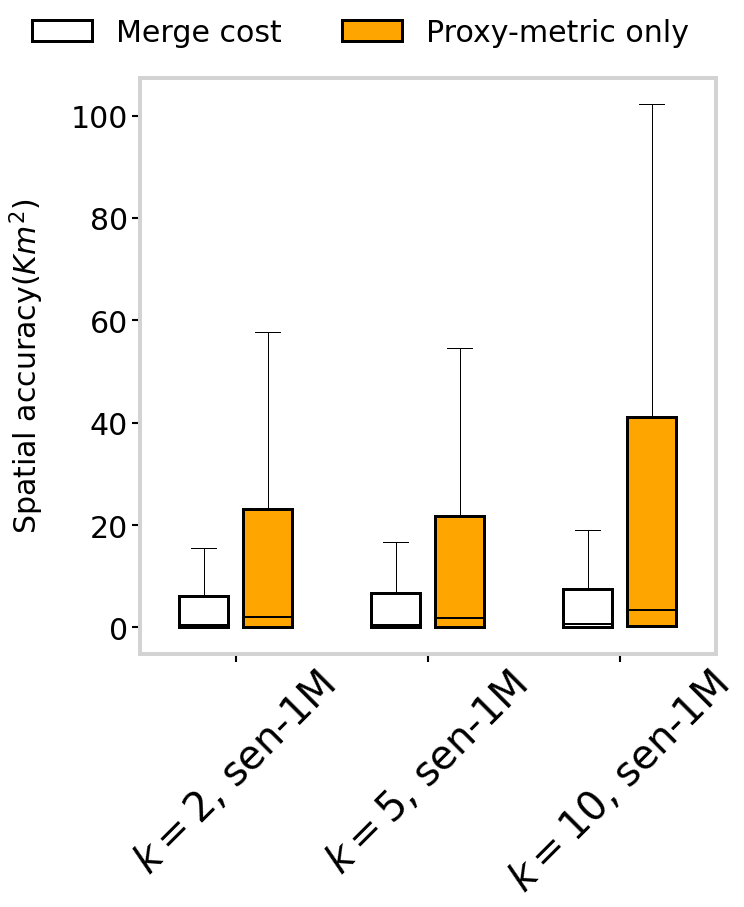

In [48]:
# print(entropies[:10])

# plt.xlabel('Entropy $H$')
# plt.xlabel('Predicability $\prod$')

columns = ["Merge cost", "Proxy-metric only"]

columns1 = ["$k=2$, sen-1M", "$k=5$, sen-1M", "$k=10$, sen-1M"] 

columns2 = ["$k=2$, sen-1M", "$k=5$, sen-1M", "$k=10$, sen-1M"] 

fig=plt.figure(figsize=(8, 8))
# rect = fig.patch
ax=fig.add_axes([0,0,1,1])
ax=fig.gca()
ax.yaxis.tick_left()
ax.xaxis.tick_bottom()
ax.tick_params(axis="both", direction="out", length=8, width=2.1, color="black")


props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showfliers=False) #, showmeans=True


# box1 = ax.boxplot(np.array(entropies),positions=[0],**props)
# box2 = ax.boxplot(np.array(entropies_generalized),positions=[0.5],**props)
# box1_1 = ax.boxplot(np.array(entropies_civ),positions=[1.5],**props)
# box2_2 = ax.boxplot(np.array(entropies_generalized_civ),positions=[2.0],**props)

box1 = ax.boxplot(np.array(mils2),positions=[0],**props)
box1_1 = ax.boxplot(np.array(metrics2),positions=[0.5],**props)
box2 = ax.boxplot(np.array(mils5),positions=[1.5],**props)
box2_2 = ax.boxplot(np.array(metrics5),positions=[2.0],**props)
box3 = ax.boxplot(np.array(mils10),positions=[3.0],**props)
box3_3 = ax.boxplot(np.array(metrics10),positions=[3.5],**props)

# box3 = ax.boxplot(np.array(predicability),positions=[2],**props)
# box4 = ax.boxplot(np.array(predicability_generalized),positions=[2.5],**props)
# box3_3 = ax.boxplot(np.array(predicability_civ),positions=[6],**props)
# box4_4 = ax.boxplot(np.array(predicability_generalized_civ),positions=[6.5],**props)

for axis in ['top','bottom','left','right']:
	ax.spines[axis].set_linewidth(4)
	ax.spines[axis].set_color("lightgray")
# ax.set_ylabel("Entropy $H$",fontsize=40)
ax.set_ylabel("Spatial accuracy($Km^2$)",fontsize=30)

ax.xaxis.labelpad = 25
ax.yaxis.labelpad = 25    
ax.yaxis.labelpad = 25  


for tick in ax.yaxis.get_major_ticks():
	tick.label1.set_fontsize(30)
for tick in ax.xaxis.get_major_ticks():
	tick.label1.set_fontsize(30)


# rotate the tick labels for the x axis ny 45 degree
plt.xticks(rotation=45)
# create twin axis for the temporal accuracy
# ax2 = ax.twinx()
# ax2.yaxis.tick_right()
# ax2.yaxis.set_label_position("right")
# ax2.yaxis.labelpad = 20
# ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# ax2.grid(False)
# box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# make spatial colo of box plot with lightgray and temporal color with ornage
for box in [box1, box2, box3]:
	for b in box['boxes']: 
		b.set_facecolor('white')
		b.set_linewidth(3)
	
# 	for line in box['medians']:
# 		# get position data for median line
# 		x, y = line.get_xydata()[1] # top of median line
# 		# overlay median value
# 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# 			 verticalalignment='top') # draw above, centered

for  box in [box1_1, box2_2, box3_3]:
	for b in box['boxes']: 
		b.set_facecolor('orange')
		b.set_linewidth(3) 
	
# 	for line in box['medians']:
# 		# get position data for median line
# 		x, y = line.get_xydata()[1] # top of median line
# 		# overlay median value
# 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# 			 verticalalignment='center') # draw above, centered 

# for axis in ['top','bottom','left','right']:
# 	ax2.spines[axis].set_linewidth(4)
# 	ax2.spines[axis].set_color("lightgrey")
# ax2.xaxis.labelpad = 25
# ax2.yaxis.labelpad = 25    
# ax2.yaxis.labelpad = 25  
# # ax2.grid(True, lw = 1,c = '.7')
# # ax2.grid(axis='x')

# hatches = ['//']

# # select the correct patches
# patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # the number of patches should be evenly divisible by the number of hatches
# h = hatches * (len(patches) // len(hatches))
# # iterate through the patches for each subplot
# for patch, hatch in zip(patches, h):
#     patch.set_hatch(hatch)
#     patch.set_edgecolor('k')

# l = ax.legend()

# for lp, hatch in zip(l.get_patches(), hatches):
#     lp.set_hatch(hatch)
#     lp.set_edgecolor('k')


# # ax2 yxis ticks at font size 30
# for tick in ax2.yaxis.get_major_ticks():
# 	tick.label2.set_fontsize(30)

ax.set_xticks([0.25,1.75, 3.25])
ax.set_xticklabels(columns1,fontsize=40) 

# ax.set_ylim([0.8, 1])

# make gray bar as lefend spatial and orange as legend for temporal
ax.legend([box1["boxes"][0], box1_1["boxes"][0]], ["Merge cost", "Proxy-metric only"], loc=0, prop={'size': 30},ncol=2,frameon=False,\
		 bbox_to_anchor=(1.0, 1.15)
		 )

# hide the grid
ax.grid(False)
# ax2.grid(False)

# plt.savefig('entropy_final.pdf', dpi=300, bbox_inches='tight')
plt.savefig('metric_comps_space.pdf', dpi=300, bbox_inches='tight')

plt.show()

/tmp/ipykernel_1186055/3482102556.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('metric_comps_time.pdf', dpi=300, bbox_inches='tight')
/tmp/ipykernel_1186055/3482102556.py:143: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig('metric_comps_time.pdf', dpi=300, bbox_inches='tight')
/home/tribe/mabhishe/myspace/anaconda3/lib/python3.9/site-packages/IPython/core/pylabtools.py:151: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


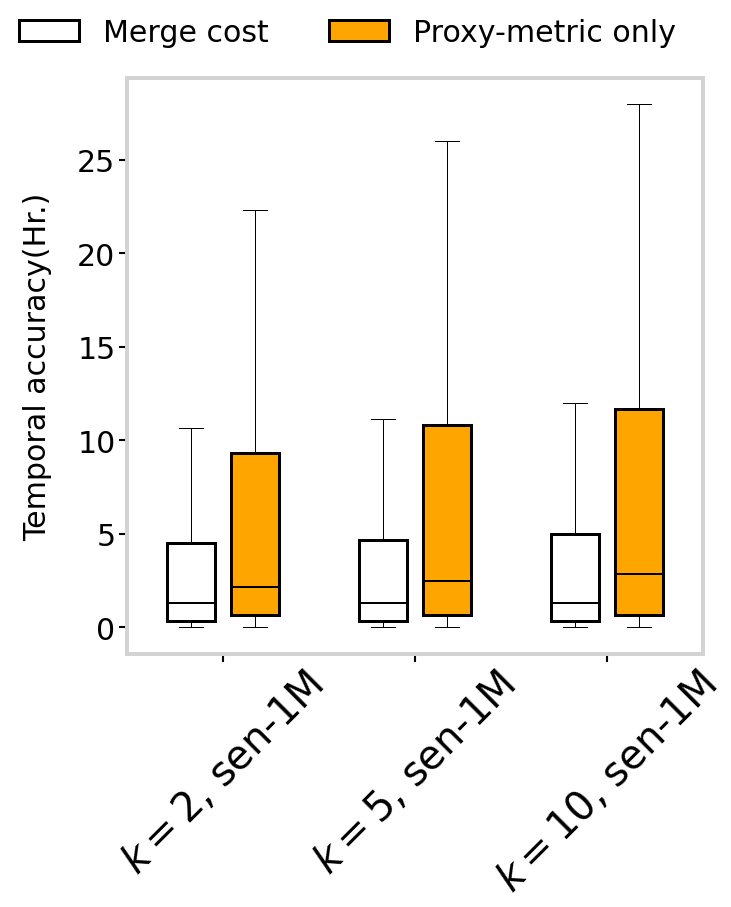

In [49]:
# print(entropies[:10])

# plt.xlabel('Entropy $H$')
# plt.xlabel('Predicability $\prod$')

columns = ["Merge cost", "Proxy-metric only"]

columns1 = ["$k=2$, sen-1M", "$k=5$, sen-1M", "$k=10$, sen-1M"] 

columns2 = ["$k=2$, sen-1M", "$k=5$, sen-1M", "$k=10$, sen-1M"] 

fig=plt.figure(figsize=(8, 8))
# rect = fig.patch
ax=fig.add_axes([0,0,1,1])
ax=fig.gca()
ax.yaxis.tick_left()
ax.xaxis.tick_bottom()
ax.tick_params(axis="both", direction="out", length=8, width=2.1, color="black")


props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showfliers=False) #, showmeans=True


# box1 = ax.boxplot(np.array(entropies),positions=[0],**props)
# box2 = ax.boxplot(np.array(entropies_generalized),positions=[0.5],**props)
# box1_1 = ax.boxplot(np.array(entropies_civ),positions=[1.5],**props)
# box2_2 = ax.boxplot(np.array(entropies_generalized_civ),positions=[2.0],**props)

box1 = ax.boxplot(np.array(milt2)/60,positions=[0],**props)
box1_1 = ax.boxplot(np.array(metrict2)/60,positions=[0.5],**props)
box2 = ax.boxplot(np.array(milt5)/60,positions=[1.5],**props)
box2_2 = ax.boxplot(np.array(metrict5)/60,positions=[2.0],**props)
box3 = ax.boxplot(np.array(milt10)/60,positions=[3.0],**props)
box3_3 = ax.boxplot(np.array(metrict10)/60,positions=[3.5],**props)

# box3 = ax.boxplot(np.array(predicability),positions=[2],**props)
# box4 = ax.boxplot(np.array(predicability_generalized),positions=[2.5],**props)
# box3_3 = ax.boxplot(np.array(predicability_civ),positions=[6],**props)
# box4_4 = ax.boxplot(np.array(predicability_generalized_civ),positions=[6.5],**props)

for axis in ['top','bottom','left','right']:
	ax.spines[axis].set_linewidth(4)
	ax.spines[axis].set_color("lightgray")
# ax.set_ylabel("Entropy $H$",fontsize=40)
ax.set_ylabel("Temporal accuracy(Hr.)",fontsize=30)

ax.xaxis.labelpad = 25
ax.yaxis.labelpad = 25    
ax.yaxis.labelpad = 25  


for tick in ax.yaxis.get_major_ticks():
	tick.label1.set_fontsize(30)
for tick in ax.xaxis.get_major_ticks():
	tick.label1.set_fontsize(30)


# rotate the tick labels for the x axis ny 45 degree
plt.xticks(rotation=45)
# create twin axis for the temporal accuracy
# ax2 = ax.twinx()
# ax2.yaxis.tick_right()
# ax2.yaxis.set_label_position("right")
# ax2.yaxis.labelpad = 20
# ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# ax2.grid(False)
# box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# make spatial colo of box plot with lightgray and temporal color with ornage
for box in [box1, box2, box3]:
	for b in box['boxes']: 
		b.set_facecolor('white')
		b.set_linewidth(3)
	
# 	for line in box['medians']:
# 		# get position data for median line
# 		x, y = line.get_xydata()[1] # top of median line
# 		# overlay median value
# 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# 			 verticalalignment='top') # draw above, centered

for  box in [box1_1, box2_2, box3_3]:
	for b in box['boxes']: 
		b.set_facecolor('orange')
		b.set_linewidth(3) 
	
# 	for line in box['medians']:
# 		# get position data for median line
# 		x, y = line.get_xydata()[1] # top of median line
# 		# overlay median value
# 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# 			 verticalalignment='center') # draw above, centered 

# for axis in ['top','bottom','left','right']:
# 	ax2.spines[axis].set_linewidth(4)
# 	ax2.spines[axis].set_color("lightgrey")
# ax2.xaxis.labelpad = 25
# ax2.yaxis.labelpad = 25    
# ax2.yaxis.labelpad = 25  
# # ax2.grid(True, lw = 1,c = '.7')
# # ax2.grid(axis='x')

# hatches = ['//']

# # select the correct patches
# patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # the number of patches should be evenly divisible by the number of hatches
# h = hatches * (len(patches) // len(hatches))
# # iterate through the patches for each subplot
# for patch, hatch in zip(patches, h):
#     patch.set_hatch(hatch)
#     patch.set_edgecolor('k')

# l = ax.legend()

# for lp, hatch in zip(l.get_patches(), hatches):
#     lp.set_hatch(hatch)
#     lp.set_edgecolor('k')


# # ax2 yxis ticks at font size 30
# for tick in ax2.yaxis.get_major_ticks():
# 	tick.label2.set_fontsize(30)

ax.set_xticks([0.25,1.75, 3.25])
ax.set_xticklabels(columns1,fontsize=40) 

# ax.set_ylim([0.8, 1])

# make gray bar as lefend spatial and orange as legend for temporal
ax.legend([box1["boxes"][0], box1_1["boxes"][0]], ["Merge cost", "Proxy-metric only"], loc=0, prop={'size': 30},ncol=2,frameon=False,\
		 bbox_to_anchor=(1.0, 1.15)
		 )

# hide the grid
ax.grid(False)
# ax2.grid(False)

# plt.savefig('entropy_final.pdf', dpi=300, bbox_inches='tight')
plt.savefig('metric_comps_time.pdf', dpi=300, bbox_inches='tight')

plt.show()

In [50]:
# # print(entropies[:10])

# # plt.xlabel('Entropy $H$')
# # plt.xlabel('Predicability $\prod$')

# columns = ["sen-1M", "civ", "mob"]

# columns1 = ["$H$, sen-1M", "$H$, sen-1M anonymized", \
# 		   "$H$, civ", "$H$, civ anonymized" \
# 		   "$H$, mob", "$H$, mob anonymized"] 

# columns2 = ["$\prod$, sen-1M", "$\prod$, sen-1M anonymized", \
# 		   "$\prod$, civ", "$\prod$, civ anonymized" \
# 		   "$\prod$, mob", "$\prod$, mob anonymized"] 

# fig=plt.figure(figsize=(8, 8))
# # rect = fig.patch
# ax=fig.add_axes([0,0,1,1])
# ax=fig.gca()
# ax.yaxis.tick_left()
# ax.xaxis.tick_bottom()
# ax.tick_params(axis="both", direction="out", length=8, width=2.1, color="black")


# props = dict(widths=0.38,patch_artist=True, medianprops=dict(color="black",lw=2), showfliers=False, showmeans=True)


# box1 = ax.boxplot(np.array(entropies),positions=[0],**props)
# box2 = ax.boxplot(np.array(entropies_generalized),positions=[0.5],**props)
# box1_1 = ax.boxplot(np.array(entropies_civ),positions=[1.5],**props)
# box2_2 = ax.boxplot(np.array(entropies_generalized_civ),positions=[2.0],**props)
# box3_1 = ax.boxplot(np.array(entropies_taka),positions=[1.5],**props)
# box3_2 = ax.boxplot(np.array(entropies_generalized_taka),positions=[2.0],**props)

# # box1 = ax.boxplot(np.array(predicability),positions=[0],**props)
# # box2 = ax.boxplot(np.array(predicability_generalized),positions=[0.5],**props)
# # box1_1 = ax.boxplot(np.array(predicability_civ),positions=[1.5],**props)
# # box2_2 = ax.boxplot(np.array(predicability_generalized_civ),positions=[2.0],**props)

# # box3 = ax.boxplot(np.array(predicability),positions=[2],**props)
# # box4 = ax.boxplot(np.array(predicability_generalized),positions=[2.5],**props)
# # box3_3 = ax.boxplot(np.array(predicability_civ),positions=[6],**props)
# # box4_4 = ax.boxplot(np.array(predicability_generalized_civ),positions=[6.5],**props)

# for axis in ['top','bottom','left','right']:
# 	ax.spines[axis].set_linewidth(4)
# 	ax.spines[axis].set_color("lightgray")
# ax.set_ylabel("Entropy $H$",fontsize=40)
# # ax.set_ylabel("Predictability $\prod$",fontsize=30)

# ax.xaxis.labelpad = 25
# ax.yaxis.labelpad = 25    
# ax.yaxis.labelpad = 25  


# for tick in ax.yaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)
# for tick in ax.xaxis.get_major_ticks():
# 	tick.label1.set_fontsize(30)


# # rotate the tick labels for the x axis ny 45 degree
# plt.xticks(rotation=45)
# # create twin axis for the temporal accuracy
# # ax2 = ax.twinx()
# # ax2.yaxis.tick_right()
# # ax2.yaxis.set_label_position("right")
# # ax2.yaxis.labelpad = 20
# # ax2.set_ylabel(f'(Hrs.)',fontsize=40)
# # ax2.grid(False)
# # box1_1 = ax2.boxplot(np.array(s4),positions=[.5],**props)
# # box2_2 = ax2.boxplot(np.array(s2),positions=[2.5],**props)
# # box3_3 = ax2.boxplot(np.array(s6),positions=[4.5],**props)
# # box4_4 = ax2.boxplot(np.array([0 for j in range(100000)]),positions=[6.5],**props)

# # make spatial colo of box plot with lightgray and temporal color with ornage
# for box in [box1,box1_1]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('white')
# 		b.set_linewidth(3)
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='top') # draw above, centered

# for  box in [box2,box2_2]:
# 	for b in box['boxes']: 
# 		b.set_facecolor('orange')
# 		b.set_linewidth(3) 
	
# # 	for line in box['medians']:
# # 		# get position data for median line
# # 		x, y = line.get_xydata()[1] # top of median line
# # 		# overlay median value
# # 		text(x, y, '%.1f' % x, horizontalalignment='center', 
# # 			 verticalalignment='center') # draw above, centered 

# # for axis in ['top','bottom','left','right']:
# # 	ax2.spines[axis].set_linewidth(4)
# # 	ax2.spines[axis].set_color("lightgrey")
# # ax2.xaxis.labelpad = 25
# # ax2.yaxis.labelpad = 25    
# # ax2.yaxis.labelpad = 25  
# # # ax2.grid(True, lw = 1,c = '.7')
# # # ax2.grid(axis='x')

# # hatches = ['//']

# # # select the correct patches
# # patches = [patch for patch in ax.patches if type(patch) == mpl.patches.PathPatch]
# # # the number of patches should be evenly divisible by the number of hatches
# # h = hatches * (len(patches) // len(hatches))
# # # iterate through the patches for each subplot
# # for patch, hatch in zip(patches, h):
# #     patch.set_hatch(hatch)
# #     patch.set_edgecolor('k')

# # l = ax.legend()

# # for lp, hatch in zip(l.get_patches(), hatches):
# #     lp.set_hatch(hatch)
# #     lp.set_edgecolor('k')


# # # ax2 yxis ticks at font size 30
# # for tick in ax2.yaxis.get_major_ticks():
# # 	tick.label2.set_fontsize(30)

# ax.set_xticks([0.25,1.75, 3.25])
# ax.set_xticklabels(columns,fontsize=40) 

# # ax.set_ylim([0.8, 1])

# # make gray bar as lefend spatial and orange as legend for temporal
# ax.legend([box1["boxes"][0], box2["boxes"][0]], ['Original','Anonymized, $k=10$'], loc=0, prop={'size': 30},ncol=3,frameon=False,\
# 		 bbox_to_anchor=(1.0, 1.15)
# 		 )

# # hide the grid
# ax.grid(False)
# # ax2.grid(False)

# plt.savefig('entropy_final.pdf', dpi=300, bbox_inches='tight')
# # plt.savefig('predictability_final.pdf', dpi=300, bbox_inches='tight')

# plt.show()

## Computing the utility of generalized datasets

In [51]:
from scipy.spatial import ConvexHull
# from datetime import datetime 

import datetime

import geopandas as gpd
from pylab import *

from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
import mapply

from scipy.optimize import curve_fit

class CharacterizeUtility:
	def __init__(self, scenario, fname, trajs, k, s_size=0):
		self.scenario = scenario
		self.fname=fname
		self.trajs=trajs
		self.k=k
		self.subsample_size=s_size
	
	def plotMetric(self, dt, icode):
		fig, axi = plt.subplots(1, 1)

	# 		print(dt)
		df = pd.DataFrame(dt)
	# 		print(df)
# 		df.columns=["size"]

		sns.ecdfplot(data=df)

		if icode==1 or icode==2 or icode==4 or icode==5:
			plt.xlabel("Error[Km]")
		elif icode==3:
			plt.xlabel("$Error[{Km}^2]$")
		plt.ylabel("CDF")

		axi.get_legend().remove()
		
		glove=False
	
		if not glove:
			if icode==1:
				plt.xlim([0, 10])
				plt.savefig('com_error_5k.pdf') #5k, 1m
			elif icode==2:
				plt.xlim([0, 10])
				plt.savefig('rg_error_5k.pdf')
			elif icode==3:
				plt.savefig('ch_error_5k.pdf')
			elif icode==4:
				plt.xlim([0, 100])
				plt.savefig('td_error_5k.pdf')
			elif icode==5:
				plt.xlim([0, 10])
				plt.savefig('hw_error_5k.pdf')
		else:
			if icode==1:
				plt.xlim([0, 10])
				plt.savefig('com_error_glove_1m.pdf')
			elif icode==2:
				plt.xlim([0, 10])
				plt.savefig('rg_error_glove_1m.pdf')
			elif icode==3:
				plt.savefig('ch_error_glove_1m.pdf')
			elif icode==4:
				plt.xlim([0, 100])
				plt.savefig('td_error_glove_1m.pdf')
			elif icode==5:
				plt.xlim([0, 10])
				plt.savefig('hw_error_glove_1m.pdf')
	
	def calculate_COM(self, idata, genralized=False):
		rcm_array=[]
		j=0
		
		if not genralized:
			for usr in tqdm(idata):
				#usr=usr[usr!=-1000]
				xr, yr = 0, 0
				for sample in usr:
					xr = xr + sample[0]
					yr = yr + sample[1]
					#rcm = [np.sum(usr[::4])/(len(usr)/4), np.sum(usr[1::4])/(len(usr)/4)]
				xr, yr = xr/len(usr), yr/len(usr)
				#print(usr, xr, yr)
				rcm_array.append([xr, yr])
				j=j+1
		else:
			for key in tqdm(range(len(self.trajs))):
				usr=idata[key]
				#usr=usr[usr!=-1000]
# # 				print(usr)
				
# 				print(key)

				xr, yr = 0, 0
				if len(usr):
					for sample in usr:
						xr = xr + (sample[0]+sample[3])/2
						yr = yr + (sample[1]+sample[4])/2
						#rcm = [np.sum(usr[::4])/(len(usr)/4), np.sum(usr[1::4])/(len(usr)/4)]
					xr, yr = xr/len(usr), yr/len(usr)
# 				print(len(usr), xr, yr)
					rcm_array.append([xr, yr])
				j=j+1
# 				break
		return rcm_array 

	def calculate_RG_t(self, usr, genralized=False):
		if not genralized:
			usr = usr[usr[:, 2].argsort()]

			rcmx = (np.sum(usr[:,0])/(len(usr)), np.sum(usr[:,1])/(len(usr)))

			da1 = np.diff(usr[:,2].copy())
			ts_sum1 = np.sum(da1)

# 				da1=1
# 				ts_sum1=len(usr)

			rgx = np.sqrt(np.sum( ( ((usr[:,0]-rcmx[0]) - (usr[:,1]-rcmx[1]))**2 )[1:] * da1 ) / ts_sum1)
# 				if rgx>1000:
			return rgx
		else:
			usr2 = np.zeros( (len(usr), 3) )

			for j, sample in enumerate(usr):
				usr2[j][0]=(sample[0]+sample[3])/2
				usr2[j][1]=(sample[1]+sample[4])/2
				usr2[j][2]=(sample[2]+sample[5])/2

			usr2 = usr2[usr2[:, 2].argsort()]

			rcmx = (np.sum(usr2[:,0])/(len(usr2)), np.sum(usr2[:,1])/(len(usr2)))

			da1 = np.diff(usr2[:,2].copy())
			ts_sum1 = np.sum(da1)

# 				da1=1
# 				ts_sum1=len(usr)

			rgx = np.sqrt(np.sum( ( ((usr2[:,0]-rcmx[0]) - (usr2[:,1]-rcmx[1]))**2 )[1:] * da1 ) / ts_sum1)

			return rgx
	
	def calculate_RG(self, idata, genralized=False):
	# 	x, y = x[x!=-1000], y[y!=-1000]

		rg_array=[]

		if not genralized:
			for usr in tqdm(idata):
				usr = usr[usr[:, 2].argsort()]

				rcmx = (np.sum(usr[:,0])/(len(usr)), np.sum(usr[:,1])/(len(usr)))

				da1 = np.diff(usr[:,2].copy())
				ts_sum1 = np.sum(da1)
				
# 				da1=1
# 				ts_sum1=len(usr)

				rgx = np.sqrt(np.sum( ( ((usr[:,0]-rcmx[0]) - (usr[:,1]-rcmx[1]))**2 )[1:] * da1 ) / ts_sum1)
# 				if rgx>1000:
				rg_array.append(rgx)
		else:
			for key in tqdm(range(len(self.trajs))):
				usr=idata[key]
				
				usr2 = np.zeros( (len(usr), 3) )
				
				for j, sample in enumerate(usr):
					usr2[j][0]=(sample[0]+sample[3])/2
					usr2[j][1]=(sample[1]+sample[4])/2
					usr2[j][2]=(sample[2]+sample[5])/2
# 					usr2[j][0]=min(sample[0], sample[3])
# 					usr2[j][1]=min(sample[1], sample[4])
# 					usr2[j][2]=min(sample[2], sample[5])
				
				usr2 = usr2[usr2[:, 2].argsort()]

				rcmx = (np.sum(usr2[:,0])/(len(usr2)), np.sum(usr2[:,1])/(len(usr2)))

				da1 = np.diff(usr2[:,2].copy())
				ts_sum1 = np.sum(da1)
				
# 				da1=1
# 				ts_sum1=len(usr)

				rgx = np.sqrt(np.sum( ( ((usr2[:,0]-rcmx[0]) - (usr2[:,1]-rcmx[1]))**2 )[1:] * da1 ) / ts_sum1)
				
# 				if rgx>1000:
				rg_array.append(rgx)
				
# 				print(usr2, rgx)
				
# 				break

	# 	print(max(rg_array))

		return rg_array
	
	def calculate_distance_two_points(self, point1, point2):
		return np.sqrt((point1[0] - point2[0])**2 + (point1[1] - point2[1])**2)
	
	def calculate_TotDistance(self, idata, genralized=False):
		td_array=[]

		if not genralized:
			for usr in tqdm(idata):
				points=set()
				tdist=0
				for sample in usr:
					points.add( ( int(sample[0]), int(sample[1]) ) )
				
				points=list(points)

				if len(points)>=2:
					for j in range(1, len(points)):
						tdist=tdist+self.calculate_distance_two_points(points[j-1], points[j])
					td_array.append(tdist)
				else:
					td_array.append(0) #singleton trajectories!
		else:
			for key in tqdm(range(len(self.trajs))):
				usr=idata[key]
				
				points=set()
				tdist=0
				
				for j, sample in enumerate(usr):
					points.add( ( int((sample[0]+sample[3])/2), int((sample[1]+sample[4])/2) ) )
				
				points=list(points)
				
				if len(points)>=2:
					for j in range(1, len(points)):
						tdist=tdist+self.calculate_distance_two_points(points[j-1], points[j])
					td_array.append(tdist)
				else:
					td_array.append(0) #singleton trajectories!

	# 	print(max(rg_array))

		return td_array 
	
	def isNonCoplanar(self, pts):
		x,y = set(), set()
		
		for pt in pts:
			x.add(pt[0])
			y.add(pt[1])
		
# 		print(pts)
		
		return (len(x)>1 and len(y)>1)
	
	def calculate_HullArea(self, idata, genralized=False):
		ha_array=[]

		if not genralized:
			for usr in tqdm(idata):
				points=set()
				for sample in usr:
					points.add( ( int(sample[0]), int(sample[1]) ) )

				if len(points)>=4 and self.isNonCoplanar(points)==True:
					hull = ConvexHull(list(points))
					ha_array.append(hull.area)
				else:
					ha_array.append(0) #singleton trajectories!
		else:
			for key in tqdm(range(len(self.trajs))):
				usr=idata[key]
				
				points=set()
				
				usr2 = np.zeros( (len(usr), 3) )
				
				for j, sample in enumerate(usr):
					usr2[j][0]=(sample[0]+sample[3])/2
					usr2[j][1]=(sample[1]+sample[4])/2
					usr2[j][2]=(sample[2]+sample[5])/2
					
					points.add( ( int((sample[0]+sample[3])/2), int((sample[1]+sample[4])/2) ) )
				
				if len(points)>=4 and self.isNonCoplanar(points)==True:
					hull = ConvexHull(list(points))
					ha_array.append(hull.area)
				else:
					ha_array.append(0) #singleton trajectories!

	# 	print(max(rg_array))

		return ha_array
	
	def calculate_HWLocations(self, idata, genralized=False):
		hw_array=[]

		if not genralized:
			for usr in tqdm(idata):
				day_dict = defaultdict(int)
				night_dict = defaultdict(int)
				
				for sample in usr:
					point = ( int(sample[0]), int(sample[1]) )
					
					tds=datetime.datetime.fromtimestamp(sample[2]).strftime("%H:%M:%S") #"%A, %B %d, %Y %I:%M:%S"
					
					telapsed = int(tds[:2])*60 + int(tds[3:5])
# 					print(tds, telapsed)
					
					if telapsed>=540 and telapsed<=1020:
						day_dict[point] = day_dict[point]+1
					elif telapsed>=1320 or telapsed<=360:
						night_dict[point] = night_dict[point]+1
				
				mx_val = -1
				dmax = 0
				for key in day_dict.keys():
					if day_dict[key]>mx_val:
						mx_val=day_dict[key]
						dmax=key
				
				mx_val = -1
				nmax = 0
				for key in night_dict.keys():
					if night_dict[key]>mx_val:
						mx_val=night_dict[key]
						nmax=key
				
				hw_array.append( (dmax, nmax) )
				
# 				print(hw_array, night_dict)
# 				break
		else:
			for key in tqdm(range(len(self.trajs))):
				usr=idata[key]
				
				day_dict = defaultdict(int)
				night_dict = defaultdict(int)
				
				for sample in usr:
					point = ( int((sample[0]+sample[3])/2), int((sample[1]+sample[4])/2) )
					
					tds=datetime.datetime.fromtimestamp(int((sample[2]+sample[5])/2)).strftime("%H:%M:%S") #"%A, %B %d, %Y %I:%M:%S"
					
					telapsed = int(tds[:2])*60 + int(tds[3:5])
# 					print(tds, telapsed)
					
					if telapsed>=540 and telapsed<=1020:
						day_dict[point] = day_dict[point]+1
					elif telapsed>=1320 or telapsed<=360:
						night_dict[point] = night_dict[point]+1
				
				mx_val = -1
				dmax = 0
				for key in day_dict.keys():
					if day_dict[key]>mx_val:
						mx_val=day_dict[key]
						dmax=key
				
				mx_val = -1
				nmax = 0
				for key in night_dict.keys():
					if night_dict[key]>mx_val:
						mx_val=night_dict[key]
						nmax=key
				
				hw_array.append( (dmax, nmax) )
		
		return hw_array
	
	def getCOM(self):
# 		print(ca6.obtainGTrajs())
# 		print(self.trajs[0], ca6.obtainGTrajs()[0])
	
		c1=self.calculate_COM(self.trajs)
	
		c2=self.calculate_COM(ca6.obtainGTrajs(), True)
		
# 		dt = np.sqrt((np.array(c1)[:,0]-np.array(c2)[:,0])**2 + (np.array(c1)[:,1]-np.array(c2)[:,1])**2)/1000
# # 		print(dt[:1000])

# 		print(len(c1), len(c2))

# 		with open('million_merge_list.pickle', 'rb') as handle:
# 			merge_list1 = pickle.load(handle)
		
		dt=[]
		for j in range(len(c1)):
			dt.append(self.calculate_distance_two_points(c1[j], c2[j])/1000)
		
# 		for j in range(100):
# 			print(c1[j], c2[j], dt[j])

		with open('com'+str(self.k)+'.pickle', 'wb') as handle:
			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
		
# 		self.plotMetric(dt, 1)
	
	def getHomeAndWorkLocations(self):
		c1=self.calculate_HWLocations(self.trajs)
	
		c2=self.calculate_HWLocations(ca6.obtainGTrajs(), True)
		
# 		dt=abs(np.array(c1)-np.array(c2))/1000
		dt=[]
		for j in range(len(c1)):
			if c1[j][0]!=0 and c2[j][0]!=0 and c1[j][1]!=0 and c2[j][1]!=0:
				dt.append(self.calculate_distance_two_points(c1[j][0], c2[j][0])/1000)
				dt.append(self.calculate_distance_two_points(c1[j][1], c2[j][1])/1000)
		
		with open('hwl'+str(self.k)+'.pickle', 'wb') as handle:
			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 		self.plotMetric(dt, 5)
	
	def getTotDistance(self):
		c1=self.calculate_TotDistance(self.trajs)
	
		c2=self.calculate_TotDistance(ca6.obtainGTrajs(), True)
		dt=abs(np.array(c1)-np.array(c2))/1000
		
		with open('td'+str(self.k)+'.pickle', 'wb') as handle:
			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 		self.plotMetric(dt, 4)
	
	def getRoG(self):
# 		print(ca6.obtainGTrajs())
		c1=self.calculate_RG(self.trajs)
	
		c2=self.calculate_RG(ca6.obtainGTrajs(), True)
		dt=abs(np.array(c1)-np.array(c2))/1000
		
		with open('rg'+str(self.k)+'.pickle', 'wb') as handle:
			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 		self.plotMetric(dt, 2)
	
	def getConvexHulls(self):
		c1=self.calculate_HullArea(self.trajs)
	
		c2=self.calculate_HullArea(ca6.obtainGTrajs(), True)
		dt=abs(np.array(c1)-np.array(c2))/10**6
		
		with open('ch'+str(self.k)+'.pickle', 'wb') as handle:
			pickle.dump(dt, handle, protocol=pickle.HIGHEST_PROTOCOL)
# 		self.plotMetric(dt, 3)
	
	def getCombinedPlots(self):
		tempth=['com', 'rg', 'ch', 'hwl']
		tfull = ['Center of Mass', 'Radius of Gyration', 'Convex Hull Areas', 'Home/Work Locations'] #'Total Distance', 
		
		kvals = [2, 5, 10]
		
		df = pd.DataFrame()
		for j, k in enumerate(kvals):
			for i, val in enumerate(tempth):
				with open(val + str(k) + '.pickle', 'rb') as handle:
					dt = pickle.load(handle)
					
					dt = pd.DataFrame(dt, columns=['Error'])

# 					sns.lineplot(data=dt, x="Samples below threshold %", y="Anonymised trajs. %", label=str(val)+" Km", ax=axi[j])
# 					axi[j].get_legend().remove()
					
					dt = dt.sample(n=10000) #1000
					dt["Metric"]=[tfull[i]]*10000 #str(val)
					dt["k"]=[k]*10000
				df = pd.concat([df, dt])
		df = df.reset_index(drop=True)
		
		print(df)
		
		plt.rcParams["font.size"] = "27"
		kw = {'linestyle' : ['-', '--', '-.', ':', 'solid', 'dashed', 'dashdot', 'dotted', '-', '--', '-.', 'solid', 'dashed', 'dashdot']}
		g = sns.FacetGrid(df, col="Metric", hue="k", height=2.5, col_wrap=4, sharex=False, hue_kws=kw) #2.5, col_wrap=5
		g.map(sns.ecdfplot, "Error").add_legend() #, "Distance Threshold"
		
		g.axes[0].set_xlabel('$Error[Km]$')
		g.axes[0].set_xlim([0, 10])
		
		g.axes[1].set_xlabel('$Error[Km]$')
		g.axes[1].set_xlim([0, 10])
		
		g.axes[2].set_xlabel('$Error[Km^2]$')
		g.axes[2].set_xlim([0, 0.2]) #0.5
		
# 		g.axes[3].set_xlabel('$Error[Km]$')
# 		g.axes[3].set_xlim([0, 500]) #100
		
		g.axes[3].set_xlabel('$Error[Km]$')
		g.axes[3].set_xlim([0, 10])
		
		g.savefig("utility_final" + self.scenario + ".pdf")
	
	
	# Best Models

	def plmodel_1(x, k_0, beta, k):
		return  ( (x+k_0)**-beta )* (np.exp**(-x/k))

	def plmodel_2(x, k, k_1, k_2, k_3, alpha):
		return k *(x[0]) * (k_1 * x[1] + k_2 * x[2] + k_3 * x[3])**alpha    

	def plmodel_3(x, k, k_1, k_2, k_3, alpha, beta):
		return k *(x[0]**beta) * (k_1 * x[1] + k_2 * x[2] + k_3 * x[3])**alpha    
	
	def find_delta_r(self, idata, genralized=False):
		td_array=[]
		rg_ret=[]
		normalized=False
		
		if not normalized:
			rg=self.calculate_RG(idata, genralized)
			if not genralized:
				for i, usr in tqdm(enumerate(idata)):
					points=set()
					tdist=0
					for sample in usr:
						points.add( ( int(sample[0]), int(sample[1]) ) )

					points=list(points)

					if len(points)>=2:
						for j in range(1, len(points)):
							tdist=self.calculate_distance_two_points(points[j-1], points[j])
							
# 							print(usr[:j])
							rg_t = self.calculate_RG_t(usr[:j+1], genralized)
							if tdist>1000 and rg_t>1: #and tdist<10**7 1000, rg[i]
								td_array.append( tdist/rg_t )#rg[i] /rg_t
	# 							
	# 							rg_ret.append(rg_t) #rg[i]
								rg_ret.append(rg[i])
			else:
				for key in tqdm(range(len(self.trajs))):
					usr=idata[key]

					points=set()
					tdist=0

					for j, sample in enumerate(usr):
						points.add( ( int((sample[0]+sample[3])/2), int((sample[1]+sample[4])/2) ) )
# 						points.add( ( int(min(sample[0], sample[3])), int(min(sample[1], sample[4])) ) )

					points=list(points)

					if len(points)>=2:
# 						for j in range(1, len(points)):
# 							tdist=self.calculate_distance_two_points(points[j-1], points[j])
						for j in range(1, len(points)):
							tdist=tdist+self.calculate_distance_two_points(points[j-1], points[j])
						
							rg_t = self.calculate_RG_t(usr[:j], genralized)
# 							if tdist>0 and rg_t>5: #and tdist<10**7 1000, rg[key]
							
							if tdist>1000 and rg_t>1:
								td_array.append( tdist/rg_t )
	# 							td_array.append(tdist/rg_t) #rg[key]
	# 							rg_ret.append(rg_t) #rg[key]
								rg_ret.append(rg[key])
		else:
			if not genralized:
				for usr in tqdm(idata):
					points=set()
					tdist=0
					for sample in usr:
						points.add( ( int(sample[0]), int(sample[1]) ) )

					points=list(points)

					if len(points)>=2:
# 						for j in range(1, len(points)):
# 							tdist=self.calculate_distance_two_points(points[j-1], points[j])
						for j in range(1, len(points)):
							tdist=tdist+self.calculate_distance_two_points(points[j-1], points[j])
						if tdist>0: #and tdist<10**7 1000
							td_array.append(tdist)
			else:
				for key in tqdm(range(len(self.trajs))):
					usr=idata[key]

					points=set()
					tdist=0

					for j, sample in enumerate(usr):
						points.add( ( int((sample[0]+sample[3])/2), int((sample[1]+sample[4])/2) ) )

					points=list(points)

					if len(points)>=2:
						for j in range(1, len(points)):
							tdist=self.calculate_distance_two_points(points[j-1], points[j])
							if tdist>1000: #and tdist<10**7 1000
								td_array.append(tdist)

	# 	print(max(rg_array))

		return td_array, rg_ret
	
	def powerLawHumanMobility(self):
		rg1=self.calculate_RG(self.trajs)
		rg2=self.calculate_RG(ca6.obtainGTrajs(), True)
		
		d1=self.find_delta_r(self.trajs)
		d2=self.find_delta_r(ca6.obtainGTrajs(), True)
		
# 		d1=[1/val for val in d1]
# 		d2=[1/val for val in d2]
# 		sd1=sum(d1)
# 		sd2=sum(d2)
# 		pd1=[val/sd1 for val in d1]
# 		pd2=[val/sd2 for val in d2]
		
# 		sns.kdeplot(pd1)
# 		sns.kdeplot(pd2)

		count1, bins_edges1 = np.histogram(np.array(d1), bins=1000, density=True)
		count2, bins_edges2 = np.histogram(np.array(d2), bins=1000, density=True)

		# finding the PDF of the histogram using count values
		pd1 = count1 / sum(count1)
		pd2 = count2 / sum(count2)
		
# 		pd1=pd.DataFrame(pd1, columns=["pdf"])
# 		pd2=pd.DataFrame(pd2, columns=["pdf"])
		
# 		print(pd1)
		
		sns.kdeplot(data=pd1)
		sns.kdeplot(data=pd2)
		
# 		print(pd1)

In [52]:
cu = CharacterizeUtility("Million", "generalised_million5new/*", tdata_full, 5)

cu.getCOM()
cu.getRoG()
cu.getConvexHulls()
# cu.getTotDistance()
cu.getHomeAndWorkLocations()

cu.getCombinedPlots()

  0%|                                                                         | 0/1008169 [00:00<?, ?it/s]/tmp/ipykernel_1186055/3986479327.py:192: RuntimeWarning: invalid value encountered in scalar divide
  rgx = np.sqrt(np.sum( ( ((usr2[:,0]-rcmx[0]) - (usr2[:,1]-rcmx[1]))**2 )[1:] * da1 ) / ts_sum1)
 84%|████████████████████████████████████████████████▌         | 843200/1008169 [08:21<01:38, 1681.96it/s]


KeyboardInterrupt: 

In [ ]:
# cu = CharacterizeUtility("Taka", "generalised_takanew/*", tdata_full_taka, 10)

# # cu.getCOM()
# # cu.getRoG()
# # cu.getConvexHulls()
# # cu.getTotDistance()
# # cu.getHomeAndWorkLocations()

# cu.getCombinedPlots()

In [ ]:
# cu = CharacterizeUtility("civ", "generalised_civ2new/*", tdata_full_civ, 2)

# cu.getCOM()
# cu.getRoG()
# cu.getConvexHulls()
# cu.getTotDistance()
# cu.getHomeAndWorkLocations()

# # cu.getCombinedPlots()

In [ ]:
# import datetime
# print(datetime.datetime.fromtimestamp(sample[2]))

In [ ]:
# cu = CharacterizeUtility("civ", "generalised_million10new/*", tdata_full_civ, 10)

# cu.getCOM()
# cu.getRoG()
# cu.getConvexHulls()
# cu.getTotDistance()
# cu.getHomeAndWorkLocations()

# cu.getCombinedPlots()

In [ ]:
civ_utility=False
taka_utility=True
# = CharacterizeAnonimisation("Civ", "generalised_civnew/*", tdata_full_civ, 10)

In [ ]:
# if not civ_utility:
# 	cu = CharacterizeUtility("Million", "generalised_million10new/*", tdata_full, 10)
# else:
# 	cu = CharacterizeUtility("Civ", "generalised_civnew/*", tdata_full_civ, 10) #2
# # cu.powerLawHumanMobility()

In [ ]:
# if not civ_utility:
# 	rg1=cu.calculate_RG(cu.trajs)
# 	rg2=cu.calculate_RG(ca6.obtainGTrajs(), True)

# 	d1, rg1=cu.find_delta_r(cu.trajs)
# 	d2, rg2=cu.find_delta_r(ca6.obtainGTrajs(), True)
	
# # 	d1=cu.find_delta_r(cu.trajs)
# # 	d2=cu.find_delta_r(ca6.obtainGTrajs(), True)
# else:
# # 	rg1=cu.calculate_RG(cu.trajs)
# # 	rg2=cu.calculate_RG(ca3.obtainGTrajs(), True)

# 	d1, rg1=cu.find_delta_r(cu.trajs)
# 	d2, rg2=cu.find_delta_r(ca3.obtainGTrajs(), True)
	
# # 	d1=cu.find_delta_r(cu.trajs)
# # 	d2=cu.find_delta_r(ca3.obtainGTrajs(), True)

# # 		d1=[1/val for val in d1]
# # 		d2=[1/val for val in d2]
# # 		sd1=sum(d1)
# # 		sd2=sum(d2)
# # 		pd1=[val/sd1 for val in d1]
# # 		pd2=[val/sd2 for val in d2]

# # 		sns.kdeplot(pd1)
# # 		sns.kdeplot(pd2)

In [ ]:
# # n = len(np.array(d1))  # for 2 random indices
# # print(len(np.array(d1)))
# # index1 = np.random.choice(len(np.array(d1)), n, replace=False)
# # index2 = np.random.choice(len(np.array(d2)), n, replace=False)

# rindex1=np.array([True if val<1 else False for val in d1])
# rindex2=np.array([True if val<1 else False for val in d2])

# rg1_4=np.array([True if val>3500 and val<4500 else False for val in rg1])
# rg1_10=np.array([True if val>9000 and val<11000 else False for val in rg1])
# rg1_40=np.array([True if val>37000 and val<43000 else False for val in rg1])
# rg1_100=np.array([True if val>90000 and val<110000 else False for val in rg1])
# rg1_200=np.array([True if val>180000 and val<220000 else False for val in rg1])

# rg2_4=np.array([True if val>3500 and val<4500 else False for val in rg2])
# rg2_10=np.array([True if val>9000 and val<11000 else False for val in rg2])
# rg2_40=np.array([True if val>37000 and val<43000 else False for val in rg2])
# rg2_100=np.array([True if val>90000 and val<110000 else False for val in rg2])
# rg2_200=np.array([True if val>180000 and val<220000 else False for val in rg2])

# index1=np.logical_or(np.logical_or(np.logical_or(rg1_4, rg1_10), np.logical_or(rg1_40, rg1_100)), rg1_200) 
# index2=np.logical_or(np.logical_or(np.logical_or(rg2_4, rg2_10), np.logical_or(rg2_40, rg2_100)), rg2_200)

In [ ]:
# u1_1=np.array(d1)[rg1_4]
# u2_1=np.array(d1)[rg1_10]
# u3_1=np.array(d1)[rg1_40]
# u4_1=np.array(d1)[rg1_100]
# u5_1=np.array(d1)[rg1_200]

# u1_2=np.array(d2)[rg2_4]
# u2_2=np.array(d2)[rg2_10]
# u3_2=np.array(d2)[rg2_40]
# u4_2=np.array(d2)[rg2_100]
# u5_2=np.array(d2)[rg2_200]

In [ ]:
# count1_1, bins_count1_1 = np.histogram(u1_1, bins=1000) #, density=True
# count2_1, bins_count2_1 = np.histogram(u2_1, bins=1000)
# count3_1, bins_count3_1 = np.histogram(u3_1, bins=1000)
# count4_1, bins_count4_1 = np.histogram(u4_1, bins=1000)
# count5_1, bins_count5_1 = np.histogram(u5_1, bins=1000)

# count1_2, bins_count1_2 = np.histogram(u1_2, bins=1000) #, density=True
# count2_2, bins_count2_2 = np.histogram(u2_2, bins=1000)
# count3_2, bins_count3_2 = np.histogram(u3_2, bins=1000)
# count4_2, bins_count4_2 = np.histogram(u4_2, bins=1000)
# count5_2, bins_count5_2 = np.histogram(u5_2, bins=1000)

# # finding the PDF of the histogram using count values
# pd1_1 = count1_1 / sum(count1_1)
# pd2_1 = count2_1 / sum(count2_1)
# pd3_1 = count3_1 / sum(count3_1)
# pd4_1 = count4_1 / sum(count4_1)
# pd5_1 = count5_1 / sum(count5_1)

# pd1_2 = count1_2 / sum(count1_2)
# pd2_2 = count2_2 / sum(count2_2)
# pd3_2 = count3_2 / sum(count3_2)
# pd4_2 = count4_2 / sum(count4_2)
# pd5_2 = count5_2 / sum(count5_2)

In [ ]:
# pd1_1=np.array(pd1_1[:-1])*(4**1.3) #Alpha 1.3 in senegal 1M, while lower in CIV
# pd2_1=np.array(pd2_1[:-1])*(10**1.3)
# pd3_1=np.array(pd3_1[:-1])*(40**1.3)
# pd4_1=np.array(pd4_1[:-1])*(100**1.3)
# pd5_1=np.array(pd5_1[:-1])*(200**1.3)

In [ ]:
# pd1_2=np.array(pd1_2[:-1])*(4**1.3)
# pd2_2=np.array(pd2_2[:-1])*(10**1.3)
# pd3_2=np.array(pd3_2[:-1])*(40**1.3)
# pd4_2=np.array(pd4_2[:-1])*(100**1.3)
# pd5_2=np.array(pd5_2[:-1])*(200**1.3)

In [ ]:
# # 		pd1=pd.DataFrame(pd1, columns=["pdf"])
# # 		pd2=pd.DataFrame(pd2, columns=["pdf"])

# # 		print(pd1)

# # sns.kdeplot(data=pd1)
# # sns.kdeplot(data=pd2)

# markers=[',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		
# # if xlab=="Spatial accuracy($Km^2$)":
# # 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# # elif xlab=="Spatial normalised accuracy":
# # 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# # elif xlab=="Temporal accuracy(Hr.)":
# # 	bins_t=[30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

# # if self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
# # 	sub_labels=["Our solution 1000", "Our solution 2000", "Glove Strict 1000", "Glove Strict 2000"]#, "Glove Loose 1000", "Glove Loose 2000"]
# # else:
# # 	sub_labels=["sen-1k", "sen-2k", "sen-5k", "sen-10k", "sen-25k", "sen-50k", "sen-100k", "sen-200k", "sen-300k", "sen-1M"]#precise?

# clrs = sns.color_palette() #"coolwarm", 10

# # 		vals=[]

# # for i, lev in enumerate(sub_labels):
# # # 			sns.ecdfplot(dt[i], color=clrs[i], label=lev, linestyle="--", marker=markers[i])
# # 	# getting data of the histogram
# # 	count, bins_count = np.histogram(dt[i], bins=bins_t)

# # 	# finding the PDF of the histogram using count values
# # 	pdf = count / sum(count)

# # # 			print(len(dt[i]))

# # cdf1 = np.cumsum(pd1)
# # cdf2 = np.cumsum(pd2)

# def plmodel_5(x, A, B): # this is your 'straight line' y=f(x)
# #     return A*x + B #log y = m log x + log k
# 	return 10**(A*np.log10(x)+np.log10(B)) 

# y1=pd1_1 #+pd2_1+pd3_1+pd4_1+pd5_1
# x1=np.array(bins_count1_1[1:-1])#+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])

# yp=[]
# xp=[]
# for i, val in enumerate(x1):
# # 	if val<5:
# 	yp.append(y1[i])
# 	xp.append(x1[i])

# # y2=pd1_2+pd2_1+pd3_1+pd4_1+pd5_1
# # x2=np.array(bins_count1_2[1:-1])+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])

# # yp2=[]
# # xp2=[]
# # for i, val in enumerate(x2):
# # 	if val>10 and val<500:
# # 		yp2.append(y2[i])
# # 		xp2.append(x2[i])

# slope1, intercept1 = np.polyfit(np.log(xp), np.log(yp), deg=1) # This method for Senegal and the other for CIV
# # # slope2, intercept2 = np.polyfit(np.log(xp2), np.log(yp2), deg=1)

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_4, np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2))
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_4, np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2))

# xp=[10**-2+i*0.01 for i in range(1000)]
# ys_pred_1 = plmodel_5(xp, slope1, intercept1*-0.20) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal
# # ys_pred_2 = plmodel_5(xp, slope2, intercept2)
# print(slope1, intercept1/5) 
# # print(slope2, intercept2)  

# # slope1, intercept1 = np.polyfit(bins_count1[1:-1], pd1[:-1], deg=1) # This method for Senegal and the other for CIV
# # slope2, intercept2 = np.polyfit(bins_count2[1:-1], pd2[:-1], deg=1)

# # print(slope1, intercept1)
# # print(slope2, intercept2)

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_5, np.array(bins_count1[1:-1]), pd1[:-1])
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_5, np.array(bins_count2[1:-1]), pd2[:-1])

# # ys_pred_1 = plmodel_5(np.array(d1), *fitParams_1) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal
# # ys_pred_2 = plmodel_5(np.array(d2), *fitParams_2) #/10

# fig =plt.figure(figsize=(8, 8))
# ax=fig.add_axes([0,0,1,1])
# # ax=fig.gca()

# plt.scatter(np.array(bins_count1_1[1:-1]), pd1_1, color=clrs[0], label="$r_g \sim 4$", linestyle="--", marker=markers[0]) #color="red", 
# plt.scatter(np.array(bins_count2_1[1:-1]), pd2_1, color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 
# plt.scatter(np.array(bins_count3_1[1:-1]), pd3_1, color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 
# plt.scatter(np.array(bins_count4_1[1:-1]), pd4_1, color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 
# plt.scatter(np.array(bins_count5_1[1:-1]), pd5_1, color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 
# plt.plot(xp, ys_pred_1, color=clrs[5]) #color="red", label="", linestyle="--", 
# # plt.plot(xp, ys_pred_2, color=clrs[3], label="Fitted Anonymized") #color="red", label="", linestyle="--", 

# # plt.scatter(np.array(bins_count2[1:-1]), pd2[:-1], color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 

# # plt.xlim([10**-1, 10**2])
# # plt.ylim([10**-3, 10**1])
# plt.legend()
# plt.xticks(rotation=45)

# # plt.rcParams.update({'font.size': 30})
# # Alternatively, set font sizes for specific components
# plt.rc('axes', titlesize=35)     # Font size of the title
# plt.rc('axes', labelsize=35)     # Font size of the x and y labels
# plt.rc('xtick', labelsize=35)    # Font size of the x tick labels
# plt.rc('ytick', labelsize=35)    # Font size of the y tick labels
# plt.rc('legend', fontsize=35)    # Font size of the legend
# plt.rc('figure', titlesize=35)   # Font size of the figure title

# plt.ylabel("${r_g}^{\\alpha} P(\Delta r/r_g)$")
# plt.xlabel("$\Delta r/r_g$")
# ax.set_xscale('log')
# ax.set_yscale('log')

# # # Create custom legend markers
# # legend_elements = [Line2D([0], [0], color='b', lw=4, marker='s', markersize=10, label='Sine'),
# #                    Line2D([0], [0], color='g', lw=4, marker='s', markersize=10, label='Cosine')]

# # Set legend position using bbox_to_anchor
# ax.legend(loc='upper left', bbox_to_anchor=(-0.1, 1.17), prop={'size': 25}, ncol=3, frameon=False)

# # # Adjust layout manually
# # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

# if civ_utility:
# 	plt.savefig("del_r_ratio_CIV.pdf", dpi=300, bbox_inches='tight')
# else:
# 	plt.savefig("del_r_ratio.pdf", dpi=300, bbox_inches='tight')

In [ ]:
# # 		pd1=pd.DataFrame(pd1, columns=["pdf"])
# # 		pd2=pd.DataFrame(pd2, columns=["pdf"])

# # 		print(pd1)

# # sns.kdeplot(data=pd1)
# # sns.kdeplot(data=pd2)

# markers=[',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		
# # if xlab=="Spatial accuracy($Km^2$)":
# # 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# # elif xlab=="Spatial normalised accuracy":
# # 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# # elif xlab=="Temporal accuracy(Hr.)":
# # 	bins_t=[30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

# # if self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
# # 	sub_labels=["Our solution 1000", "Our solution 2000", "Glove Strict 1000", "Glove Strict 2000"]#, "Glove Loose 1000", "Glove Loose 2000"]
# # else:
# # 	sub_labels=["sen-1k", "sen-2k", "sen-5k", "sen-10k", "sen-25k", "sen-50k", "sen-100k", "sen-200k", "sen-300k", "sen-1M"]#precise?

# clrs = sns.color_palette() #"coolwarm", 10

# # 		vals=[]

# # for i, lev in enumerate(sub_labels):
# # # 			sns.ecdfplot(dt[i], color=clrs[i], label=lev, linestyle="--", marker=markers[i])
# # 	# getting data of the histogram
# # 	count, bins_count = np.histogram(dt[i], bins=bins_t)

# # 	# finding the PDF of the histogram using count values
# # 	pdf = count / sum(count)

# # # 			print(len(dt[i]))

# # cdf1 = np.cumsum(pd1)
# # cdf2 = np.cumsum(pd2)

# def plmodel_5(x, A, B): # this is your 'straight line' y=f(x)
# #     return A*x + B #log y = m log x + log k
# 	return 10**(A*np.log10(x)+np.log10(B)) 

# y=pd1_2+pd2_2+pd3_2+pd4_2+pd5_2
# x=np.array(bins_count1_2[1:-1])+np.array(bins_count2_2[1:-1])+np.array(bins_count3_2[1:-1])+np.array(bins_count4_2[1:-1])+np.array(bins_count5_2[1:-1])

# yp=[]
# xp=[]
# for i, val in enumerate(x):
# 	if val>100 and val<300:
# 		yp.append(y[i])
# 		xp.append(x[i])

# slope1, intercept1 = np.polyfit(np.log(xp), np.log(yp), deg=1) # This method for Senegal and the other for CIV
# # slope2, intercept2 = np.polyfit(np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2), deg=1)

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_4, np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2))
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_4, np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2))

# xp=[10**-1+i*0.01 for i in range(10000)]
# ys_pred_1 = plmodel_5(xp, -1.05, intercept1*0.9) #, slope1, intercept1 -1.1 for CIV, -1.6 for Senegal 
# print(slope1, intercept1*0.9) 
# # print(slope2, intercept2)  

# # slope1, intercept1 = np.polyfit(bins_count1[1:-1], pd1[:-1], deg=1) # This method for Senegal and the other for CIV
# # slope2, intercept2 = np.polyfit(bins_count2[1:-1], pd2[:-1], deg=1)

# # print(slope1, intercept1)
# # print(slope2, intercept2)

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_5, np.array(bins_count1[1:-1]), pd1[:-1])
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_5, np.array(bins_count2[1:-1]), pd2[:-1])

# # ys_pred_1 = plmodel_5(np.array(d1), *fitParams_1) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal
# # ys_pred_2 = plmodel_5(np.array(d2), *fitParams_2) #/10

# fig =plt.figure(figsize=(8, 8))
# ax=fig.add_axes([0,0,1,1])
# # ax=fig.gca()

# plt.scatter(np.array(bins_count1_2[1:-1]), pd1_2, color=clrs[0], label="$r_g \sim 4$", linestyle="--", marker=markers[0]) #color="red", 
# plt.scatter(np.array(bins_count2_2[1:-1]), pd2_2, color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 
# plt.scatter(np.array(bins_count3_2[1:-1]), pd3_2, color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 
# plt.scatter(np.array(bins_count4_2[1:-1]), pd4_2, color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 
# plt.scatter(np.array(bins_count5_2[1:-1]), pd5_2, color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 
# plt.plot(xp, ys_pred_1, color=clrs[5]) #color="red", label="", linestyle="--", 

# # plt.scatter(np.array(bins_count2[1:-1]), pd2[:-1], color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 

# plt.xlim([10**-1, 500])
# plt.ylim([10**-3, 10**1])

# # plt.ylim([10**-1, 10**-6])
# plt.legend()
# plt.xticks(rotation=45)

# # plt.rcParams.update({'font.size': 30})
# # Alternatively, set font sizes for specific components
# plt.rc('axes', titlesize=30)     # Font size of the title
# plt.rc('axes', labelsize=30)     # Font size of the x and y labels
# plt.rc('xtick', labelsize=30)    # Font size of the x tick labels
# plt.rc('ytick', labelsize=30)    # Font size of the y tick labels
# plt.rc('legend', fontsize=30)    # Font size of the legend
# plt.rc('figure', titlesize=30)   # Font size of the figure title

# plt.ylabel("${r_g}^{\\alpha} P(\Delta r/r_g)$")
# plt.xlabel("$\Delta r/r_g$")
# ax.set_xscale('log')
# ax.set_yscale('log')

# # plt.xlim([10**-1, 10**3])

# # Set legend position using bbox_to_anchor
# ax.legend(loc='upper left', bbox_to_anchor=(-0.1, 1.17), prop={'size': 25}, ncol=3, frameon=False)

# # # Adjust layout manually
# # plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

# if civ_utility:
# 	plt.savefig("del_r_ratio_CIV_generalized.pdf", dpi=300, bbox_inches='tight')
# else:
# 	plt.savefig("del_r_ratio_generalized.pdf", dpi=300, bbox_inches='tight')

In [ ]:
# 		pd1=pd.DataFrame(pd1, columns=["pdf"])
# 		pd2=pd.DataFrame(pd2, columns=["pdf"])

# 		print(pd1)

# sns.kdeplot(data=pd1)
# sns.kdeplot(data=pd2)

markers=[',', '+', '.', 'o', '*', 'x', 'X', '^', 's', 'p', 'h', '8']
		
# if xlab=="Spatial accuracy($Km^2$)":
# 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# elif xlab=="Spatial normalised accuracy":
# 	bins_t=[0.1, 0.2, 0.3 ,0.5, 1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50, 60, 70, 100, 150, 200, 400, 500, max([max(d) for d in dt])]
# elif xlab=="Temporal accuracy(Hr.)":
# 	bins_t=[30, 60, 120, 300, 600, 900, 1200, max([max(d) for d in dt])]

# if self.scenario=="Glove Strict" or self.scenario=="Glove Loose":
# 	sub_labels=["Our solution 1000", "Our solution 2000", "Glove Strict 1000", "Glove Strict 2000"]#, "Glove Loose 1000", "Glove Loose 2000"]
# else:
# 	sub_labels=["sen-1k", "sen-2k", "sen-5k", "sen-10k", "sen-25k", "sen-50k", "sen-100k", "sen-200k", "sen-300k", "sen-1M"]#precise?

clrs = sns.color_palette() #"coolwarm", 10

# 		vals=[]

# for i, lev in enumerate(sub_labels):
# # 			sns.ecdfplot(dt[i], color=clrs[i], label=lev, linestyle="--", marker=markers[i])
# 	# getting data of the histogram
# 	count, bins_count = np.histogram(dt[i], bins=bins_t)

# 	# finding the PDF of the histogram using count values
# 	pdf = count / sum(count)

# # 			print(len(dt[i]))

# cdf1 = np.cumsum(pd1)
# cdf2 = np.cumsum(pd2)

def plmodel_5(x, A, B): # this is your 'straight line' y=f(x)
#     return A*x + B #log y = m log x + log k
	return 10**(A*np.log10(x)+np.log10(B)) 

def plmodel_6(x, A, B): # this is your 'straight line' y=f(x)
#     return A*x + B #log y = m log x + log k
	return 10**(A*np.log10(x)+B) 

y1=pd1_2 #+pd2_1+pd3_1+pd4_1+pd5_1
y2=pd2_2
y3=pd3_2
y4=pd4_2
y5=pd5_2

x1=np.array(bins_count1_2[1:-1])#+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])
x2=np.array(bins_count2_2[1:-1])
x3=np.array(bins_count3_2[1:-1])
x4=np.array(bins_count4_2[1:-1])
x5=np.array(bins_count5_2[1:-1])

yp1=[]
yp2=[]
yp3=[]
yp4=[]
yp5=[]

xp1=[]
xp2=[]
xp3=[]
xp4=[]
xp5=[]

for i, val in enumerate(x1):
	if val<220:
		yp1.append(y1[i])
		xp1.append(x1[i])

for i, val in enumerate(x2):
	if val<100:
		yp2.append(y2[i])
		xp2.append(x2[i])

for i, val in enumerate(x3):
	if val<300:
		yp3.append(y3[i])
		xp3.append(x3[i])

for i, val in enumerate(x4):
	if val<300:
		yp4.append(y4[i])
		xp4.append(x4[i])

for i, val in enumerate(x5):
	if val<1500:
		yp5.append(y5[i])
		xp5.append(x5[i])

# y2=pd1_2+pd2_1+pd3_1+pd4_1+pd5_1
# x2=np.array(bins_count1_2[1:-1])+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])

# yp2=[]
# xp2=[]
# for i, val in enumerate(x2):
# 	if val>10 and val<500:
# 		yp2.append(y2[i])
# 		xp2.append(x2[i])

slope1_2, intercept1_2 = np.polyfit(np.log10(xp1), np.log10(yp1), deg=1) # This method for Senegal and the other for CIV
# # slope2, intercept2 = np.polyfit(np.log(xp2), np.log(yp2), deg=1)
slope2_2, intercept2_2 = np.polyfit(np.log10(xp2), np.log10(yp2), deg=1)
slope3_2, intercept3_2 = np.polyfit(np.log10(xp3), np.log10(yp3), deg=1)
slope4_2, intercept4_2 = np.polyfit(np.log10(xp4), np.log10(yp4), deg=1)
slope5_2, intercept5_2 = np.polyfit(np.log10(xp5), np.log10(yp5), deg=1)

print(slope1_2, intercept1_2) 
print(slope2_2, intercept2_2) 
print(slope3_2, intercept3_2) 
print(slope4_2, intercept4_2) 
print(slope5_2, intercept5_2) 

# fitParams_1, fitCovariances_1 = curve_fit(plmodel_4, np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2))
# fitParams_2, fitCovariances_2 = curve_fit(plmodel_4, np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2))

xp1=[10**1+i*10 for i in range(1000)]

ys_pred_1_2 = plmodel_6(np.array(xp1), slope1_2, intercept1_2) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal slope1, intercept1*500
ys_pred_2_2 = plmodel_6(np.array(xp1), slope2_2, intercept2_2)
ys_pred_3_2 = plmodel_6(np.array(xp1), slope3_2, intercept3_2)
ys_pred_4_2 = plmodel_6(np.array(xp1), slope4_2, intercept4_2)
ys_pred_5_2 = plmodel_6(np.array(xp1), slope5_2, intercept5_2)

y1=pd1_1 #+pd2_1+pd3_1+pd4_1+pd5_1
y2=pd2_1
y3=pd3_1
y4=pd4_1
y5=pd5_1

x1=np.array(bins_count1_1[1:-1])#+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])
x2=np.array(bins_count2_1[1:-1])
x3=np.array(bins_count3_1[1:-1])
x4=np.array(bins_count4_1[1:-1])
x5=np.array(bins_count5_1[1:-1])

yp1=[]
yp2=[]
yp3=[]
yp4=[]
yp5=[]

xp1=[]
xp2=[]
xp3=[]
xp4=[]
xp5=[]

for i, val in enumerate(x1):
	if val<400:
		yp1.append(y1[i])
		xp1.append(x1[i])

for i, val in enumerate(x2):
	if val<100:
		yp2.append(y2[i])
		xp2.append(x2[i])

for i, val in enumerate(x3):
	if val<300:
		yp3.append(y3[i])
		xp3.append(x3[i])

for i, val in enumerate(x4):
	if val<300:
		yp4.append(y4[i])
		xp4.append(x4[i])

for i, val in enumerate(x5):
	if val<150:
		yp5.append(y5[i])
		xp5.append(x5[i])

# y2=pd1_2+pd2_1+pd3_1+pd4_1+pd5_1
# x2=np.array(bins_count1_2[1:-1])+np.array(bins_count1_1[1:-1])+np.array(bins_count3_1[1:-1])+np.array(bins_count4_1[1:-1])+np.array(bins_count5_1[1:-1])

# yp2=[]
# xp2=[]
# for i, val in enumerate(x2):
# 	if val>10 and val<500:
# 		yp2.append(y2[i])
# 		xp2.append(x2[i])

slope1, intercept1 = np.polyfit(np.log10(xp1), np.log10(yp1), deg=1) # This method for Senegal and the other for CIV
# # slope2, intercept2 = np.polyfit(np.log(xp2), np.log(yp2), deg=1)
slope2, intercept2 = np.polyfit(np.log10(xp2), np.log10(yp2), deg=1)
slope3, intercept3 = np.polyfit(np.log10(xp3), np.log10(yp3), deg=1)
slope4, intercept4 = np.polyfit(np.log10(xp4), np.log10(yp4), deg=1)
slope5, intercept5 = np.polyfit(np.log10(xp5), np.log10(yp5), deg=1)

print(slope1, intercept1) 
print(slope2, intercept2) 
print(slope2, intercept2) 
print(slope4, intercept4) 
print(slope5, intercept5) 

# fitParams_1, fitCovariances_1 = curve_fit(plmodel_4, np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2))
# fitParams_2, fitCovariances_2 = curve_fit(plmodel_4, np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2))

xp1=[10**1+i*10 for i in range(1000)]
ys_pred_1 = plmodel_6(xp1, slope1, intercept1) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal slope1, intercept1*500
ys_pred_2 = plmodel_6(xp1, slope2, intercept2)
ys_pred_3 = plmodel_6(xp1, slope3, intercept3)
ys_pred_4 = plmodel_6(xp1, slope4, intercept4)
ys_pred_5 = plmodel_6(xp1, slope5, intercept5)

# ys_pred_2 = plmodel_5(xp, slope2, intercept2)
# print(slope2, intercept2)  

# slope1, intercept1 = np.polyfit(bins_count1[1:-1], pd1[:-1], deg=1) # This method for Senegal and the other for CIV
# slope2, intercept2 = np.polyfit(bins_count2[1:-1], pd2[:-1], deg=1)

# print(slope1, intercept1)
# print(slope2, intercept2)

# fitParams_1, fitCovariances_1 = curve_fit(plmodel_5, np.array(bins_count1[1:-1]), pd1[:-1])
# fitParams_2, fitCovariances_2 = curve_fit(plmodel_5, np.array(bins_count2[1:-1]), pd2[:-1])

# ys_pred_1 = plmodel_5(np.array(d1), *fitParams_1) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal
# ys_pred_2 = plmodel_5(np.array(d2), *fitParams_2) #/10

# fig =plt.figure(figsize=(8, 8))
# ax=fig.add_axes([0,0,1,1])
# # ax=fig.gca()

# plt.scatter(np.array(bins_count1_1[1:-1]), pd1_1, color=clrs[0], label="$r_g \sim 4$", linestyle="--", marker=markers[0]) #color="red", 
# plt.scatter(np.array(bins_count1_2[1:-1]), pd1_2, color=clrs[1], label="$r_g \sim 4$", linestyle="--", marker=markers[1]) #color="red", 

# plt.scatter(np.array(bins_count2_1[1:-1]), pd2_1, color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 
# plt.scatter(np.array(bins_count2_2[1:-1]), pd2_2, color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 

# plt.scatter(np.array(bins_count3_1[1:-1]), pd3_1, color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 
# plt.scatter(np.array(bins_count3_2[1:-1]), pd3_2, color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 

# plt.scatter(np.array(bins_count4_1[1:-1]), pd4_1, color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 
# plt.scatter(np.array(bins_count4_2[1:-1]), pd4_2, color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 

# plt.scatter(np.array(bins_count5_1[1:-1]), pd5_1, color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 
# plt.scatter(np.array(bins_count5_2[1:-1]), pd5_2, color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 

# plt.plot(xp, ys_pred_1, color=clrs[5]) #color="red", label="", linestyle="--", 
# plt.plot(xp, ys_pred_2, color=clrs[3], label="Fitted Anonymized") #color="red", label="", linestyle="--", 

# plt.scatter(np.array(bins_count2[1:-1]), pd2[:-1], color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 

# Create subplots
fig, axs = plt.subplots(5, 1, figsize=(12, 20), sharex=True)

# Collect handles and labels for the legend
handles = []
labels = []

# Plot each group in its own subplot with log scale
scatter = axs[0].scatter(np.array(bins_count1_1[1:-1])/1000, pd1_1, color=clrs[0], label="Original", linestyle="--", marker=markers[0])
scatter2 = axs[0].scatter(np.array(bins_count1_2[1:-1])/1000, pd1_2, color=clrs[1], label="Anonymized, $k=10$", linestyle="--", marker=markers[1])
scatter3 = axs[0].plot(np.array(xp1)/1000, ys_pred_1, color='black', label="Original Fit")
scatter4 = axs[0].plot(np.array(xp1)/1000, ys_pred_1_2, color='black', linestyle="--", label="Anonymized Fit")
handles.extend([scatter, scatter2, scatter3, scatter4])
labels.extend(["Original", "Anonymized, $k=10$", "Original Fit", "Anonymized Fit"])
axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].set_title("$r_g \sim 4$")
axs[0].text(0.5, 0.9, "$S_{o}$="+f'{slope1:.2f}'+", $S_{a}$="+f'{slope1_2:.2f}', transform=axs[0].transAxes, fontsize=30, verticalalignment='top')

scatter = axs[1].scatter(np.array(bins_count2_1[1:-1])/1000, pd2_1, color=clrs[0], label="Original", linestyle="--", marker=markers[0])
scatter2 = axs[1].scatter(np.array(bins_count2_2[1:-1])/1000, pd2_2, color=clrs[1], label="Anonymized, $k=10$", linestyle="--", marker=markers[1])
scatter3 = axs[1].plot(np.array(xp1)/1000, ys_pred_2, color='black', label="Original Fit")
scatter4 = axs[1].plot(np.array(xp1)/1000, ys_pred_2_2, color='black', linestyle="--", label="Anonymized Fit")
# handles.extend([scatter, scatter2])
# labels.extend(["Original", "Anonymized, $k=10$"])
axs[1].set_xscale('log')
axs[1].set_yscale('log')
axs[1].set_title("$r_g \sim 10$")
axs[1].text(0.5, 0.9, "$S_{o}$="+f'{slope2:.2f}'+", $S_{a}$="+f'{slope2_2:.2f}', transform=axs[1].transAxes, fontsize=30, verticalalignment='top')

scatter = axs[2].scatter(np.array(bins_count3_1[1:-1])/1000, pd3_1, color=clrs[0], label="Original", linestyle="--", marker=markers[0])
scatter2 = axs[2].scatter(np.array(bins_count3_2[1:-1])/1000, pd3_2, color=clrs[1], label="Anonymized, $k=10$", linestyle="--", marker=markers[2])
scatter3 = axs[2].plot(np.array(xp1)/1000, ys_pred_3, color='black', label="Original Fit")
scatter4 = axs[2].plot(np.array(xp1)/1000, ys_pred_3_2, color='black', linestyle="--", label="Anonymized Fit")
# handles.extend([scatter, scatter2])
# labels.extend(["Original", "Anonymized, $k=10$"])
axs[2].set_xscale('log')
axs[2].set_yscale('log')
axs[2].set_title("$r_g \sim 40$")
axs[2].text(0.5, 0.9, "$S_{o}$="+f'{slope3:.2f}'+", $S_{a}$="+f'{slope3_2:.2f}', transform=axs[2].transAxes, fontsize=30, verticalalignment='top')

scatter = axs[3].scatter(np.array(bins_count4_1[1:-1])/1000, pd4_1, color=clrs[0], label="Original", linestyle="--", marker=markers[0])
scatter2 = axs[3].scatter(np.array(bins_count4_2[1:-1])/1000, pd4_2, color=clrs[1], label="Anonymized, $k=10$", linestyle="--", marker=markers[3])
scatter3 = axs[3].plot(np.array(xp1)/1000, ys_pred_4, color='black', label="Original Fit")
scatter4 = axs[3].plot(np.array(xp1)/1000, ys_pred_4_2, color='black', linestyle="--", label="Anonymized Fit")
# handles.extend([scatter, scatter2])
# labels.extend(["Original", "Anonymized, $k=10$"])
axs[3].set_xscale('log')
axs[3].set_yscale('log')
axs[3].set_title("$r_g \sim 100$")
axs[3].text(0.5, 0.9, "$S_{o}$="+f'{slope4:.2f}'+", $S_{a}$="+f'{slope4_2:.2f}', transform=axs[3].transAxes, fontsize=30, verticalalignment='top')

scatter = axs[4].scatter(np.array(bins_count5_1[1:-1])/1000, pd5_1, color=clrs[0], label="Original", linestyle="--", marker=markers[0])
scatter2 = axs[4].scatter(np.array(bins_count5_2[1:-1])/1000, pd5_2, color=clrs[1], label="Anonymized, $k=10$", linestyle="--", marker=markers[4])
scatter3 = axs[4].plot(np.array(xp1)/1000, ys_pred_5, color='black', label="Original Fit")
scatter4 = axs[4].plot(np.array(xp1)/1000, ys_pred_5_2, color='black', linestyle="--", label="Anonymized Fit")
# handles.extend([scatter, scatter2])
# labels.extend(["Original", "Anonymized, $k=10$"])
axs[4].set_xscale('log')
axs[4].set_yscale('log')
axs[4].set_title("$r_g \sim 200$") 
axs[4].text(0.5, 0.9, "$S_{o}$="+f'{slope5:.2f}'+", $S_{a}$="+f'{slope5_2:.2f}', transform=axs[4].transAxes, fontsize=30, verticalalignment='top')

# plt.xlim([10**-2, 10**3])
# plt.ylim([10**-3, 10**2])
# plt.legend()
plt.xticks(rotation=45)

# plt.rcParams.update({'font.size': 30})
# Alternatively, set font sizes for specific components
plt.rc('axes', titlesize=35)     # Font size of the title
plt.rc('axes', labelsize=35)     # Font size of the x and y labels
plt.rc('xtick', labelsize=35)    # Font size of the x tick labels
plt.rc('ytick', labelsize=35)    # Font size of the y tick labels
plt.rc('legend', fontsize=35)    # Font size of the legend
plt.rc('figure', titlesize=35)   # Font size of the figure title

# Set labels and titles if needed
for i, ax in enumerate(axs):
	ax.set_ylabel("${r_g}^{\\alpha} P(\Delta r/r_g)$")

axs[4].set_xlabel("$\Delta r/r_g$")

# Add a single legend for the whole figure with precise positioning
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=2)

# plt.ylabel("${r_g}^{\\alpha} P(\Delta r/r_g)$")
# plt.xlabel("$\Delta r/r_g$")
# ax.set_xscale('log')
# ax.set_yscale('log')

# # Create custom legend markers
# legend_elements = [Line2D([0], [0], color='b', lw=4, marker='s', markersize=10, label='Sine'),
#                    Line2D([0], [0], color='g', lw=4, marker='s', markersize=10, label='Cosine')]

# Set legend position using bbox_to_anchor
#ax.legend(loc='upper left', bbox_to_anchor=(-0.1, 1.17), prop={'size': 25}, ncol=3, frameon=False)

# # Adjust layout manually
# plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)

if civ_utility:
	plt.savefig("del_r_ratio_CIV.pdf", dpi=300, bbox_inches='tight')
else:
	plt.savefig("del_r_ratio.pdf", dpi=300, bbox_inches='tight')

In [ ]:
# # print(bins_count1[0], bins_count1[1], bins_count1[-1], (bins_count1[-1]-bins_count1[0])/10000)
# step1=(bins_count1[-1]-bins_count1[0])/1000
# step2=(bins_count2[-1]-bins_count2[0])/1000
# # print(max(d1), max(d2))

# fpd1=[]
# fpd2=[]

# for val in d1:
# 	idex=int((val-bins_count1[0])/step1)
# # 	print(idex, val-bins_count1[-1])
# 	if idex<1000:
# 		fpd1.append(pd1[idex])
# 	else:
# 		fpd1.append(pd1[-1])

# for val in d2:
# 	idex=int((val-bins_count2[0])/step2)
# 	if idex<1000:
# 		fpd2.append(pd2[idex])
# 	else:
# 		fpd2.append(pd2[-1])

In [ ]:
def plmodel_1(x, k_0, beta, k):
	return  ( (x+k_0)**-beta )* (np.exp(-x/k))

def plmodel_2(x, k, k_1, k_2, k_3, alpha):
	return k *(x[0]) * (k_1 * x[1] + k_2 * x[2] + k_3 * x[3])**alpha    

def plmodel_3(x, k, k_1, k_2, k_3, alpha, beta):
	return k *(x[0]**beta) * (k_1 * x[1] + k_2 * x[2] + k_3 * x[3])**alpha

def plmodel_4(x, A, B): # this is your 'straight line' y=f(x)
#     return A*x + B #log y = m log x + log k
	return 10**(A*np.log10(x)+np.log10(B))

In [ ]:
# # min_bounds = [0, 0, 0]
# # max_bounds = [np.inf, np.inf, np.inf]
# # initialGuess = [1000, 1, 1000]

# # min_bounds = [-110, 10**5]
# # max_bounds = [-100, 10**6]
# # initialGuess = [-101, 10**5]

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_1, np.array(d1), fpd1, p0 = initialGuess, bounds=(min_bounds, max_bounds))
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_1, np.array(d2), fpd2, p0 = initialGuess, bounds=(min_bounds, max_bounds))

# # fitParams_1, fitCovariances_1 = curve_fit(model_1, xs, ys)

# # ys_pred_1 = plmodel_1(np.array(d1), *fitParams_1)
# # print(f'r2 score: {r2_score(fpd1, ys_pred_1)}', "Original")
# # print(fitParams_1)

# # ys_pred_2 = plmodel_1(np.array(d2), *fitParams_2)
# # print(f'r2 score: {r2_score(fpd2, ys_pred_2)}', "Anonymized")
# # print(fitParams_2)

# # slope1, intercept1 = np.polyfit(np.log10(np.array(d1)), np.log10(np.array(fpd1)*(np.array(rg1)**1.2)), deg=1)
# # slope2, intercept2 = np.polyfit(np.log10(np.array(d2)), np.log10(np.array(fpd2)*(np.array(rg2)**1.2)), deg=1)

# slope1, intercept1 = np.polyfit(np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2), deg=1) # This method for Senegal and the other for CIV
# slope2, intercept2 = np.polyfit(np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2), deg=1)

# fitParams_1, fitCovariances_1 = curve_fit(plmodel_4, np.array(d1), np.array(fpd1)*(np.array(rg1)**1.2))
# fitParams_2, fitCovariances_2 = curve_fit(plmodel_4, np.array(d2), np.array(fpd2)*(np.array(rg2)**1.2))

# ys_pred_1 = plmodel_4(np.array(d1), -1.5, intercept1) #, slope1, intercept1 /25 for CIV, 1.6 for Senegal
# print(slope1, intercept1)
# print(slope2, intercept2)

# # print(f'r2 score: {r2_score(np.array(fpd1)*(np.array(rg1)**1.2), ys_pred_1)}', "Original")
# # print(fitParams_1)

# ys_pred_2 = plmodel_4(np.array(d2), slope2/15, intercept2) #/10
# # print(f'r2 score: {r2_score(np.array(fpd2)*(np.array(rg2)**1.2), ys_pred_2)}', "Anonymized")
# # print(fitParams_2)

# fig, ax = plt.subplots(1, 1)

# # plt.plot(np.array(bins_count1[1:-1])/1000, pd1[:-1], color=clrs[0], label="Original", linestyle="--", marker=markers[0]) #color="red", 
# # plt.plot(np.array(bins_count2[1:-1])/1000, pd2[:-1], color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 
# # plt.plot(np.array(bins_count1[1:-1])/1000, ys_pred_1, color=clrs[2], label="Fitted Original", linestyle="--", marker=markers[2]) #color="red", 
# # plt.plot(np.array(bins_count2[1:-1])/1000, ys_pred_2, color=clrs[3], label="Fitted Anonymized", linestyle="--", marker=markers[2]) #color="red", 

# plt.scatter(np.array(d1)[rg1_4], np.array(fpd1)[rg1_4]*(np.array(rg1)[rg1_4]**1.2), color=clrs[0], label="$r_g \sim 4$", linestyle="--", marker=markers[0]) #color="red", "Original"
# plt.scatter(np.array(d1)[rg1_10], np.array(fpd1)[rg1_10]*(np.array(rg1)[rg1_10]**1.2), color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 
# plt.scatter(np.array(d1)[rg1_40], np.array(fpd1)[rg1_40]*(np.array(rg1)[rg1_40]**1.2), color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 
# plt.scatter(np.array(d1)[rg1_100], np.array(fpd1)[rg1_100]*(np.array(rg1)[rg1_100]**1.2), color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 
# plt.scatter(np.array(d1)[rg1_200], np.array(fpd1)[rg1_200]*(np.array(rg1)[rg1_200]**1.2), color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 

# # plt.scatter(np.array(d2)[rg2_4], np.array(fpd2)[rg2_4]*(np.array(rg2)[rg2_4]**1.2), color=clrs[0], label="$r_g \sim 4$", linestyle="--", marker=markers[0]) #color="red", "Original"
# # plt.scatter(np.array(d2)[rg2_10], np.array(fpd2)[rg2_10]*(np.array(rg2)[rg2_10]**1.2), color=clrs[1], label="$r_g \sim 10$", linestyle="--", marker=markers[1]) #color="red", 
# # plt.scatter(np.array(d2)[rg2_40], np.array(fpd2)[rg2_40]*(np.array(rg2)[rg2_40]**1.2), color=clrs[2], label="$r_g \sim 40$", linestyle="--", marker=markers[2]) #color="red", 
# # plt.scatter(np.array(d2)[rg2_100], np.array(fpd2)[rg2_100]*(np.array(rg2)[rg2_100]**1.2), color=clrs[3], label="$r_g \sim 100$", linestyle="--", marker=markers[3]) #color="red", 
# # plt.scatter(np.array(d2)[rg2_200], np.array(fpd2)[rg2_200]*(np.array(rg2)[rg2_200]**1.2), color=clrs[4], label="$r_g \sim 200$", linestyle="--", marker=markers[4]) #color="red", 

# # plt.scatter(np.array(d1)[index1], np.array(fpd1)[index1]*(np.array(rg1)[index1]**1.2), color=clrs[0], label="Original", linestyle="--", marker=markers[0]) #color="red", 
# # plt.scatter(np.array(d2)[index2], np.array(fpd2)[index2]*(np.array(rg2)[index2]**1.2), color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 
# # plt.scatter(np.array(d1)[index1], ys_pred_1[index1], color=clrs[2], label="Fitted Original", linestyle="--", marker=markers[2]) #color="red", 
# # plt.scatter(np.array(d2)[index2], ys_pred_2[index2], color=clrs[3], label="Fitted Anonymized", linestyle="--", marker=markers[3]) #color="red", 

# # plt.xlim([0,10**4])
# # plt.ylim([10**-5, 1])
# # plt.xlim([1, 10**4])

# plt.ylabel("${r_g}^{\\alpha} P(\Delta r/r_g)$")
# plt.xlabel("$\Delta r/r_g$")

# plt.legend()
# plt.xticks(rotation=45)
# plt.rcParams["font.size"] = "35"

# ax.set_xscale('log')
# ax.set_yscale('log')

# if not civ_utility:
# 	plt.savefig("delta_r_fit.pdf", dpi=300)
# else:
# 	plt.savefig("delta_r_civ_fit.pdf", dpi=300)

# # fitParams=fitParams_1
# # y_pred_log=[]
# # for index,rows in x.iterrows():
# #   y_pred=np.log10(fitParams[0])+ fitParams[-1]*np.log10(fitParams[1]*rows['sum_P_in_comune']+fitParams[2]*rows['sum_P_out_comune']+\
# #     fitParams[3]*rows['population_www'])
# #   y_pred_log.append(y_pred)
# # y_true_log=np.log10(ys)
# # print(f'log r2 score: {r2_score(y_true_log, y_pred_log)}')


# # x_new=x[['population_www']].copy()
# # x_new['total_traffic']=np.log10(ys)
# # x_new['population_www']=np.log10(x_new['population_www'])
# # x_new['pred_traffic']=y_pred_log

# # no_of_bins=60
# # bin_size=round((6.4-3.2)/no_of_bins,2)
# # print(bin_size)
# # bin_intervals=[round(i,2) for i in np.arange(3.3,6.4,bin_size)]

# # df_with_interval=encrypted_pop(x_new,bin_intervals)
# # bin_intervals_new=sort(list(set(df_with_interval['bin_rank'])))

# # list_bin,list_x_05,list_x_95,list_x_50,list_mean=get_bin_variable(df_with_interval,bin_intervals_new)
# # fitting_plot(df_with_interval,list_bin,list_x_05,list_x_95,list_x_50,list_mean,'model_1_after_ransac')

In [ ]:
def find_unmatched(string, pattern):
	n = len(string)
	m = len(pattern)
	count = 1
	found = False
	index = []

	for i in range(n):
		if (i + m) > n:
			break
		if string[i:i+m] == pattern:
			index.append(i + 1)  # +1 to match MATLAB's 1-based indexing
			found = True
			break

	if not found:
		index = []

	return index

In [ ]:
# def find_unmatched(string, pattern):
# 	n = len(string)
# 	m = len(pattern)
# 	index = []

# 	for i in range(n):
# 		if (i + m) > n:
# 			break
# 		if string[i:i + m] == pattern:
# 			index.append(i + 1)  # +1 to match MATLAB's 1-based indexing
# 			break

# 	return index

def seq_match(seq, i):
	n = len(seq)
	str_seq = seq[:i-1]
	length = 0
	k = [1]  # Initialize k as a non-empty list to enter the loop
	find = 1

	while k:
		if (i + length) > n:
			find = 0
			delta = length + 1
			break
		pattern = seq[i-1:i + length]
		k = find_unmatched(str_seq, pattern)
		if k:
			length += 1
		delta = length + 1

	return delta, find

# Example usage:
seq = "abcabcabc"
i = 4
delta, find = seq_match(seq, i)
print(f"Delta: {delta}, Find: {find}")

In [ ]:
# string = "abcdefg"
# pattern = "cde"
# print(find_unmatched(string, pattern))  # Output: [3]

In [ ]:
def est_entropy(seq):
	sum_delta = 0
	n = len(seq)

	for i in range(1, n):  # Note: MATLAB indices start at 1, Python at 0
		delta = seq_match(seq, i)[0]
# 		print(delta)
		sum_delta += delta

	try:
		entropy = ((1 / n) * sum_delta) ** -1 * np.log(n)
	except Exception as e:
		entropy=1
		print("Exception occured in the estimation of the entropy")

	return entropy

In [ ]:
def est_entropy_revised(seq): #The original Barbasi paper!
	sum_delta = 1
	n = len(seq)
	sum_find = 0
	delta = [1]

	for i in range(2, n + 1):
		d, find = seq_match(seq, i)
		delta.append(d)
		sum_delta += d
		sum_find += find

	try:
		entropy = ((1 / n) * sum_delta) ** (-1) * np.log2(n)
		delta_avg = sum_delta / n
	except Exception as e:
		entropy=1
		delta_avg=1
		print("Exception occured in the estimation of the entropy")

	return entropy, delta_avg

In [ ]:
import geopandas as gpd
from shapely.geometry import Polygon, Point

def create_rectangles(bbox, rows, cols, crs):
	"""
	Create rectangles within a bounding box.

	Parameters:
	bbox (tuple): The bounding box in the format (minx, miny, maxx, maxy).
	rows (int): Number of rows of rectangles.
	cols (int): Number of columns of rectangles.
	crs (str): Coordinate Reference System (e.g., 'EPSG:32633' for UTM zone 33N).

	Returns:
	GeoDataFrame: GeoDataFrame containing the rectangles with their IDs.
	"""
	minx, miny, maxx, maxy = bbox
	width = (maxx - minx) / cols
	height = (maxy - miny) / rows

	rectangles = []
	rect_id = 1

	for i in range(rows):
		for j in range(cols):
			rect_minx = minx + j * width
			rect_maxx = minx + (j + 1) * width
			rect_miny = miny + i * height
			rect_maxy = miny + (i + 1) * height
			rect = Polygon([(rect_minx, rect_miny), (rect_maxx, rect_miny), 
							(rect_maxx, rect_maxy), (rect_minx, rect_maxy)])
			rectangles.append({'geometry': rect, 'id': rect_id})
			rect_id += 1

	gdf = gpd.GeoDataFrame(rectangles, crs=crs)
	return gdf

In [ ]:
if not civ_utility and not taka_utility:
	minx = min([traj[0][0] for traj in tdata_full])
	miny = min([traj[0][1] for traj in tdata_full])
	maxx = max([traj[0][0] for traj in tdata_full])
	maxy = max([traj[0][1] for traj in tdata_full])
elif taka_utility:
	minx = min([traj[0][0] for traj in tdata_full_taka])
	miny = min([traj[0][1] for traj in tdata_full_taka])
	maxx = max([traj[0][0] for traj in tdata_full_taka])
	maxy = max([traj[0][1] for traj in tdata_full_taka])
else:
	minx = min([traj[0][0] for traj in tdata_full_civ])
	miny = min([traj[0][1] for traj in tdata_full_civ])
	maxx = max([traj[0][0] for traj in tdata_full_civ])
	maxy = max([traj[0][1] for traj in tdata_full_civ])

In [ ]:
# Define the bounding box and number of rows and columns in meters
bbox = (minx, miny, maxx, maxy)  # Example: 20km x 10km area 
rows = 150
cols = 150

# Define the CRS (e.g., UTM zone 33N, EPSG:32633)
crs = 'EPSG:32633'

print(bbox)

# Create rectangles
gdf = create_rectangles(bbox, rows, cols, crs)

In [ ]:
def find_rectangle_id(gdf, point, spatial_index):
	"""
	Find the ID of the rectangle containing the given point.

	Parameters:
	gdf (GeoDataFrame): GeoDataFrame containing the rectangles.
	point (Point): Shapely Point object representing the coordinate.
	spatial_index (rtree.index.Index): Spatial index for fast lookup.

	Returns:
	int: ID of the rectangle containing the point, or None if not found.
	"""
	possible_matches_index = list(spatial_index.intersection(point.bounds))
	possible_matches = gdf.iloc[possible_matches_index]
	precise_matches = possible_matches[possible_matches.contains(point)]

	if not precise_matches.empty:
		return precise_matches.iloc[0]['id']
	return None 

In [ ]:
def create_spatial_index(gdf):
	"""
	Create a spatial index for a GeoDataFrame.

	Parameters:
	gdf (GeoDataFrame): GeoDataFrame to index.

	Returns:
	rtree.index.Index: Spatial index.
	"""
	idx = index.Index()
	for pos, geom in enumerate(gdf.geometry):
		idx.insert(pos, geom.bounds)
	return idx 

In [ ]:
from scipy.optimize import fsolve

def binary_entropy(p):
	"""Calculate binary entropy H(p) = -p*log2(p) - (1-p)*log2(1-p)."""
	if p == 0 or p == 1: #p<=0 or p>=1: 
		return 0
	return -p * np.log2(p) - (1 - p) * np.log2(1 - p)

def epc_equation(p, entropy, N):
	"""Equation to solve for predictability."""
# 	if p<=0 or p>=1:
	return -(binary_entropy(p) + (1 - p) * np.log2(N - 1))-entropy
# 	else:
# 		return 0

def predictability_fsolve(entropy, N, ixtol):
	"""Solve for predictability using fsolve."""
	initial_guesses = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 0.75, 0.8, 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87\
					   , 0.88, 0.89, 0.9, 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]

	for guess in initial_guesses:
		try:
			p, info, ier, msg = fsolve(epc_equation, guess, args=(entropy, N), full_output=True, xtol=ixtol)
# 			print(p)
			exitflag = ier
			fval = epc_equation(p[0], entropy, N)

			if exitflag == 1 and p[0] >= (1 / N):
				return p[0], fval, exitflag
		except Exception as e:
			continue

	# If all initial guesses fail
	return 0, 0, -2

# import numpy as np

# def binary_entropy(p):
# 	"""Calculate binary entropy H(p) = -p*log2(p) - (1-p)*log2(1-p)."""
# 	if p == 0 or p == 1:
# 		return 0
# 	return -p * np.log2(p) - (1 - p) * np.log2(1 - p)

# def epc_equation(p, entropy, N):
# 	"""Equation to solve for predictability."""
# 	return -(binary_entropy(p) + (1 - p) * np.log2(N - 1)) - entropy

# def epc_equation_derivative(p, N):
# 	"""Derivative of the equation with respect to p."""
# 	if p == 0 or p == 1:
# 		return float('inf')  # Prevent division by zero
# 	term1 = -np.log2(p / (1 - p))
# 	term2 = (1 - p) * np.log2(N - 1)
# 	return term1 + term2

# def newton_raphson(entropy, N, initial_guess, tol=1e-6, max_iter=1000):
# 	"""Newton-Raphson method to solve for predictability."""
# 	p = initial_guess
# 	for _ in range(max_iter):
# 		f_val = epc_equation(p, entropy, N)
# 		f_der = epc_equation_derivative(p, N)
# 		if abs(f_der) < tol:
# 			return None, None, -2  # Derivative too small, may cause division by zero
# 		p_new = p - f_val / f_der
# 		if abs(p_new - p) < tol:
# 			return p_new, f_val, 1  # Converged successfully
# 		p = p_new
# 	return None, None, -2  # Max iterations reached, did not converge

# def predictability_fsolve(entropy, N):
# 	"""Solve for predictability using Newton-Raphson method."""
# 	initial_guesses = [0.2, 0.3, 0.4, 0.5, 0.7, 0.9]

# 	for guess in initial_guesses:
# 		p, fval, exitflag = newton_raphson(entropy, N, guess)
# 		if exitflag == 1 and p is not None and p >= (1 / N):
# 			return p, fval, exitflag

# 	# If all initial guesses fail
# 	return 0, 0, -2

# # Example usage:
# entropy = 0.5
# N = 10
# p, fval, exitflag = predictability_fsolve(entropy, N)
# print(f"Predictability: {p}, fval: {fval}, exitflag: {exitflag}")

In [ ]:
# def get_predicability(indx):
# 	global civ_utility, taka_utility, gtrajs

# 	if not civ_utility and not taka_utility:
# 		for i in tqdm(range(len(tdata_full))):
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in tqdm(range(len(tdata_full))): #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full[i]]
# 		# 	print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			entropies.append(est_entropy(locations))

# 		for i in tqdm(range(len(tdata_full))): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in tqdm(enumerate(entropies)):
# 			locations=[int(val[3]) for val in tdata_full[i]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12)
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)

# 		for i, entropy in tqdm(enumerate(entropies_generalized)): #len(tdata_full)
# 			N=len(set(glocations[i]))
# 			if len(glocations[i])>1:
# 				p, fval, exitflag = predictability_fsolve(entropy, N, 0.16)
# 		# 		print(p, fval, exitflag)
# 			# 	print(N, entropy)
# 				if p>0:
# 					predicability_generalized.append(p)
# 	elif taka_utility:
# 		for i in tqdm(range(len(tdata_full_taka))):
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in tqdm(range(len(tdata_full_taka))): #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full_taka[i]]
# 		# 	print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			entropies.append(est_entropy(locations))

# 		for i in tqdm(range(len(tdata_full_taka))): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in tqdm(enumerate(entropies)):
# 			locations=[int(val[3]) for val in tdata_full_taka[i]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12)
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)

# 		for i, entropy in tqdm(enumerate(entropies_generalized)): #len(tdata_full)
# 			N=len(set(glocations[i]))
# 			if len(glocations[i])>1:
# 				p, fval, exitflag = predictability_fsolve(entropy, N, 0.16)
# 		# 		print(p, fval, exitflag)
# 			# 	print(N, entropy)
# 				if p>0:
# 					predicability_generalized.append(p)
# 	else:
# 		for i in tqdm(range(len(tdata_full_civ))):
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in tqdm(range(len(tdata_full_civ))): #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full_civ[i]]
# 	# 		print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			if len(locations)>1:
# 				entropies.append(est_entropy(locations))

# 		for i in tqdm(range(len(tdata_full_civ))): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in tqdm(enumerate(entropies)):
# 			locations=[int(val[3]) for val in tdata_full_civ[i]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12) #(12, 10) for 1M, and, (12, 16) for CIV
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)

# 		for i, entropy in tqdm(enumerate(entropies_generalized)): #len(tdata_full)
# 			N=len(set(glocations[i]))
# 			if len(glocations[i])>1:
# 				p, fval, exitflag = predictability_fsolve(entropy, N, 0.16)
# 		# 		print(p, fval, exitflag)
# 			# 	print(N, entropy)
# 				if p>0:
# 					predicability_generalized.append(p)

In [ ]:
# from rtree import index
# glocations=[]

# entropies=[]
# entropies_generalized=[]

# predicability=[]
# predicability_generalized=[]

# indexes=[]
# num_cores=32

# if not civ_utility and not taka_utility:
# 	num_trajs=len(tdata_full) #len(self.rand_samples)#self.subsample_size 5000
# elif taka_utility:
# 	num_trajs=len(tdata_full_taka)
# else:
# 	num_trajs=int(len(tdata_full_civ))

# print(num_trajs)

# for i in range(num_cores):
# 	il = int(num_trajs/num_cores)
# 	indexes.append([j for j in range(i*il, i*il+il)])

# if indexes[-1][-1]!=num_trajs-1:
# 	indexes.append([j for j in range(indexes[-1][-1]+1, num_trajs)])

# # Create spatial index
# spatial_index = create_spatial_index(gdf)

# if civ_utility:
# 	gtrajs=ca6.obtainGTrajs() #ca3
# else:
# 	gtrajs=ca6.obtainGTrajs()

# def get_predicability(indx):
# 	global civ_utility, taka_utility, gtrajs
	
# 	glocations=[]

# 	entropies=[]
# 	entropies_generalized=[]

# 	predicability=[]
# 	predicability_generalized=[]

# 	if not civ_utility and not taka_utility:
# 		for i in indx:
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in indx: #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full[i]]
# 		# 	print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			entropies.append(est_entropy(locations))

# 		for i in range(len(glocations)): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in enumerate(entropies):
# 			locations=[int(val[3]) for val in tdata_full[indx[i]]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12)
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)

# 		for i, entropy in enumerate(entropies_generalized): #len(tdata_full)
# 			N=len(set(glocations[i]))
# 			if len(glocations[i])>1:
# 				p, fval, exitflag = predictability_fsolve(entropy, N, 0.10)
# 		# 		print(p, fval, exitflag)
# 			# 	print(N, entropy)
# 				if p>0:
# 					predicability_generalized.append(p)
# 	elif taka_utility:
# 		for i in indx:
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in indx: #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full_taka[i]]
# 		# 	print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			entropies.append(est_entropy(locations))

# 		for i in range(len(glocations)): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in enumerate(entropies):
# 			locations=[int(val[3]) for val in tdata_full_taka[indx[i]]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12)
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)
# 	else:
# 		for i in indx:
# 			dlocation=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			dlocation=[find_rectangle_id(gdf, Point(val), spatial_index) for val in dlocation]

# 			glocations.append(dlocation)

# 		for i in indx: #len(tdata_full)
# 			locations=[int(val[3]) for val in tdata_full_civ[i]]
# 	# 		print(locations)

# 		# 	entropies.append(est_entropy_revised(locations)[0])
# 			if len(locations)>1:
# 				entropies.append(est_entropy(locations))

# 		for i in range(len(glocations)): #len(tdata_full)
# 		# 	locations=[( int((val[0]+val[3])/2), int((val[1]+val[4])/2) ) for val in gtrajs[i]]
# 			if len(glocations[i])>1:
# 		# 		locations=[find_rectangle_id(gdf, Point(val), spatial_index) for val in locations]
# 		# 		print(locations)

# 			# 	entropies.append(est_entropy_revised(locations)[0])
# 				entropies_generalized.append(est_entropy(glocations[i]))

# 		for i, entropy in enumerate(entropies):
# 			locations=[int(val[3]) for val in tdata_full_civ[indx[i]]]
# 			N=len(set(locations))
# 			p, fval, exitflag = predictability_fsolve(entropy, N, 0.12) #(12, 10) for 1M, and, (12, 16) for CIV
# 		# 	print(p, fval, exitflag)
# 		# 	print(N, entropy)
# 			if p>0:
# 				predicability.append(p)

# 		for i, entropy in enumerate(entropies_generalized): #len(tdata_full)
# 			N=len(set(glocations[i]))
# 			if len(glocations[i])>1:
# 				p, fval, exitflag = predictability_fsolve(entropy, N, 0.16)
# 		# 		print(p, fval, exitflag)
# 			# 	print(N, entropy)
# 				if p>0:
# 					predicability_generalized.append(p)
	
# 	return glocations, entropies, entropies_generalized, predicability, predicability_generalized

# with Pool() as pool_per_key:
# 	results = pool_per_key.starmap( get_predicability, zip(indexes) )

# for res in results:
# 	try:
# 		glocations.extend(res[0])
# 		entropies.extend(res[1])
# 		entropies_generalized.extend(res[2])
# 		predicability.extend(res[3])
# 		predicability_generalized.extend(res[4])
# 	except Exception as e:
# 		continue

In [ ]:
# print(gtrajs)

In [ ]:
# if not civ_utility and not taka_utility:
# 	with open('entropies.pickle', 'wb') as handle:
# 		pickle.dump(entropies, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('entropies_generalized.pickle', 'wb') as handle:
# 		pickle.dump(entropies_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL)
	
# 	with open('predicability.pickle', 'wb') as handle:
# 		pickle.dump(predicability, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('predicability_generalized.pickle', 'wb') as handle:
# 		pickle.dump(predicability_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL)
# elif taka_utility:
# 	with open('entropies_Taka.pickle', 'wb') as handle:
# 		pickle.dump(entropies, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('entropies_generalized_Taka.pickle', 'wb') as handle:
# 		pickle.dump(entropies_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL)
	
# 	with open('predicability_Taka.pickle', 'wb') as handle:
# 		pickle.dump(predicability, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('predicability_generalized_Taka.pickle', 'wb') as handle:
# 		pickle.dump(predicability_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL) 
# else:
# 	with open('entropies_CIV.pickle', 'wb') as handle:
# 		pickle.dump(entropies, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('entropies_generalized_CIV.pickle', 'wb') as handle:
# 		pickle.dump(entropies_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL)
	
# 	with open('predicability_CIV.pickle', 'wb') as handle:
# 		pickle.dump(predicability, handle, protocol=pickle.HIGHEST_PROTOCOL)

# 	with open('predicability_generalized_CIV.pickle', 'wb') as handle:
# 		pickle.dump(predicability_generalized, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [ ]:
# print(predicability_generalized)

In [ ]:
fig, ax = plt.subplots(1, 1)

# Create the plot
sns.kdeplot(entropies, label="Original", bw_adjust=3) #bw_adjust=9.5, fill=True
sns.kdeplot(entropies_generalized, label="Generalized", bw_adjust=3)

# Customize the plot
plt.xlabel('Entropy $H$')
plt.ylabel('$P(H)$')
plt.legend()
# plt.show()

if civ_utility and not taka_utility:
	plt.savefig("entropies_CIV.pdf", dpi=300)
else:
	plt.savefig("entropies.pdf", dpi=300)

fig, ax = plt.subplots(1, 1)

# Create the plot
sns.kdeplot(predicability, label="Original", bw_adjust=4) #bw_adjust=0.5, fill=True
sns.kdeplot(predicability_generalized, label="Generalized", bw_adjust=3)

# Customize the plot
plt.xlim([0.7, 1.0])
plt.xlabel('Predicability $\prod$')
plt.ylabel('$P(\prod)$')
plt.legend()
# plt.show()

if civ_utility:
	plt.savefig("predicability_CIV.pdf", dpi=300)
elif taka_utility:
	plt.savefig("predicability_Taka.pdf", dpi=300)
else:
	plt.savefig("predicability.pdf", dpi=300)

In [ ]:
# ys_pred_1 = plmodel_1(np.array(bins_count1[1:-1]), 1500, 0.60, 100000)
# print(ys_pred_1)

In [ ]:
# count1, bins_count1 = np.histogram(np.array([val for val in rg1 if val>0]), bins=10000, density=True)
# count2, bins_count2 = np.histogram(np.array([val for val in rg2 if val>0]), bins=10000, density=True)

# # finding the PDF of the histogram using count values
# pd1 = count1 / sum(count1)
# pd2 = count2 / sum(count2)

# print(bins_count1[0], bins_count1[1], bins_count1[-1], (bins_count1[-1]-bins_count1[0])/10000)
# step1=(bins_count1[-1]-bins_count1[0])/10000
# step2=(bins_count2[-1]-bins_count2[0])/10000
# print(pd1[:-1])

# fpd1=[]
# fpd2=[]

# for val in d1:
# 	idex=int((val-bins_count1[0])/step1)
# 	if idex<10000:
# 		fpd1.append(pd1[idex])
# 	else:
# 		fpd1.append(pd1[-1])

# for val in d2:
# 	idex=int((val-bins_count2[0])/step2)
# 	if idex<10000:
# 		fpd2.append(pd2[idex])
# 	else:
# 		fpd2.append(pd2[-1])

# min_bounds = [0, 0, 0]
# max_bounds = [np.inf, 2, np.inf]
# initialGuess = [100, 0, 100]

# # fitParams_1, fitCovariances_1 = curve_fit(plmodel_1, np.array(bins_count1[1:-1]), pd1[:-1], p0 = initialGuess, bounds=(min_bounds, max_bounds))
# # fitParams_2, fitCovariances_2 = curve_fit(plmodel_1, np.array(bins_count2[1:-1]), pd2[:-1], p0 = initialGuess, bounds=(min_bounds, max_bounds))

# fitParams_1, fitCovariances_1 = curve_fit(plmodel_1, np.array(d1), fpd1, p0 = initialGuess, bounds=(min_bounds, max_bounds))
# fitParams_2, fitCovariances_2 = curve_fit(plmodel_1, np.array(d2), fpd2, p0 = initialGuess, bounds=(min_bounds, max_bounds))

# # fitParams_1, fitCovariances_1 = curve_fit(model_1, xs, ys)

# # ys_pred_1 = plmodel_1(np.array(bins_count1[1:-1]), *fitParams_1)
# # print(f'r2 score: {r2_score(pd1[:-1], ys_pred_1)}', "Original")
# # print(fitParams_1)

# # ys_pred_2 = plmodel_1(np.array(bins_count2[1:-1]), *fitParams_2)
# # print(f'r2 score: {r2_score(pd2[:-1], ys_pred_2)}', "Anonymized")
# # print(fitParams_2)

# ys_pred_1 = plmodel_1(np.array(d1), *fitParams_1)
# print(f'r2 score: {r2_score(fpd1, ys_pred_1)}', "Original")
# print(fitParams_1)

# ys_pred_2 = plmodel_1(np.array(d2), *fitParams_2)
# print(f'r2 score: {r2_score(fpd2, ys_pred_2)}', "Anonymized")
# print(fitParams_2)

# fig, ax = plt.subplots(1, 1)

# # plt.plot(np.array(bins_count1[1:-1]), pd1[:-1], color=clrs[0], label="Original", linestyle="--", marker=markers[0]) #color="red", 
# # plt.plot(np.array(bins_count2[1:-1]), pd2[:-1], color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 
# # plt.plot(np.array(bins_count1[1:-1]), ys_pred_1, color=clrs[2], label="Fitted Original", linestyle="--", marker=markers[2]) #color="red", 
# # plt.plot(np.array(bins_count2[1:-1]), ys_pred_2, color=clrs[3], label="Fitted Anonymized", linestyle="--", marker=markers[2]) #color="red", 

# plt.scatter(np.array(d1)/1000, fpd1, color=clrs[0], label="Original", linestyle="--", marker=markers[0]) #color="red", 
# plt.scatter(np.array(d2)/1000, fpd2, color=clrs[1], label="Anonimyzed", linestyle="--", marker=markers[1]) #color="red", 
# plt.scatter(np.array(d1)/1000, ys_pred_1, color=clrs[2], label="Fitted Original", linestyle="--", marker=markers[2]) #color="red", 
# plt.scatter(np.array(d2)/1000, ys_pred_2, color=clrs[3], label="Fitted Anonymized", linestyle="--", marker=markers[2]) #color="red", 

# # plt.xlim([0,10**4])
# plt.ylim([10**-5, 1])
# plt.xlim([1, 10**4])
# plt.legend()
# plt.xticks(rotation=45)
# plt.rcParams["font.size"] = "35"

# ax.set_xscale('log')
# ax.set_yscale('log')

# if not civ_utility:
# 	plt.savefig("rg_fit.pdf", dpi=300)
# else:
# 	plt.savefig("rg_fit_civ.pdf", dpi=300)

In [ ]:
# Change the def. of RG
# Check if this is the right defination of PDF. Do we need to divide the probabilities by the bin width?
# Check RG in bins!

In [ ]:
# print(bins_count1[1:-1])

In [ ]:
# bins_count2[1:-1]

In [ ]:
# cu = CharacterizeUtility("Partial", "size_test_knn/generlised5/*", tdata_full, 2, 5000)

# cu.getCOM()
# cu.getRoG()
# cu.getConvexHulls()
# cu.getTotDistance()
# cu.getHomeAndWorkLocations()

In [ ]:
# cu = CharacterizeUtility(scenario, "generalised_glove/size"+str(sz)+".txt", tdata_full, k, sz)

# cu.getCOM()
# cu.getRoG()
# cu.getConvexHulls()
# cu.getTotDistance()
# # cu.getHomeAndWorkLocations()

In [ ]:
# cu = CharacterizeUtility("Shenzen", "generalised_million2new/*", tdata_full, 2)

# cu.getCOM()
# cu.getRoG()
# cu.getConvexHulls()
# cu.getTotDistance()
# cu.getHomeAndWorkLocations()

## Utility Power Law Analysis

In [ ]:
# print(tdata_full[-1])